# CryoSat-2 bias calculations and figures

Run this notebook after the filtered CryoSat-2 windows have been block-median processed and the R kriging script has produced interpolation results. It calculates bias, summarizes the selected windows, creates the manuscript figures, and counts successful comparisons.


# Figure style settings


In [ ]:
import matplotlib.pyplot as plt

# ----------------------------
# Global save / font defaults
# ----------------------------
plt.rcParams.update({
    "savefig.dpi": 600,
})

# ----------------------------
# Shared font sizes
# ----------------------------
TITLE_FONTSIZE = 25
AXIS_LABEL_FONTSIZE = 25
TICK_FONTSIZE = 22
LEGEND_FONTSIZE = 16
GRIDLABEL_FONTSIZE = 20
SCALEBAR_FONTSIZE = 20
plt.rcParams.update({
    "font.size": AXIS_LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": AXIS_LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

# ----------------------------
# Shared dataset labels
# RAW dataset names -> legend names
# ----------------------------
DATASET_LABEL_MAP = {
    "MISWIS": "L2",
    "L2": "L2",
    "POCA": "CT-LI",
    "CT-LI": "CT-LI",
    "SWATH": "CT-Swath",
    "CT-SWATH": "CT-Swath",
}

# ----------------------------
# Shared dataset colors
# Include raw AND display names
# ----------------------------
DATASET_COLOR_MAP = {
    # L2 / MISWIS
    "MISWIS": "#8eb88e",
    "L2": "#8eb88e",

    # CT-LI / POCA
    "POCA": "#aa9aca",
    "CT-LI": "#aa9aca",

    # CT-Swath / SWATH
    "SWATH": "#6f9ec9",
    "CT-SWATH": "#6f9ec9",
    "CT-Swath": "#6f9ec9",
}
PLOT_ALPHA = 1.0


Matplotlib is building the font cache; this may take a moment.


# Figure 1: GNSS station locations and CryoSat-2 overlap

This map uses the 29 corrected GNSS time series in `data/corrected_timeseries` and the RINGS grounding-line shapefile in `data/rings`. Cartopy may download its Natural Earth map layers the first time this cell runs.


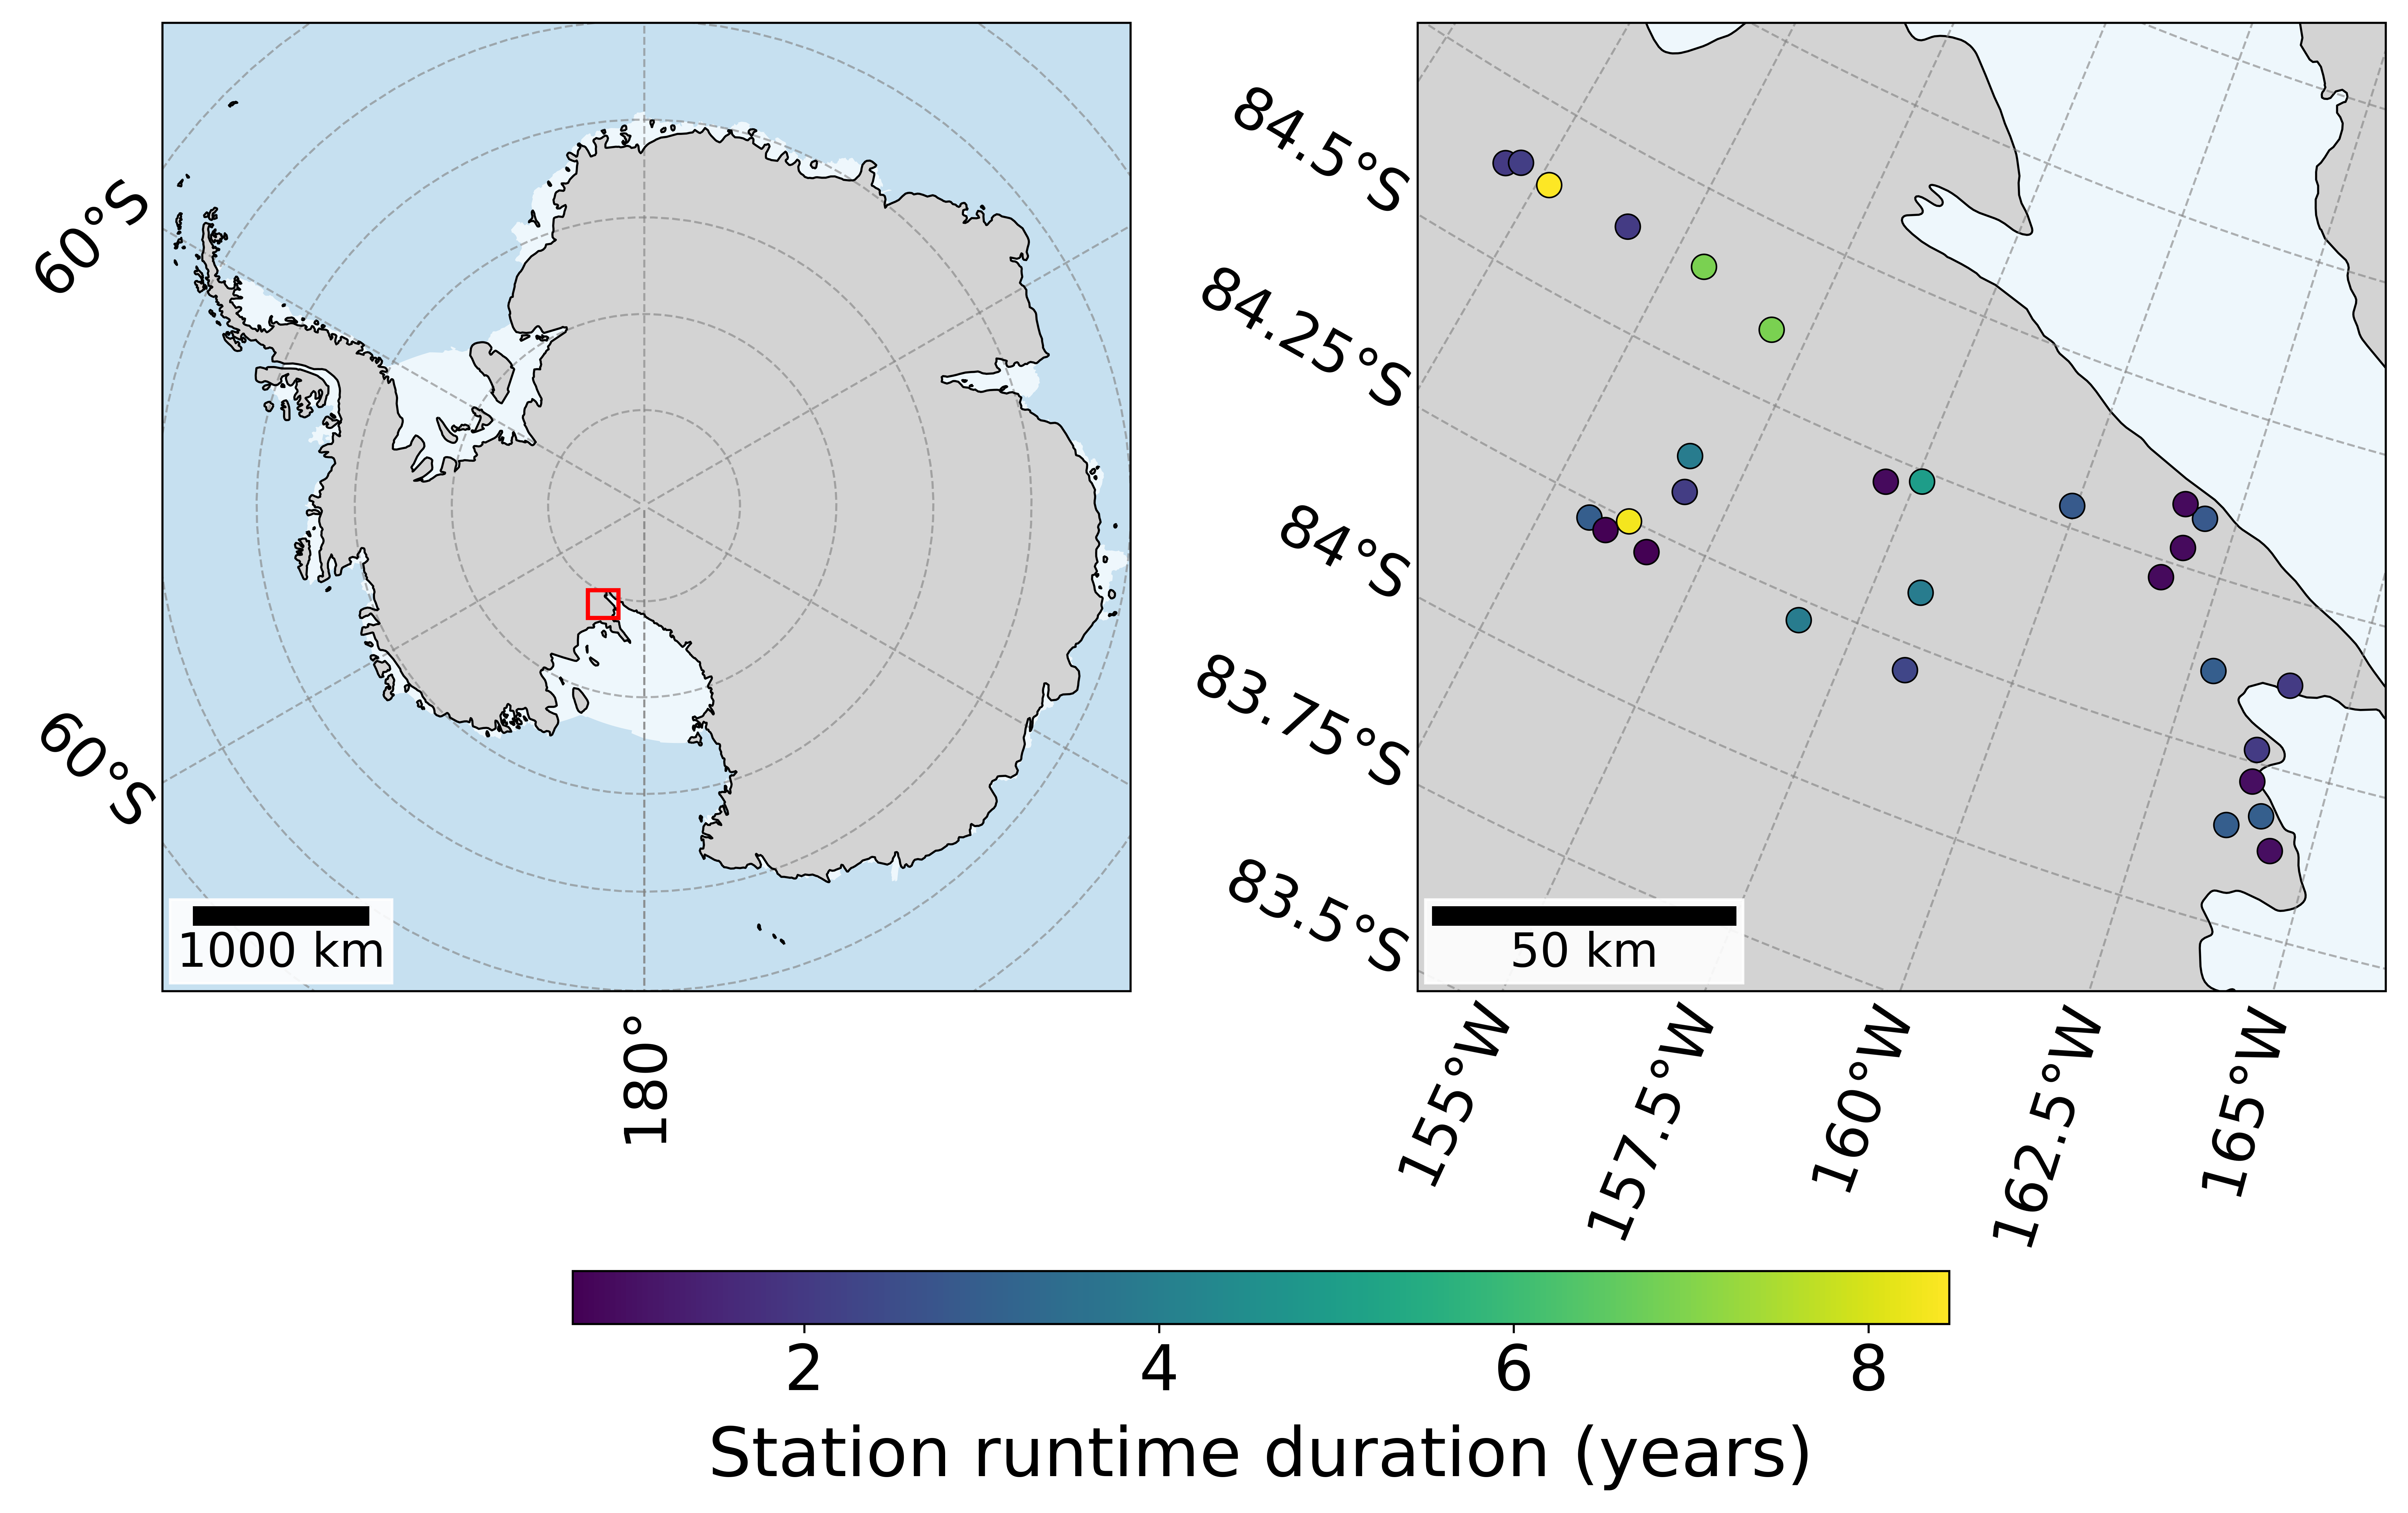

In [4]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
from matplotlib.transforms import ScaledTranslation
from matplotlib_scalebar.scalebar import ScaleBar
from shapely.geometry import box
from shapely.ops import polygonize, unary_union

# These are the 29 stations included in the paper.
STATIONS = [
    "GZ01", "GZ02", "GZ06", "GZ09", "GZ13", "GZ17", "GZ18",
    "LA01", "LA02", "LA03", "LA04", "LA05", "LA06", "LA07", "LA08",
    "LA09", "LA10", "LA11", "LA12", "LA13", "LA14", "LA15", "LA16",
    "LA17", "LA18", "MG04", "MG05", "MG06", "MG07",
]

GNSS_DIR = Path("data/corrected_timeseries")
STATION_COORDINATES = Path("data/antarctica_gnss_station_coordinates.csv")
RINGS_PATH = Path("data/rings/RINGS_grounded_2022_polyline.shp")
FIGURE_DIR = Path("outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CRYOSAT2_START = pd.Timestamp("2010-04-08")
CRYOSAT2_END = pd.Timestamp.today().normalize()

# The corrected files have rounded coordinates, so use the station catalog
# for map locations and the corrected files only for the valid observation dates.
coordinates = pd.read_csv(STATION_COORDINATES).set_index("station")
station_rows = []
for station in STATIONS:
    csv_path = GNSS_DIR / f"{station.lower()}_classified_rh_apc_corrected.csv"
    gnss = pd.read_csv(csv_path, usecols=["YEAR-MM-DD", "daily_filtered_valid"])
    valid = gnss["daily_filtered_valid"].astype(str).str.upper().str.strip().isin(
        ["TRUE", "T", "1"]
    )
    dates = pd.to_datetime(gnss.loc[valid, "YEAR-MM-DD"], errors="coerce").dropna()
    if dates.empty:
        continue

    station_rows.append({
        "station": station,
        "latitude": coordinates.loc[station, "latitude"],
        "longitude": coordinates.loc[station, "longitude"],
        "runtime_start": dates.min().normalize(),
        "runtime_end": dates.max().normalize(),
    })

station_data = pd.DataFrame(station_rows)
station_data["overlap_start"] = station_data["runtime_start"].clip(lower=CRYOSAT2_START)
station_data["overlap_end"] = station_data["runtime_end"].clip(upper=CRYOSAT2_END)
station_data = station_data.loc[
    station_data["overlap_end"] >= station_data["overlap_start"]
].copy()
station_data["overlap_years"] = (
    station_data["overlap_end"] - station_data["overlap_start"]
).dt.days / 365.25

# Project the station locations and make a padded box for the close-up map.
map_crs = ccrs.SouthPolarStereo(central_longitude=0, true_scale_latitude=-71)
station_xy = map_crs.transform_points(
    ccrs.PlateCarree(),
    station_data["longitude"].to_numpy(),
    station_data["latitude"].to_numpy(),
)
station_data["x"] = station_xy[:, 0]
station_data["y"] = station_xy[:, 1]

x_span = station_data["x"].max() - station_data["x"].min()
y_span = station_data["y"].max() - station_data["y"].min()
padding = max(x_span, y_span) * 0.18
x_min = station_data["x"].min() - padding
x_max = station_data["x"].max() + padding
y_min = station_data["y"].min() - padding
y_max = station_data["y"].max() + padding
zoom_box = box(x_min, y_min, x_max, y_max)

# Fill the grounded-ice area inside the RINGS grounding-line outline.
rings = gpd.read_file(RINGS_PATH).to_crs("EPSG:3031")
polygons = list(polygonize(unary_union(rings.geometry)))
grounded = gpd.GeoDataFrame(geometry=polygons, crs="EPSG:3031")
grounded = grounded.loc[
    grounded.geometry.is_valid & ~grounded.geometry.is_empty
].copy()
grounded = grounded.loc[grounded.intersects(zoom_box)].copy()
grounded["geometry"] = grounded.geometry.intersection(zoom_box)
grounded = grounded.loc[~grounded.geometry.is_empty].copy()

# Draw the Antarctica overview and the station close-up side by side.
fig = plt.figure(figsize=(14, 8))
ax_overview = fig.add_subplot(1, 2, 1, projection=map_crs)
ax_zoom = fig.add_subplot(1, 2, 2, projection=map_crs)
fig.subplots_adjust(left=0.09, right=0.98, top=0.95, bottom=0.31, wspace=0.14)
ax_overview.set_box_aspect(1)
ax_zoom.set_box_aspect(1)

ax_overview.set_extent([-180, 180, -90, -65], crs=ccrs.PlateCarree())
ax_overview.add_feature(cfeature.OCEAN, facecolor="#c6e0f0", zorder=0)
ax_overview.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="none", zorder=1)
ax_overview.add_feature(
    cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m"),
    facecolor="#eef7fc", edgecolor="none", zorder=2,
)
ax_overview.add_feature(cfeature.COASTLINE, edgecolor="black", linewidth=0.8, zorder=3)
ax_overview.add_patch(Rectangle(
    (x_min, y_min), x_max - x_min, y_max - y_min,
    transform=map_crs, fill=False, edgecolor="red", linewidth=1.6, zorder=10,
))

ax_zoom.set_extent([x_min, x_max, y_min, y_max], crs=map_crs)
ax_zoom.set_facecolor("#eef7fc")
ax_zoom.add_geometries(
    grounded.geometry, crs=ccrs.epsg(3031), facecolor="lightgray", edgecolor="none", zorder=1,
)
ax_zoom.add_geometries(
    rings.geometry, crs=ccrs.epsg(3031), facecolor="none", edgecolor="black",
    linewidth=0.8, zorder=2,
)

# LA12 and LA17 are close together, so separate their markers by a few points.
nearby_stations = {"LA12": -3, "LA17": 3}
regular = station_data.loc[~station_data["station"].isin(nearby_stations)]
color_norm = mcolors.Normalize(
    vmin=station_data["overlap_years"].min(),
    vmax=station_data["overlap_years"].max(),
)
scatter = ax_zoom.scatter(
    regular["x"], regular["y"], c=regular["overlap_years"], cmap="viridis",
    norm=color_norm, s=90, edgecolor="black", linewidth=0.6,
    transform=map_crs, zorder=3,
)
base_transform = map_crs._as_mpl_transform(ax_zoom)
for station, offset in nearby_stations.items():
    row = station_data.loc[station_data["station"].eq(station)].iloc[0]
    point_transform = base_transform + ScaledTranslation(offset / 72, 0, fig.dpi_scale_trans)
    ax_zoom.scatter(
        [row["x"]], [row["y"]], c=[row["overlap_years"]], cmap="viridis",
        norm=color_norm, s=90, edgecolor="black", linewidth=0.6,
        transform=point_transform, zorder=4,
    )

ax_overview.add_artist(ScaleBar(
    dx=1, units="m", dimension="si-length", fixed_value=1000,
    fixed_units="km", location="lower left", scale_loc="bottom",
    length_fraction=0.25, height_fraction=0.02, pad=0.25,
    border_pad=0.3, sep=2, frameon=True, box_alpha=0.9,
    font_properties={"size": 18},
))
ax_zoom.add_artist(ScaleBar(
    dx=1, units="m", dimension="si-length", fixed_value=50,
    fixed_units="km", location="lower left", scale_loc="bottom",
    length_fraction=0.30, height_fraction=0.02, pad=0.25,
    border_pad=0.3, sep=2, frameon=True, box_alpha=0.9,
    font_properties={"size": 18},
))

for ax in [ax_overview, ax_zoom]:
    grid = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=0.8, color="gray", alpha=0.6, linestyle="--",
    )
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {"size": 22}
    grid.ylabel_style = {"size": 22}
    grid.x_inline = False
    grid.y_inline = False

# Reserve a separate strip under both maps for the runtime color bar.
colorbar_axis = fig.add_axes([0.27, 0.09, 0.52, 0.035])
colorbar = fig.colorbar(scatter, cax=colorbar_axis, orientation="horizontal")
colorbar.set_label("Station runtime duration (years)", fontsize=26, labelpad=8)
colorbar.ax.tick_params(labelsize=24)

out_png = FIGURE_DIR / "antarctica_whillans_29stations_LA12_LA17_offset.png"
fig.savefig(out_png, dpi=600, bbox_inches="tight", pad_inches=0.12, facecolor="white")
plt.show()
plt.close(fig)

station_data[["station", "runtime_start", "runtime_end", "overlap_years"]].sort_values("station")


# Calculate CryoSat-2 minus GNSS bias


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

# Calculate CryoSat-2 minus GNSS bias and its uncertainty for the filtered data.
# Corrected GNSS already includes GNSS - RH + APC, so do not subtract RH again.
# Compare only windows bracketed by valid GNSS days before and after the
# midpoint. Keep unbracketed rows in the audit table with NaN bias values.

# PATHS

# ============================================================

# Set OUT_DIR to the folder for the combined kriging-results CSV.
# Run from the manuscript_scripts folder; intermediate bias output is kept here.
OUT_DIR = Path("outputs")

# Use the manuscript copy of the filtered kriging results.
INTERP_CSV = Path("data/cryosat2_kriging_results.csv")
GNSS_DIR = Path("data/corrected_timeseries")

# Preserve the previous bias file by writing a new swap-labeled file.

OUT_CSV = (
    OUT_DIR
    / "bias_results_all_stations_LA02_LA09_swapped.csv"
)

# ============================================================

# FILTER SETTINGS

# ============================================================

FILTER_PRODUCT = "STD_FILTERED"
STD_THRESHOLD_PCT = 5

# ============================================================

# GNSS COLUMNS

# ============================================================

SURFACE_COLUMN = "Adjusted(m)"
GNSS_UNCERTAINTY_COLUMN = "GNSS_uncertainty_m"
RH_UNCERTAINTY_COLUMN = "RH_uncertainty_m"
STORED_SURFACE_UNCERTAINTY_COLUMN = (
    "Adjusted_uncertainty_m"
)
UNCERTAINTY_CHECK_TOLERANCE_M = 1e-8

# ============================================================

# GNSS STATION MAPPING

#

# The kriging/interpolation station label is NOT changed.

#

# Only the corrected GNSS record used for the bias comparison

# is mapped for LA02 and LA09.

#

#   LA02 interpolation -> LA09 corrected GNSS record

#   LA09 interpolation -> LA02 corrected GNSS record

#

# Every other station uses its same-named corrected GNSS file.

# ============================================================

GNSS_STATION_MAP = {
    "LA02": "LA09",
    "LA09": "LA02",
}

# ============================================================

# INPUT CHECK

# ============================================================

print(
    "[INFO] Using interpolation file:"
)
print(
    f"  {INTERP_CSV}"
)

# ============================================================

# READ INTERPOLATION RESULTS

# ============================================================

interp = pd.read_csv(
    INTERP_CSV,
    low_memory=False,
)
print(
    f"\n[INFO] Raw interpolation rows: "
    f"{len(interp):,}"
)

# ============================================================

# VALIDATE INTERPOLATION COLUMNS

# ============================================================

required_interp_columns = {
    "station",
    "dataset",
    "filter_product",
    "std_threshold_pct",
    "time",
    "w0",
    "w1",
    "krig_est",
    "krig_unc",
}
missing_interp_columns = (
    required_interp_columns
    - set(interp.columns)
)
if missing_interp_columns:
    raise ValueError(
        "Interpolation CSV is missing required columns:\n"
        f"  {sorted(missing_interp_columns)}\n\n"
        "Available columns:\n"
        f"  {interp.columns.tolist()}"
    )

# ============================================================

# CLEAN INTERPOLATION DATA

# ============================================================

interp["station"] = (
    interp["station"]
    .astype(str)
    .str.upper()
    .str.strip()
)
interp["dataset"] = (
    interp["dataset"]
    .astype(str)
    .str.upper()
    .str.strip()
)
interp["filter_product"] = (
    interp["filter_product"]
    .astype(str)
    .str.upper()
    .str.strip()
)
interp["std_threshold_pct"] = pd.to_numeric(
    interp["std_threshold_pct"],
    errors="coerce",
)
interp["krig_est"] = pd.to_numeric(
    interp["krig_est"],
    errors="coerce",
)
interp["krig_unc"] = pd.to_numeric(
    interp["krig_unc"],
    errors="coerce",
)
for column in [
    "time",
    "w0",
    "w1",
]:
    interp[column] = (
        pd.to_datetime(
            interp[column],
            errors="coerce",
            utc=True,
        )
        .dt.tz_localize(None)
    )

# ============================================================

# KEEP ONLY FILTERED DATA PRODUCT

# ============================================================

interp = (
    interp.loc[
        interp["filter_product"].eq(
            FILTER_PRODUCT
        )
        &
        interp["std_threshold_pct"].eq(
            STD_THRESHOLD_PCT
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)
if interp.empty:
    raise RuntimeError(
        "No filtered interpolation rows remain after filtering."
    )
print(
    f"[INFO] Keeping only {FILTER_PRODUCT} "
    f"({STD_THRESHOLD_PCT}%): "
    f"{len(interp):,} rows"
)
print(
    "[INFO] Stations in filtered interpolation file:"
)
print(
    sorted(
        interp["station"]
        .dropna()
        .unique()
        .tolist()
    )
)

# ============================================================

# GNSS FILE LOADER

#

# Adjusted(m) already includes:

#

#   GNSS - RH + APC

#

# This function DOES NOT subtract RH.

# ============================================================

def load_station_gnss(station):
    station = (
        str(station)
        .upper()
        .strip()
    )
    gnss_station = GNSS_STATION_MAP.get(
        station,
        station,
    )
    csv_path = (
        GNSS_DIR
        / (
            f"{gnss_station.lower()}"
            "_classified_rh_apc_corrected.csv"
        )
    )
    if not csv_path.exists():
        raise FileNotFoundError(
            "Corrected GNSS file not found.\n"
            f"Kriging station: {station}\n"
            f"Mapped GNSS station: {gnss_station}\n"
            f"Expected file:\n"
            f"  {csv_path}"
        )
    df = pd.read_csv(
        csv_path,
        low_memory=False,
    )

    # ========================================================

    # REQUIRED COLUMNS

    # ========================================================

    required = {
        SURFACE_COLUMN,
        GNSS_UNCERTAINTY_COLUMN,
        RH_UNCERTAINTY_COLUMN,
    }
    missing = (
        required
        - set(df.columns)
    )
    if missing:
        raise ValueError(
            f"{station}: corrected GNSS CSV is "
            f"missing required columns:\n"
            f"  {sorted(missing)}\n\n"
            f"Mapped GNSS station: {gnss_station}\n"
            f"File:\n"
            f"  {csv_path}"
        )

    # ========================================================

    # DATE COLUMN

    # ========================================================

    if "YEAR-MM-DD" not in df.columns:
        raise ValueError(
            f"{station}: GNSS CSV is missing "
            "the YEAR-MM-DD date column."
        )
    df["date_only"] = (
        pd.to_datetime(
            df["YEAR-MM-DD"],
            errors="coerce",
        )
        .dt.normalize()
    )

    # ========================================================

    # UPSTREAM GNSS SOURCE AUDIT

    # ========================================================

    if "gnss_source_file" in df.columns:
        source_files = df["gnss_source_file"].dropna().astype(str).str.strip()
        source_files = source_files.loc[source_files != ""]
        source_files = sorted(source_files.unique().tolist())
    else:
        source_files = []
    print(
        "\n[GNSS LOAD]"
    )
    print(
        f"  Kriging station:       {station}"
    )
    print(
        f"  Corrected GNSS record: {gnss_station}"
    )
    print(
        f"  Corrected GNSS CSV:    {csv_path}"
    )
    if source_files:
        print(
            "  Upstream GNSS source(s):"
        )
        for source_file in source_files:
            print(
                f"    {source_file}"
            )
    else:
        print(
            "  Upstream GNSS source:  "
            "not recorded in CSV"
        )

    # ========================================================

    # FINAL SURFACE ELEVATION

    #

    # DO NOT SUBTRACT RH HERE.

    #

    # Adjusted(m) is already:

    #

    #   GNSS - RH + APC

    # ========================================================

    df["surface_elevation"] = pd.to_numeric(
        df[SURFACE_COLUMN],
        errors="coerce",
    )

    # ========================================================

    # DAILY UNCERTAINTIES

    # ========================================================

    df["sigma_gnss"] = pd.to_numeric(
        df[GNSS_UNCERTAINTY_COLUMN],
        errors="coerce",
    )
    df["sigma_rh"] = pd.to_numeric(
        df[RH_UNCERTAINTY_COLUMN],
        errors="coerce",
    )

    # ========================================================

    # PROPAGATED DAILY SURFACE UNCERTAINTY

    #

    # sigma_surface(d) =

    #

    # sqrt(

    #     sigma_GNSS(d)^2

    #     +

    #     sigma_RH(d)^2

    # )

    # ========================================================

    df["sigma_surface_daily"] = np.sqrt(
        df["sigma_gnss"] ** 2
        +
        df["sigma_rh"] ** 2
    )

    # ========================================================

    # CHECK AGAINST STORED Adjusted_uncertainty_m

    # ========================================================

    if (
        STORED_SURFACE_UNCERTAINTY_COLUMN
        in df.columns
    ):
        df[
            "sigma_surface_stored"
        ] = pd.to_numeric(
            df[
                STORED_SURFACE_UNCERTAINTY_COLUMN
            ],
            errors="coerce",
        )
        check_mask = (
            np.isfinite(
                df["sigma_surface_daily"]
            )
            &
            np.isfinite(
                df["sigma_surface_stored"]
            )
        )
        if check_mask.any():
            max_difference = float(
                np.max(
                    np.abs(
                        df.loc[
                            check_mask,
                            "sigma_surface_daily",
                        ]
                        -
                        df.loc[
                            check_mask,
                            "sigma_surface_stored",
                        ]
                    )
                )
            )
            if (
                max_difference
                >
                UNCERTAINTY_CHECK_TOLERANCE_M
            ):
                print(
                    f"[WARNING] {station}: "
                    "recalculated daily surface uncertainty "
                    "does not exactly match "
                    "Adjusted_uncertainty_m."
                )
                print(
                    f"          Max difference = "
                    f"{max_difference:.12g} m"
                )

    # ========================================================

    # DAILY RH VALIDITY FLAG

    # ========================================================

    if "daily_filtered_valid" in df.columns:
        valid_string = (
            df["daily_filtered_valid"]
            .astype(str)
            .str.upper()
            .str.strip()
        )
        daily_valid = valid_string.isin(
            [
                "TRUE",
                "T",
                "1",
            ]
        )
    else:
        daily_valid = pd.Series(
            True,
            index=df.index,
        )

    # ========================================================

    # FINAL VALID DAILY SURFACE RECORD

    # ========================================================

    valid = (
        df["date_only"].notna()
        &
        np.isfinite(
            df["surface_elevation"]
        )
        &
        np.isfinite(
            df["sigma_surface_daily"]
        )
        &
        df["sigma_surface_daily"].ge(0)
        &
        daily_valid
    )
    df = (
        df.loc[
            valid,
            [
                "date_only",
                "surface_elevation",
                "sigma_gnss",
                "sigma_rh",
                "sigma_surface_daily",
            ],
        ]
        .sort_values(
            "date_only"
        )
        .reset_index(
            drop=True
        )
    )
    print(
        f"  Valid daily surface estimates: "
        f"{len(df):,}"
    )
    return {
        "data": df,
        "station": station,
        "gnss_station": gnss_station,
        "corrected_csv": str(csv_path),
        "source_files": source_files,
    }

# ============================================================

# LOAD EACH GNSS RECORD ONCE

# ============================================================

stations = sorted(
    interp[
        "station"
    ]
    .dropna()
    .unique()
    .tolist()
)
gnss_by_station = {}
print(
    "\n========================================"
)
print(
    "LOADING FINAL RH + APC CORRECTED GNSS RECORDS"
)
print(
    "========================================"
)
for station in stations:
    try:
        gnss_by_station[
            station
        ] = load_station_gnss(
            station
        )
    except Exception as error:
        print(
            f"\n[GNSS ERROR] {station}: "
            f"{type(error).__name__}: "
            f"{error}"
        )

# ============================================================

# LA02 / LA09 MAPPED-GNSS AUDIT

# ============================================================

print(
    "\n========================================"
)
print(
    "LA02 / LA09 MAPPED GNSS FILE CHECK"
)
print(
    "========================================"
)
for station in [
    "LA02",
    "LA09",
]:
    if station not in stations:
        print(
            f"{station}: no interpolation rows"
        )
        continue
    mapped_gnss_station = (
        GNSS_STATION_MAP.get(
            station,
            station,
        )
    )
    expected_file = (
        GNSS_DIR
        / (
            f"{mapped_gnss_station.lower()}"
            "_classified_rh_apc_corrected.csv"
        )
    )
    print(
        f"{station} kriging -> "
        f"{mapped_gnss_station} GNSS -> "
        f"{expected_file.name}"
    )

# ============================================================

# CALCULATE BIAS FOR EACH INTERPOLATION WINDOW

# ============================================================

print(
    "\n========================================"
)
print(
    "CALCULATING filtered BIAS + UNCERTAINTY"
)
print(
    "========================================"
)
bias_rows = []
for _, row in interp.iterrows():
    station = row["station"]
    result = row.to_dict()
    mapped_gnss_station = (
        GNSS_STATION_MAP.get(
            station,
            station,
        )
    )
    result.update(
        {
            "gnss_station_used": (
                mapped_gnss_station
            ),
"gnss_mean": np.nan,
            "gnss_median": np.nan,
            "n_gnss_days": 0,
            "has_gnss_before_interp": False,
            "has_gnss_after_interp": False,
            "nearest_gnss_before_date": pd.NaT,
            "nearest_gnss_after_date": pd.NaT,
            "days_to_nearest_gnss_before": np.nan,
            "days_to_nearest_gnss_after": np.nan,
            "gnss_window_unc": np.nan,
            "mean_daily_gnss_unc": np.nan,
            "mean_daily_rh_unc": np.nan,
            "mean_daily_surface_unc": np.nan,
            "bias": np.nan,
            "bias_unc": np.nan,
            "bias_weight": np.nan,
            "bias_status": "",
        }
    )

    # --------------------------------------------------------

    # GNSS record loaded?

    # --------------------------------------------------------

    if station not in gnss_by_station:
        result["bias_status"] = (
            "missing_gnss_file"
        )
        bias_rows.append(
            result
        )
        continue
    gnss_info = gnss_by_station[
        station
    ]
    gnss = gnss_info[
        "data"
    ]
    result["gnss_station_used"] = (
        gnss_info["gnss_station"]
    )
    result["gnss_corrected_csv"] = gnss_info["corrected_csv"]
    result["gnss_source_file"] = "; ".join(gnss_info["source_files"])

    # --------------------------------------------------------

    # Valid interpolation?

    # --------------------------------------------------------

    if (
        not np.isfinite(
            row["krig_est"]
        )
        or
        not np.isfinite(
            row["krig_unc"]
        )
    ):
        result["bias_status"] = (
            "invalid_kriging_result"
        )
        bias_rows.append(
            result
        )
        continue
    if row["krig_unc"] < 0:
        result["bias_status"] = (
            "negative_kriging_uncertainty"
        )
        bias_rows.append(
            result
        )
        continue

    # --------------------------------------------------------

    # Valid interpolation window?

    # --------------------------------------------------------

    if (
        pd.isna(
            row["time"]
        )
        or
        pd.isna(
            row["w0"]
        )
        or
        pd.isna(
            row["w1"]
        )
    ):
        result["bias_status"] = (
            "invalid_window_dates"
        )
        bias_rows.append(
            result
        )
        continue
    w0 = (
        pd.Timestamp(
            row["w0"]
        )
        .normalize()
    )
    w1 = (
        pd.Timestamp(
            row["w1"]
        )
        .normalize()
    )
    interp_date = (
        pd.Timestamp(
            row["time"]
        )
        .normalize()
    )
    if not (
        w0
        <= interp_date
        <= w1
    ):
        result["bias_status"] = (
            "interp_date_outside_window"
        )
        bias_rows.append(
            result
        )
        continue

    # --------------------------------------------------------

    # GNSS values inside interpolation window

    # --------------------------------------------------------

    gnss_window = (
        gnss.loc[
            gnss["date_only"].between(
                w0,
                w1,
                inclusive="both",
            )
        ]
        .copy()
    )
    if gnss_window.empty:
        result["bias_status"] = (
            "no_valid_gnss_in_window"
        )
        bias_rows.append(
            result
        )
        continue

    # ========================================================

    # TEMPORAL GNSS BRACKETING CHECK

    #

    # Require at least one valid GNSS day strictly before the

    # interpolation date and at least one valid GNSS day strictly

    # after the interpolation date, both within [w0, w1].

    #

    # A GNSS observation exactly on interp_date does not satisfy

    # either side of the requirement.

    # ========================================================

    gnss_before = (
        gnss_window.loc[
            gnss_window["date_only"]
            < interp_date
        ]
        .copy()
    )
    gnss_after = (
        gnss_window.loc[
            gnss_window["date_only"]
            > interp_date
        ]
        .copy()
    )
    has_before = (
        not gnss_before.empty
    )
    has_after = (
        not gnss_after.empty
    )
    result["has_gnss_before_interp"] = (
        has_before
    )
    result["has_gnss_after_interp"] = (
        has_after
    )
    if has_before:
        nearest_before = (
            gnss_before["date_only"]
            .max()
        )
        result["nearest_gnss_before_date"] = (
            nearest_before
        )
        result["days_to_nearest_gnss_before"] = (
            interp_date
            - nearest_before
        ).days
    if has_after:
        nearest_after = (
            gnss_after["date_only"]
            .min()
        )
        result["nearest_gnss_after_date"] = (
            nearest_after
        )
        result["days_to_nearest_gnss_after"] = (
            nearest_after
            - interp_date
        ).days
    if not (
        has_before
        and has_after
    ):
        result["n_gnss_days"] = int(
            len(
                gnss_window
            )
        )
        result["bias_status"] = (
            "missing_gnss_temporal_bracketing"
        )
        bias_rows.append(
            result
        )
        continue

    # ========================================================

    # WINDOW-MEAN GNSS-DERIVED SURFACE

    #

    # surface_elevation is Adjusted(m).

    #

    # RH has ALREADY been subtracted upstream.

    #

    # APC has ALREADY been applied upstream.

    # ========================================================

    surface = (
        gnss_window[
            "surface_elevation"
        ]
        .to_numpy(
            dtype=float
        )
    )
    sigma_daily = (
        gnss_window[
            "sigma_surface_daily"
        ]
        .to_numpy(
            dtype=float
        )
    )
    n_days = int(
        len(
            surface
        )
    )
    if n_days == 0:
        result["bias_status"] = (
            "no_valid_gnss_in_window"
        )
        bias_rows.append(
            result
        )
        continue
    gnss_mean = float(
        np.mean(
            surface
        )
    )
    gnss_median = float(
        np.median(
            surface
        )
    )

    # ========================================================

    # UNCERTAINTY OF WINDOW-MEAN GNSS SURFACE

    # ========================================================

    gnss_window_unc = float(
        np.sqrt(
            np.sum(
                sigma_daily ** 2
            )
        )
        /
        n_days
    )

    # ========================================================

    # BIAS

    #

    # bias = interpolated satellite - GNSS-derived surface

    # ========================================================

    bias = float(
        row["krig_est"]
        -
        gnss_mean
    )

    # ========================================================

    # BIAS UNCERTAINTY

    # ========================================================

    bias_unc = float(
        np.sqrt(
            row["krig_unc"] ** 2
            +
            gnss_window_unc ** 2
        )
    )

    # ========================================================

    # INVERSE-VARIANCE WEIGHT

    # ========================================================

    if (
        np.isfinite(
            bias_unc
        )
        and
        bias_unc > 0
    ):
        bias_weight = float(
            1.0
            /
            (
                bias_unc ** 2
            )
        )
    else:
        bias_weight = np.nan

    # ========================================================

    # SAVE RESULT

    # ========================================================

    result.update(
        {
            "gnss_mean": (
                gnss_mean
            ),
            "gnss_median": (
                gnss_median
            ),
            "n_gnss_days": (
                n_days
            ),
            "gnss_window_unc": (
                gnss_window_unc
            ),
            "mean_daily_gnss_unc": float(
                gnss_window[
                    "sigma_gnss"
                ].mean()
            ),
            "mean_daily_rh_unc": float(
                gnss_window[
                    "sigma_rh"
                ].mean()
            ),
            "mean_daily_surface_unc": float(
                gnss_window[
                    "sigma_surface_daily"
                ].mean()
            ),
            "bias": (
                bias
            ),
            "bias_unc": (
                bias_unc
            ),
            "bias_weight": (
                bias_weight
            ),
            "bias_status": (
                "success"
            ),
        }
    )
    bias_rows.append(
        result
    )

# ============================================================

# COMBINE

# ============================================================

bias_df = pd.DataFrame(
    bias_rows
)
if len(bias_df) != len(interp):
    raise RuntimeError(
        "Bias output row count does not match "
        "filtered interpolation input row count."
    )

# ============================================================

# SORT

# ============================================================

bias_df = (
    bias_df
    .sort_values(
        [
            "station",
            "dataset",
            "time",
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================

# VERIFY ONLY filtered DATA ARE PRESENT

# ============================================================

bad_filter_rows = (
    ~bias_df[
        "filter_product"
    ].eq(
        FILTER_PRODUCT
    )
    |
    ~bias_df[
        "std_threshold_pct"
    ].eq(
        STD_THRESHOLD_PCT
    )
)
if bad_filter_rows.any():
    raise RuntimeError(
        "Unfiltered rows unexpectedly reached the "
        "bias output."
    )
print(
    "\n[CHECK] Output contains only:"
)
print(
    bias_df[
        [
            "filter_product",
            "std_threshold_pct",
        ]
    ]
    .drop_duplicates()
    .to_string(
        index=False
    )
)

# ============================================================

# VERIFY LA02 / LA09 REQUIRED GNSS MAPPING

# ============================================================

la_check = (
    bias_df.loc[
        bias_df[
            "station"
        ].isin(
            [
                "LA02",
                "LA09",
            ]
        ),
        [
            "station",
            "gnss_station_used",
            "gnss_corrected_csv",
            "gnss_source_file",
],
    ]
    .drop_duplicates()
    .sort_values(
        "station"
    )
)
print(
    "\n========================================"
)
print(
    "FINAL LA02 / LA09 SOURCE CHECK"
)
print(
    "========================================"
)
print(
    la_check.to_string(
        index=False
    )
)
expected_identity = {
    "LA02": "LA09",
    "LA09": "LA02",
}
for kriging_station, gnss_station in (
    expected_identity.items()
):
    check = (
        la_check.loc[
            la_check[
                "station"
            ].eq(
                kriging_station
            ),
            "gnss_station_used",
        ]
    )
    if not check.empty:
        if not check.eq(
            gnss_station
        ).all():
            raise RuntimeError(
                f"GNSS identity check failed for "
                f"{kriging_station}. "
                f"Expected mapped corrected GNSS "
                f"record {gnss_station}."
            )

# ============================================================

# SAVE

# ============================================================

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
bias_df.to_csv(
    OUT_CSV,
    index=False,
)

# ============================================================

# SUMMARY

# ============================================================

print(
    "\n========================================"
)
print(
    "BIAS CALCULATION SUMMARY"
)
print(
    "========================================"
)
print(
    f"[INFO] filtered interpolation rows: "
    f"{len(interp):,}"
)
print(
    f"[INFO] Successful bias estimates: "
    f"{(bias_df['bias_status'] == 'success').sum():,}"
)
print(
    f"[INFO] Failed bias estimates: "
    f"{(bias_df['bias_status'] != 'success').sum():,}"
)
print(
    "\n[INFO] Status:"
)
print(
    bias_df[
        "bias_status"
    ]
    .value_counts(
        dropna=False
    )
)
n_bracketing_failed = int(
    (
        bias_df["bias_status"]
        == "missing_gnss_temporal_bracketing"
    ).sum()
)
print(
    f"\n[INFO] Comparisons dropped for missing GNSS "
    f"temporal bracketing: {n_bracketing_failed:,}"
)

# ============================================================

# SUCCESSFUL RESULTS

# ============================================================

success_df = (
    bias_df.loc[
        bias_df[
            "bias_status"
        ]
        == "success"
    ]
    .copy()
)
print(
    "\n[INFO] Successful estimates by dataset:"
)
print(
    success_df.groupby(
        "dataset"
    )
    .size()
    .rename(
        "n_bias"
    )
)

# ============================================================

# UNWEIGHTED SUMMARY

# ============================================================

unweighted_summary = (
    success_df
    .groupby(
        "dataset"
    )["bias"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
        ]
    )
)
print(
    "\n[INFO] Unweighted bias summary:"
)
print(
    unweighted_summary
)

# ============================================================

# WEIGHTED SUMMARY

#

# This is an all-window diagnostic.

# It is NOT the de-overlapped static manuscript mean.

# ============================================================

weighted_rows = []
for dataset, group in (
    success_df.groupby(
        "dataset"
    )
):
    valid = group.loc[
        np.isfinite(
            group["bias"]
        )
        &
        np.isfinite(
            group["bias_unc"]
        )
        &
        group["bias_unc"].gt(0)
    ].copy()
    if valid.empty:
        continue
    weights = (
        1.0
        /
        (
            valid["bias_unc"]
            ** 2
        )
    )
    weighted_mean = float(
        np.sum(
            weights
            *
            valid["bias"]
        )
        /
        np.sum(
            weights
        )
    )
    weighted_unc = float(
        np.sqrt(
            1.0
            /
            np.sum(
                weights
            )
        )
    )
    weighted_rows.append(
        {
            "dataset": dataset,
            "filter_product": FILTER_PRODUCT,
            "std_threshold_pct": STD_THRESHOLD_PCT,
            "n": len(valid),
            "weighted_mean_bias": weighted_mean,
            "weighted_mean_unc": weighted_unc,
        }
    )
weighted_summary = pd.DataFrame(
    weighted_rows
)
print(
    "\n[INFO] Weighted bias diagnostic "
    "(all filtered windows):"
)
print(
    weighted_summary
)

# ============================================================

# OUTPUT

# ============================================================

print(
    "\n[INFO] Wrote:"
)
print(
    f"  {OUT_CSV}"
)

# ============================================================

# LEAVE TABLE AVAILABLE

# ============================================================

bias_df


[INFO] Using interpolation file:
  data/cryosat2_kriging_results.csv

[INFO] Raw interpolation rows: 2,094
[INFO] Keeping only STD_FILTERED (5%): 2,094 rows
[INFO] Stations in filtered interpolation file:
['GZ01', 'GZ02', 'GZ06', 'GZ09', 'GZ13', 'GZ17', 'GZ18', 'LA01', 'LA02', 'LA03', 'LA04', 'LA05', 'LA06', 'LA07', 'LA08', 'LA09', 'LA10', 'LA11', 'LA12', 'LA13', 'LA14', 'LA15', 'LA16', 'LA17', 'LA18', 'MG04', 'MG05', 'MG06', 'MG07']

LOADING FINAL RH + APC CORRECTED GNSS RECORDS

[GNSS LOAD]
  Kriging station:       GZ01
  Corrected GNSS record: GZ01
  Corrected GNSS CSV:    data/corrected_timeseries/gz01_classified_rh_apc_corrected.csv
  Upstream GNSS source:  not recorded in CSV
  Valid daily surface estimates: 1,062

[GNSS LOAD]
  Kriging station:       GZ02
  Corrected GNSS record: GZ02
  Corrected GNSS CSV:    data/corrected_timeseries/gz02_classified_rh_apc_corrected.csv
  Upstream GNSS source:  not recorded in CSV
  Valid daily surface estimates: 748

[GNSS LOAD]
  Kriging stat


[CHECK] Output contains only:
filter_product  std_threshold_pct
  STD_FILTERED                  5

FINAL LA02 / LA09 SOURCE CHECK
station gnss_station_used                                             gnss_corrected_csv gnss_source_file
   LA02              LA09 data/corrected_timeseries/la09_classified_rh_apc_corrected.csv                 
   LA09              LA02 data/corrected_timeseries/la02_classified_rh_apc_corrected.csv                 

BIAS CALCULATION SUMMARY
[INFO] filtered interpolation rows: 2,094
[INFO] Successful bias estimates: 1,983
[INFO] Failed bias estimates: 111

[INFO] Status:
bias_status
success                             1983
no_valid_gnss_in_window               69
missing_gnss_temporal_bracketing      42
Name: count, dtype: int64

[INFO] Comparisons dropped for missing GNSS temporal bracketing: 42

[INFO] Successful estimates by dataset:
dataset
MISWIS    661
POCA      661
SWATH     661
Name: n_bias, dtype: int64

[INFO] Unweighted bias summary:
         cou

,task_id,worker_pid,station,dataset,filter_product,std_threshold_pct,value_column,time,w0,w1,...,gnss_window_unc,mean_daily_gnss_unc,mean_daily_rh_unc,mean_daily_surface_unc,bias,bias_unc,bias_weight,bias_status,gnss_corrected_csv,gnss_source_file
0,17,85500,GZ01,MISWIS,STD_FILTERED,5,h_r1,2011-02-25,2011-01-11 02:23:01.436506,2011-04-11 02:23:01.436506,...,0.009045,0.022262,0.082457,0.085478,0.224729,1.058289,0.892877,success,data/corrected_timeseries/gz01_classified_rh_a...,
1,18,85495,GZ01,MISWIS,STD_FILTERED,5,h_r1,2011-07-25,2011-06-10 02:23:01.436506,2011-09-08 02:23:01.436506,...,0.009239,0.024481,0.083055,0.086701,-0.729209,0.691504,2.091275,success,data/corrected_timeseries/gz01_classified_rh_a...,
2,19,85496,GZ01,MISWIS,STD_FILTERED,5,h_r1,2011-10-23,2011-09-08 02:23:01.436506,2011-12-07 02:23:01.436506,...,0.008176,0.025462,0.072493,0.077145,0.063526,2.027125,0.243354,success,data/corrected_timeseries/gz01_classified_rh_a...,
3,20,85499,GZ01,MISWIS,STD_FILTERED,5,h_r1,2012-01-21,2011-12-07 02:23:01.436506,2012-03-06 02:23:01.436506,...,0.007967,0.022980,0.071632,0.075306,-0.396300,0.753366,1.761927,success,data/corrected_timeseries/gz01_classified_rh_a...,
4,21,85497,GZ01,MISWIS,STD_FILTERED,5,h_r1,2012-03-21,2012-02-05 02:23:01.436506,2012-05-05 02:23:01.436506,...,0.009589,0.024032,0.087138,0.090487,-0.487665,0.305568,10.709883,success,data/corrected_timeseries/gz01_classified_rh_a...,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2089,4698,85498,MG07,SWATH,STD_FILTERED,5,elevation,2014-06-11,2014-04-27 04:31:05.887248,2014-07-26 04:31:05.887248,...,0.008970,0.025690,0.081118,0.085136,-2.004665,0.299501,11.148192,success,data/corrected_timeseries/mg07_classified_rh_a...,
2090,4699,85494,MG07,SWATH,STD_FILTERED,5,elevation,2014-07-11,2014-05-27 04:31:05.887248,2014-08-25 04:31:05.887248,...,0.009200,0.025256,0.083582,0.087351,-1.820901,0.293196,11.632791,success,data/corrected_timeseries/mg07_classified_rh_a...,
2091,4700,85495,MG07,SWATH,STD_FILTERED,5,elevation,2014-08-10,2014-06-26 04:31:05.887248,2014-09-24 04:31:05.887248,...,0.009229,0.025152,0.083888,0.087617,-1.415795,0.305510,10.713920,success,data/corrected_timeseries/mg07_classified_rh_a...,
2092,4701,85500,MG07,SWATH,STD_FILTERED,5,elevation,2014-09-09,2014-07-26 04:31:05.887248,2014-10-24 04:31:05.887248,...,0.010034,0.025732,0.091029,0.094715,-1.579996,0.308336,10.518433,success,data/corrected_timeseries/mg07_classified_rh_a...,


# Summarize non-overlapping bias windows


[INFO] Loaded:
  outputs/bias_results_all_stations_LA02_LA09_swapped.csv
[INFO] Input rows: 2,094

[CHECK] Input filter product:
filter_product  std_threshold_pct
  STD_FILTERED                  5

[CHECK] PASS: retained original 1,4,7,... windows contain no true calendar-day overlap.

NON-OVERLAPPING WINDOW SELECTION
ORIGINAL WINDOW SEQUENCE PRESERVED
[INFO] Original eligible filtered windows: 2,094
[INFO] Successful bias estimates across all windows: 1,983
[INFO] Original 1,4,7,... phase windows: 732
[INFO] Successful retained non-overlap windows: 699
[INFO] Retained-phase windows removed because bias was not successful/finite: 33

[INFO] Status of ORIGINAL 1,4,7,... phase windows:
bias_status
success                             699
no_valid_gnss_in_window              21
missing_gnss_temporal_bracketing     12
Name: count, dtype: int64

[INFO] Successful retained counts by dataset:
dataset
MISWIS    233
POCA      233
SWATH     233
dtype: int64

[INFO] Successful retained station cou

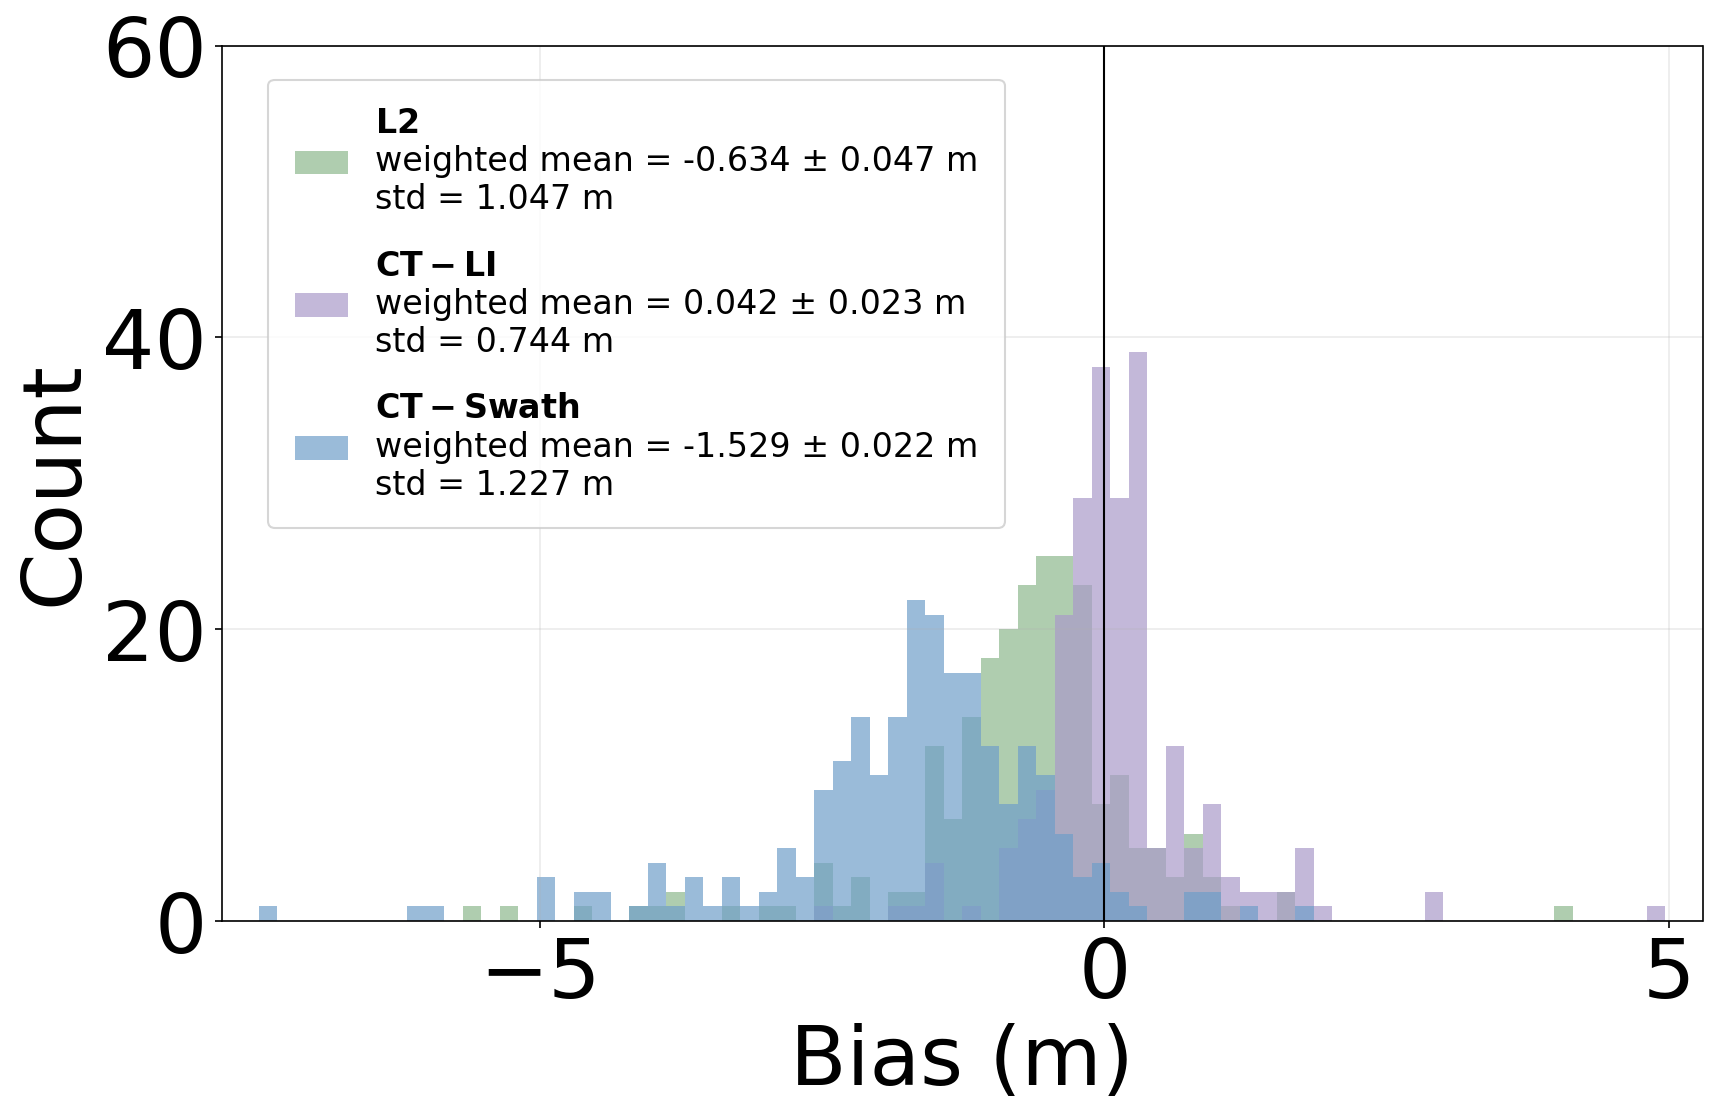


COMPLETE

[INFO] Retained non-overlapping bias CSV:
  outputs/bias_nonoverlapping_windows_LA02_LA09_swapped.csv

[INFO] Global summary CSV:
  outputs/bias_global_summary_nonoverlapping_LA02_LA09_swapped.csv

[INFO] Figure:
  outputs/figures/GLOBAL_bias_hist_nonoverlap_LA02_LA09_swapped.png


,filter_product,std_threshold_pct,dataset,dataset_label,N,n_stations,weighted_mean_bias_m,weighted_mean_unc_m,mean_bias_m,median_bias_m,std_bias_m
0,STD_FILTERED,5,MISWIS,L2,233,29,-0.633669,0.047487,-0.704751,-0.598825,1.046938
1,STD_FILTERED,5,POCA,CT-LI,233,29,0.042368,0.022631,0.126644,0.045798,0.744011
2,STD_FILTERED,5,SWATH,CT-Swath,233,29,-1.529461,0.022215,-1.692768,-1.558851,1.226993


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Summarize and plot the bias results using non-overlapping windows.
# Select windows 1, 4, 7, ... from each original station/dataset sequence
# before dropping failed comparisons; this keeps the intended phase.
# Use that same retained subset for the histogram and summary statistics.

# INPUT / OUTPUT

# ============================================================

# Set BIAS_CSV to the bias-results CSV produced by the calculation cell above.
# Precomputed paper bias results bundled with this repository.
BIAS_CSV = Path("outputs/bias_results_all_stations_LA02_LA09_swapped.csv")
RESULTS_DIR = Path("outputs")
FIGURE_DIR = Path("outputs/figures")
RETAINED_OUT_CSV = (
    RESULTS_DIR
    / "bias_nonoverlapping_windows_LA02_LA09_swapped.csv"
)
SUMMARY_OUT_CSV = (
    RESULTS_DIR
    / "bias_global_summary_nonoverlapping_LA02_LA09_swapped.csv"
)

# ============================================================

# FIGURE SETTINGS

# ============================================================

BINS = 80
FIGSIZE = (12, 8)
HIST_ALPHA = 0.70
FONT_SCALE = 1.8
SAVE_DPI = 600

# ============================================================

# FILTER PRODUCT

# ============================================================

FILTER_PRODUCT = "STD_FILTERED"
STD_THRESHOLD_PCT = 5
FILE_TAG = "LA02_LA09_swapped"

# ============================================================

# EXCLUSIONS

# ============================================================

EXCLUDE_STATIONS = set()
EXCLUDE_DATASETS = {
    "N",
}

# ============================================================

# DATASET ORDER

# ============================================================

DESIRED_ORDER = [
    "MISWIS",
    "POCA",
    "SWATH",
]

# ============================================================

# REQUIRE SHARED SETTINGS

# ============================================================

required_shared_settings = [
    "LEGEND_FONTSIZE",
    "TICK_FONTSIZE",
    "DATASET_LABEL_MAP",
    "DATASET_COLOR_MAP",
]

# Check that the shared style cell has been run before making the plots.
missing_shared_settings = []
for name in required_shared_settings:
    if name not in globals():
        missing_shared_settings.append(name)
if missing_shared_settings:
    raise RuntimeError(
        "Run the shared settings cell first. "
        f"Missing: {missing_shared_settings}"
    )

# ============================================================

# NORMALIZE SHARED SETTINGS

# ============================================================

# Normalize the names once so the plotting code can look them up consistently.
_DATASET_LABEL_MAP_NORMALIZED = {}
for key, value in DATASET_LABEL_MAP.items():
    normalized_key = str(key).upper().strip()
    _DATASET_LABEL_MAP_NORMALIZED[normalized_key] = value
_DATASET_COLOR_MAP_NORMALIZED = {}
for key, value in DATASET_COLOR_MAP.items():
    normalized_key = str(key).upper().strip()
    _DATASET_COLOR_MAP_NORMALIZED[normalized_key] = value
plt.rcParams["figure.dpi"] = 150

# ============================================================

# HELPERS

# ============================================================

def _finite(values):
    values = np.asarray(
        values,
        dtype=float,
    )
    return values[
        np.isfinite(values)
    ]

def _clean_dataset_name(dataset):
    return (
        str(dataset)
        .upper()
        .strip()
    )

def _display_dataset_label(dataset):
    dataset = _clean_dataset_name(
        dataset
    )
    return _DATASET_LABEL_MAP_NORMALIZED.get(
        dataset,
        dataset,
    )

def _dataset_color(dataset):
    dataset = _clean_dataset_name(
        dataset
    )
    if dataset in _DATASET_COLOR_MAP_NORMALIZED:
        return _DATASET_COLOR_MAP_NORMALIZED[
            dataset
        ]
    display_name = (
        str(
            _display_dataset_label(
                dataset
            )
        )
        .upper()
        .strip()
    )
    if display_name in _DATASET_COLOR_MAP_NORMALIZED:
        return _DATASET_COLOR_MAP_NORMALIZED[
            display_name
        ]
    raise KeyError(
        f"No color defined for dataset {dataset!r}."
    )

def _bold_mathtext_label(text):
    text = (
        str(text)
        .replace(
            " ",
            r"\ ",
        )
    )
    return rf"$\mathbf{{{text}}}$"

# ============================================================

# LOAD BIAS RECORD

# ============================================================

bias_df = pd.read_csv(
    BIAS_CSV,
    low_memory=False,
)
print(
    "[INFO] Loaded:"
)
print(
    f"  {BIAS_CSV}"
)
print(
    f"[INFO] Input rows: "
    f"{len(bias_df):,}"
)

# ============================================================

# VALIDATE REQUIRED COLUMNS

# ============================================================

required_columns = {
    "station",
    "dataset",
    "filter_product",
    "std_threshold_pct",
    "time",
    "w0",
    "w1",
    "bias",
    "bias_unc",
    "bias_status",
}
missing_columns = (
    required_columns
    - set(
        bias_df.columns
    )
)
if missing_columns:
    raise ValueError(
        "Bias CSV is missing required columns:\n"
        f"  {sorted(missing_columns)}"
    )

# ============================================================

# CLEAN

# ============================================================

bias_df["station"] = (
    bias_df["station"]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df["dataset"] = (
    bias_df["dataset"]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df["filter_product"] = (
    bias_df["filter_product"]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df["bias_status"] = (
    bias_df["bias_status"]
    .astype(str)
    .str.lower()
    .str.strip()
)
bias_df["std_threshold_pct"] = pd.to_numeric(
    bias_df["std_threshold_pct"],
    errors="coerce",
)
bias_df["bias"] = pd.to_numeric(
    bias_df["bias"],
    errors="coerce",
)
bias_df["bias_unc"] = pd.to_numeric(
    bias_df["bias_unc"],
    errors="coerce",
)
for column in [
    "time",
    "w0",
    "w1",
]:
    bias_df[column] = (
        pd.to_datetime(
            bias_df[column],
            errors="coerce",
            utc=True,
        )
        .dt.tz_localize(
            None
        )
    )

# ============================================================

# VERIFY THIS IS THE filtered PRODUCT

# ============================================================

unexpected_filter = (
    ~bias_df[
        "filter_product"
    ].eq(
        FILTER_PRODUCT
    )
    |
    ~bias_df[
        "std_threshold_pct"
    ].eq(
        STD_THRESHOLD_PCT
    )
)
if unexpected_filter.any():
    unexpected = (
        bias_df.loc[
            unexpected_filter,
            [
                "filter_product",
                "std_threshold_pct",
            ],
        ]
        .drop_duplicates()
    )
    print(
        unexpected
    )
    raise RuntimeError(
        "Bias input contains rows other than "
        "the expected filter product."
    )
print(
    "\n[CHECK] Input filter product:"
)
print(
    bias_df[
        [
            "filter_product",
            "std_threshold_pct",
        ]
    ]
    .drop_duplicates()
    .to_string(
        index=False
    )
)

# ============================================================

# ORIGINAL filtered WINDOW POPULATION

#

# IMPORTANT:

# Do NOT filter on bias_status here.

#

# These rows represent the original interpolation-window

# sequence. Failed GNSS-bracketing comparisons must remain in

# this table while the 1,4,7,... phase is assigned.

# ============================================================

original_windows_df = (
    bias_df.loc[
        ~bias_df[
            "station"
        ].isin(
            EXCLUDE_STATIONS
        )
        &
        ~bias_df[
            "dataset"
        ].isin(
            EXCLUDE_DATASETS
        )
        &
        bias_df[
            "dataset"
        ].isin(
            DESIRED_ORDER
        )
        &
        bias_df[
            "filter_product"
        ].eq(
            FILTER_PRODUCT
        )
        &
        bias_df[
            "std_threshold_pct"
        ].eq(
            STD_THRESHOLD_PCT
        )
        &
        bias_df[
            "time"
        ].notna()
    ]
    .copy()
)
if original_windows_df.empty:
    raise ValueError(
        "No original filtered CryoSat interpolation windows remain."
    )

# ============================================================

# SORT ORIGINAL WINDOWS

#

# The sequence is based on ALL original interpolation rows,

# including rows whose bias comparison later failed.

# ============================================================

original_windows_df = (
    original_windows_df
    .sort_values(
        [
            "station",
            "dataset",
            "time",
            "w0",
            "w1",
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================

# NUMBER ORIGINAL WINDOWS

#

# Separately for each:

#

#   station x dataset

#

# This happens BEFORE any bias-status filtering.

# ============================================================

original_windows_df[
    "original_station_dataset_sequence"
] = (
    original_windows_df
    .groupby(
        [
            "station",
            "dataset",
        ],
        sort=False,
    )
    .cumcount()
    + 1
)

# ============================================================

# MARK ORIGINAL NON-OVERLAPPING PHASE

#

# Retain original sequence:

#

#   1, 4, 7, 10, ...

#

# A failed comparison does NOT cause a later window to move

# into this retained phase.

# ============================================================

original_windows_df[
    "retained_nonoverlap"
] = (
    (
        (
            original_windows_df[
                "original_station_dataset_sequence"
            ]
            - 1
        )
        % 3
    )
    == 0
)

# ============================================================

# ALL SUCCESSFUL BIAS VALUES

#

# This is useful only as an audit of how many valid bias values

# remain after the new GNSS temporal-bracketing requirement.

# It is NOT yet the static non-overlapping subset.

# ============================================================

success_all_df = (
    original_windows_df.loc[
        original_windows_df[
            "bias_status"
        ].eq(
            "success"
        )
        &
        np.isfinite(
            original_windows_df[
                "bias"
            ]
        )
        &
        np.isfinite(
            original_windows_df[
                "bias_unc"
            ]
        )
        &
        original_windows_df[
            "bias_unc"
        ].gt(
            0
        )
    ]
    .copy()
)

# ============================================================

# ORIGINAL PHASE WINDOWS

#

# This includes retained windows whether their bias comparison

# succeeded or failed.

# ============================================================

phase_df = (
    original_windows_df.loc[
        original_windows_df[
            "retained_nonoverlap"
        ]
    ]
    .copy()
)

# ============================================================

# FINAL STATIC ANALYSIS POPULATION

#

# First choose the original non-overlapping phase.

# THEN remove failed / invalid bias comparisons.

# ============================================================

retained_df = (
    phase_df.loc[
        phase_df[
            "bias_status"
        ].eq(
            "success"
        )
        &
        np.isfinite(
            phase_df[
                "bias"
            ]
        )
        &
        np.isfinite(
            phase_df[
                "bias_unc"
            ]
        )
        &
        phase_df[
            "bias_unc"
        ].gt(
            0
        )
    ]
    .copy()
)
if retained_df.empty:
    raise ValueError(
        "No successful finite bias estimates remain in the "
        "original 1,4,7,... non-overlapping phase."
    )

# ============================================================

# VALIDATE ORIGINAL PHASE SELECTION

# ============================================================

if not (
    (
        (
            retained_df[
                "original_station_dataset_sequence"
            ]
            - 1
        )
        % 3
    )
    == 0
).all():
    raise RuntimeError(
        "Original non-overlapping phase selection failed."
    )

# ============================================================
# DIRECT WINDOW-OVERLAP CHECK
#
# Windows are defined on a daily basis.
#
# LA02 / LA09 recovered windows can contain slightly different
# time-of-day stamps at otherwise identical calendar-day
# boundaries (for example 00:00 versus 11:48).
#
# Therefore, evaluate overlap using normalized calendar dates.
#
# Adjacent retained windows are allowed to meet on the same
# calendar date:
#
#     previous w1 date == next w0 date
#
# Only overlap extending into an EARLIER calendar date is
# considered a true overlap.
# ============================================================

overlap_problems = []
for (
    station,
    dataset,
), group in retained_df.groupby(
    [
        "station",
        "dataset",
    ],
    sort=False,
):
    check = (
        group.loc[
            group["w0"].notna()
            &
            group["w1"].notna()
        ]
        .sort_values(
            [
                "w0",
                "w1",
            ]
        )
        .copy()
    )
    if len(check) < 2:
        continue

    # Normalize to calendar dates because these are daily
    # 90-day analysis windows.
    check["w0_date"] = (
        check["w0"]
        .dt.normalize()
    )
    check["w1_date"] = (
        check["w1"]
        .dt.normalize()
    )
    check["previous_w1_date"] = (
        check["w1_date"]
        .shift(1)
    )

    # A true overlap occurs only when the next window begins
    # on a calendar date before the previous window ends.
    # Same-date boundaries are allowed.
    true_overlap = (
        check["w0_date"]
        <
        check["previous_w1_date"]
    )
    if true_overlap.any():
        bad = (
            check.loc[
                true_overlap,
                [
                    "station",
                    "dataset",
                    "time",
                    "w0",
                    "w1",
                    "w0_date",
                    "w1_date",
                    "previous_w1_date",
                    "original_station_dataset_sequence",
                ],
            ]
            .copy()
        )
        overlap_problems.append(
            bad
        )
if overlap_problems:
    overlap_problem_df = pd.concat(
        overlap_problems,
        ignore_index=True,
    )
    print(
        "\n[ERROR] True calendar-day overlap was found "
        "among retained windows:"
    )
    print(
        overlap_problem_df.to_string(
            index=False
        )
    )
    raise RuntimeError(
        "Retained original 1,4,7,... windows contain "
        "true calendar-day overlap."
    )
else:
    print(
        "\n[CHECK] PASS: retained original 1,4,7,... "
        "windows contain no true calendar-day overlap."
    )

# ============================================================

# AUDIT THE NEW SELECTION LOGIC

# ============================================================

print(
    "\n========================================"
)
print(
    "NON-OVERLAPPING WINDOW SELECTION"
)
print(
    "ORIGINAL WINDOW SEQUENCE PRESERVED"
)
print(
    "========================================"
)
print(
    f"[INFO] Original eligible filtered windows: "
    f"{len(original_windows_df):,}"
)
print(
    f"[INFO] Successful bias estimates across all windows: "
    f"{len(success_all_df):,}"
)
print(
    f"[INFO] Original 1,4,7,... phase windows: "
    f"{len(phase_df):,}"
)
print(
    f"[INFO] Successful retained non-overlap windows: "
    f"{len(retained_df):,}"
)
print(
    f"[INFO] Retained-phase windows removed because bias "
    f"was not successful/finite: "
    f"{len(phase_df) - len(retained_df):,}"
)
print(
    "\n[INFO] Status of ORIGINAL 1,4,7,... phase windows:"
)
print(
    phase_df[
        "bias_status"
    ]
    .value_counts(
        dropna=False
    )
)
print(
    "\n[INFO] Successful retained counts by dataset:"
)
print(
    retained_df.groupby(
        "dataset"
    )
    .size()
)
print(
    "\n[INFO] Successful retained station counts by dataset:"
)
print(
    retained_df.groupby(
        "dataset"
    )[
        "station"
    ]
    .nunique()
)

# ============================================================

# ADD DISPLAY LABEL

# ============================================================

retained_df[
    "dataset_label"
] = retained_df[
    "dataset"
].apply(
    _display_dataset_label
)

# ============================================================

# INVERSE-VARIANCE WEIGHTS

#

# w_i = 1 / sigma_bias_i^2

# ============================================================

retained_df[
    "bias_weight_static"
] = (
    1.0
    /
    (
        retained_df[
            "bias_unc"
        ]
        ** 2
    )
)

# ============================================================

# CALCULATE STATIC/GLOBAL SUMMARY STATISTICS

#

# ALL calculations below use retained_df ONLY.

# ============================================================

summary_rows = []
for dataset, group in retained_df.groupby(
    "dataset",
    sort=False,
):
    biases = (
        group[
            "bias"
        ]
        .to_numpy(
            dtype=float
        )
    )
    uncertainties = (
        group[
            "bias_unc"
        ]
        .to_numpy(
            dtype=float
        )
    )
    weights = (
        1.0
        /
        (
            uncertainties
            ** 2
        )
    )
    weighted_mean = float(
        np.sum(
            weights
            * biases
        )
        /
        np.sum(
            weights
        )
    )
    weighted_mean_unc = float(
        np.sqrt(
            1.0
            /
            np.sum(
                weights
            )
        )
    )
    ordinary_mean = float(
        np.mean(
            biases
        )
    )
    median_bias = float(
        np.median(
            biases
        )
    )
    std_bias = (
        float(
            np.std(
                biases,
                ddof=1,
            )
        )
        if len(biases) > 1
        else np.nan
    )
    summary_rows.append(
        {
            "filter_product": FILTER_PRODUCT,
            "std_threshold_pct": STD_THRESHOLD_PCT,
            "dataset": dataset,
            "dataset_label": _display_dataset_label(
                dataset
            ),
            "N": int(
                len(
                    group
                )
            ),
            "n_stations": int(
                group[
                    "station"
                ].nunique()
            ),
            "weighted_mean_bias_m": weighted_mean,
            "weighted_mean_unc_m": weighted_mean_unc,
            "mean_bias_m": ordinary_mean,
            "median_bias_m": median_bias,
            "std_bias_m": std_bias,
        }
    )

# ============================================================

# SUMMARY TABLE

# ============================================================

summary_df = pd.DataFrame(
    summary_rows
)
dataset_order_map = {
    "MISWIS": 0,
    "POCA": 1,
    "SWATH": 2,
}
summary_df[
    "_dataset_order"
] = summary_df[
    "dataset"
].map(
    dataset_order_map
)
summary_df = (
    summary_df
    .sort_values(
        "_dataset_order"
    )
    .drop(
        columns=[
            "_dataset_order"
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================

# EXPORT STATIC-BIAS DATA

# ============================================================

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
retained_df.to_csv(
    RETAINED_OUT_CSV,
    index=False,
)
summary_df.to_csv(
    SUMMARY_OUT_CSV,
    index=False,
)

# ============================================================

# PRINT STATIC/GLOBAL SUMMARY

# ============================================================

print(
    "\n========================================"
)
print(
    "GLOBAL STATIC BIAS RESULTS"
)
print(
    "FILTERED DATA ONLY"
)
print(
    "ORIGINAL NON-OVERLAP PHASE PRESERVED"
)
print(
    "========================================"
)
print(
    summary_df[
        [
            "dataset_label",
            "N",
            "n_stations",
            "weighted_mean_bias_m",
            "weighted_mean_unc_m",
            "mean_bias_m",
            "median_bias_m",
            "std_bias_m",
        ]
    ]
    .to_string(
        index=False
    )
)

# ============================================================

# HISTOGRAM BINS

#

# Determined only from the retained non-overlapping filtered data.

# ============================================================

all_retained_bias = _finite(
    retained_df[
        "bias"
    ].to_numpy()
)
if all_retained_bias.size == 0:
    raise RuntimeError(
        "No retained finite bias values are available."
    )
global_min = float(
    np.min(
        all_retained_bias
    )
)
global_max = float(
    np.max(
        all_retained_bias
    )
)
global_range = (
    global_max
    - global_min
)
x_padding = max(
    0.10,
    0.03
    * global_range,
)
X_MIN = (
    global_min
    - x_padding
)
X_MAX = (
    global_max
    + x_padding
)
COMMON_BIN_EDGES = np.linspace(
    X_MIN,
    X_MAX,
    BINS + 1,
)

# ============================================================

# Y LIMIT

# ============================================================

max_hist_count = 0
for dataset in DESIRED_ORDER:
    values = _finite(
        retained_df.loc[
            retained_df[
                "dataset"
            ].eq(
                dataset
            ),
            "bias",
        ].to_numpy()
    )
    if values.size == 0:
        continue
    counts, _ = np.histogram(
        values,
        bins=COMMON_BIN_EDGES,
    )
    if counts.size:
        max_hist_count = max(
            max_hist_count,
            int(
                np.max(
                    counts
                )
            ),
        )
Y_MAX = max(
    20,
    int(
        np.ceil(
            (
                max_hist_count
                * 1.10
            )
            / 20
        )
        * 20
    ),
)

# ============================================================

# CREATE filtered GLOBAL HISTOGRAM

# ============================================================

fig, ax = plt.subplots(
    figsize=FIGSIZE
)

# ============================================================

# DATASET LOOP

# ============================================================

for dataset in DESIRED_ORDER:
    values = _finite(
        retained_df.loc[
            retained_df[
                "dataset"
            ].eq(
                dataset
            ),
            "bias",
        ].to_numpy()
    )
    if values.size == 0:
        continue
    summary_match = summary_df.loc[
        summary_df[
            "dataset"
        ].eq(
            dataset
        )
    ]
    if len(summary_match) != 1:
        raise RuntimeError(
            f"Expected exactly one summary row for "
            f"{dataset}; "
            f"found {len(summary_match)}."
        )
    stats = summary_match.iloc[
        0
    ]
    weighted_mean = float(
        stats[
            "weighted_mean_bias_m"
        ]
    )
    weighted_unc = float(
        stats[
            "weighted_mean_unc_m"
        ]
    )
    std_bias = float(
        stats[
            "std_bias_m"
        ]
    )
    dataset_label = _display_dataset_label(
        dataset
    )
    color = _dataset_color(
        dataset
    )
    dataset_label_bold = _bold_mathtext_label(
        dataset_label
    )
    legend_label = (
        f"{dataset_label_bold}\n"
        f"weighted mean = "
        f"{weighted_mean:.3f} "
        f"± {weighted_unc:.3f} m\n"
        f"std = "
        f"{std_bias:.3f} m"
    )
    ax.hist(
        values,
        bins=COMMON_BIN_EDGES,
        alpha=HIST_ALPHA,
        color=color,
        label=legend_label,
    )

# ============================================================

# ZERO LINE

# ============================================================

ax.axvline(
    0.0,
    linewidth=1.0,
    color="k",
)

# ============================================================

# AXES

# ============================================================

ax.set_xlabel(
    "Bias (m)",
    fontsize=(
        TICK_FONTSIZE
        * FONT_SCALE
    ),
)
ax.set_ylabel(
    "Count",
    fontsize=(
        TICK_FONTSIZE
        * FONT_SCALE
    ),
)
ax.set_xlim(
    X_MIN,
    X_MAX,
)
ax.set_ylim(
    0,
    Y_MAX,
)
ax.grid(
    True,
    alpha=0.25,
)
ax.yaxis.set_major_locator(
    MultipleLocator(
        20
    )
)

# ============================================================

# LEGEND

# ============================================================

ax.legend(
    loc="upper left",
    bbox_to_anchor=(
        0.02,
        0.98,
    ),
    fontsize=16,
    handlelength=1.6,
    handletextpad=0.8,
    labelspacing=1.0,
    borderpad=0.8,
)

# ============================================================

# TICKS

# ============================================================

ax.tick_params(
    axis="both",
    labelsize=(
        TICK_FONTSIZE
        * FONT_SCALE
    ),
)

# ============================================================

# SAVE FIGURE

# ============================================================

fig.tight_layout()
png_path = (
    FIGURE_DIR
    / (
        "GLOBAL_bias_hist_nonoverlap_"
        f"{FILE_TAG}.png"
    )
)
fig.savefig(
    png_path,
    dpi=SAVE_DPI,
    bbox_inches="tight",
)
plt.show()
plt.close(
    fig
)

# ============================================================

# FINAL OUTPUT SUMMARY

# ============================================================

print(
    "\n========================================"
)
print(
    "COMPLETE"
)
print(
    "========================================"
)
print(
    "\n[INFO] Retained non-overlapping bias CSV:"
)
print(
    f"  {RETAINED_OUT_CSV}"
)
print(
    "\n[INFO] Global summary CSV:"
)
print(
    f"  {SUMMARY_OUT_CSV}"
)
print(
    "\n[INFO] Figure:"
)
print(
    f"  {png_path}"
)

# ============================================================

# LEAVE TABLE AVAILABLE

# ============================================================

summary_df


# Check the GNSS-IR surface-elevation correction


Figure station: LA02
GNSS source station: LA09
Source file: data/corrected_timeseries/la09_classified_rh_apc_corrected.csv
Valid observations: 2,732

Reconstruction difference (m):
count    2.732000e+03
mean    -4.317353e-16
std      7.349589e-15
min     -1.421085e-14
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.421085e-14
dtype: float64



Saved GNSS-IR adjustment figure:
outputs/figures/la02_gnss_ir_adjustment_mathlegend.png




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path
from matplotlib.ticker import AutoLocator
from IPython.display import display, Image

# ============================================================
# SETTINGS
# ============================================================

STATION = "LA02"
FIGSIZE = (18, 8)
PLOT_ALPHA = 0.90
MARKER_SIZE = 12
ORIG_GNSS_COLOR = "#f6a623"
RH_COLOR = "#ef5350"
SURFACE_COLOR = "black"

# Figure styling
MATH_AXIS_LABEL_FONTSIZE = 30
MATH_TICK_FONTSIZE = 26
MATH_LEGEND_FONTSIZE = 22
YEAR_TICK_INTERVAL = 1

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "axes.linewidth": 0.8,
})

# ============================================================
# GNSS DATA SOURCE
# ============================================================

GNSS_STATION_MAP = {
    "LA02": "LA09",
    "LA09": "LA02",
}
GNSS_DIR = Path("data/corrected_timeseries")
gnss_station = GNSS_STATION_MAP.get(STATION, STATION)
csv_path = GNSS_DIR / (
    f"{gnss_station.lower()}_classified_rh_apc_corrected.csv"
)
print(f"Figure station: {STATION}")
print(f"GNSS source station: {gnss_station}")
print(f"Source file: {csv_path}")
# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(csv_path, low_memory=False)
df["date_only"] = pd.to_datetime(
    df["YEAR-MM-DD"],
    errors="coerce"
)
df = df.sort_values("date_only").copy()
df["original_gnss"] = pd.to_numeric(
    df["GNSS mean daily height"],
    errors="coerce"
)
df["rh"] = pd.to_numeric(
    df["RH_median_filtered_m"],
    errors="coerce"
)
df["surface"] = pd.to_numeric(
    df["Adjusted(m)"],
    errors="coerce"
)
df["apc"] = pd.to_numeric(
    df["APC_correction_m"],
    errors="coerce"
)

# ============================================================
# APPLY FINAL RH VALIDITY FILTER
# ============================================================

valid_flag = (
    df["daily_filtered_valid"]
    .astype(str)
    .str.upper()
    .str.strip()
    .isin(["TRUE", "T", "1"])
)
valid = (
    df["date_only"].notna()
    & np.isfinite(df["original_gnss"])
    & np.isfinite(df["rh"])
    & np.isfinite(df["surface"])
    & np.isfinite(df["apc"])
    & valid_flag
)
df = df.loc[valid].copy()
if df.empty:
    raise RuntimeError("No valid GNSS records remain.")
print(f"Valid observations: {len(df):,}")

# ============================================================
# VERIFY GNSS-IR CORRECTION
# ============================================================

reconstructed = (
    df["original_gnss"]
    - df["rh"]
    + df["apc"]
)
difference = reconstructed - df["surface"]
print("\nReconstruction difference (m):")
print(difference.describe())
if difference.abs().max() > 1e-5:
    print(
        "WARNING: RH + APC reconstruction differs "
        "from the stored Adjusted(m) series."
    )

# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax1 = plt.subplots(figsize=FIGSIZE)
p1 = ax1.scatter(
    df["date_only"],
    df["original_gnss"],
    color=ORIG_GNSS_COLOR,
    s=MARKER_SIZE,
    alpha=PLOT_ALPHA,
    zorder=2
)
p3 = ax1.scatter(
    df["date_only"],
    df["surface"],
    color=SURFACE_COLOR,
    s=MARKER_SIZE,
    alpha=PLOT_ALPHA,
    zorder=3
)
ax1.set_xlabel("Time")
ax1.set_ylabel("Elevation (m)")
ax2 = ax1.twinx()
p2 = ax2.scatter(
    df["date_only"],
    df["rh"],
    color=RH_COLOR,
    s=MARKER_SIZE,
    alpha=PLOT_ALPHA,
    zorder=2
)
ax2.set_ylabel(
    "GNSS-IR antenna height (m)",
    color=RH_COLOR
)
ax2.spines["right"].set_color("0.35")
ax1.grid(False)
ax2.grid(False)

# ============================================================
# FORMAT AXES
#
# Keep the plotted data limits from the original figure and format the
# date and elevation axes for the final plot.
ax1.xaxis.set_major_locator(mdates.YearLocator(YEAR_TICK_INTERVAL))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.yaxis.set_major_locator(AutoLocator())
ax2.yaxis.set_major_locator(AutoLocator())

ax1.set_xlabel("Time", fontsize=MATH_AXIS_LABEL_FONTSIZE)
ax1.set_ylabel("Elevation (m)", fontsize=MATH_AXIS_LABEL_FONTSIZE)
ax2.set_ylabel(
    "GNSS-IR antenna height (m)",
    fontsize=MATH_AXIS_LABEL_FONTSIZE,
    color=RH_COLOR
)

ax1.tick_params(
    axis="both",
    labelsize=MATH_TICK_FONTSIZE,
    direction="out",
    length=5,
    width=0.8
)
ax2.tick_params(
    axis="y",
    labelsize=MATH_TICK_FONTSIZE,
    labelcolor=RH_COLOR,
    direction="out",
    length=5,
    width=0.8
)
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

# The legend uses the variables in the adjustment equation.
ax1.legend(
    handles=[p1, p2, p3],
    labels=[
        r"$\overline{h}_{\mathrm{GNSS}}$",
        r"$RH$",
        r"$h_{\mathrm{surf}}$",
    ],
    loc="lower right",
    fontsize=MATH_LEGEND_FONTSIZE,
    frameon=True,
    facecolor="white",
    edgecolor="0.85",
    framealpha=0.95,
    markerscale=2.0,
    handletextpad=0.7,
    labelspacing=0.3
)

# Save and display the figure with the equation-style legend.
fig.tight_layout()
OUT_DIR = Path("outputs/figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
out_math_png = OUT_DIR / f"{STATION.lower()}_gnss_ir_adjustment_mathlegend.png"
fig.savefig(out_math_png, dpi=600, bbox_inches="tight")
plt.close(fig)

print("\nSaved GNSS-IR adjustment figure:")
print(out_math_png)
display(Image(filename=str(out_math_png), width=1100))


# Plot the selected station example



INPUT SUMMARY
Bias CSV:
outputs/bias_results_all_stations_LA02_LA09_swapped.csv

Rows after CryoSat filtering: 2,094

Rows by station / dataset:
station dataset  n_rows
   GZ01  MISWIS      16
   GZ01    POCA      16
   GZ01   SWATH      16
   GZ02  MISWIS      20
   GZ02    POCA      20
   GZ02   SWATH      20
   GZ06  MISWIS       4
   GZ06    POCA       4
   GZ06   SWATH       4
   GZ09  MISWIS       6
   GZ09    POCA       6
   GZ09   SWATH       6
   GZ13  MISWIS      27
   GZ13    POCA      27
   GZ13   SWATH      27
   GZ17  MISWIS      16
   GZ17    POCA      16
   GZ17   SWATH      16
   GZ18  MISWIS      10
   GZ18    POCA      10
   GZ18   SWATH      10
   LA01  MISWIS      21
   LA01    POCA      21
   LA01   SWATH      21
   LA02  MISWIS     103
   LA02    POCA     103
   LA02   SWATH     103
   LA03  MISWIS       3
   LA03    POCA       3
   LA03   SWATH       3
   LA04  MISWIS      21
   LA04    POCA      21
   LA04   SWATH      21
   LA05  MISWIS      17
   LA05    POC

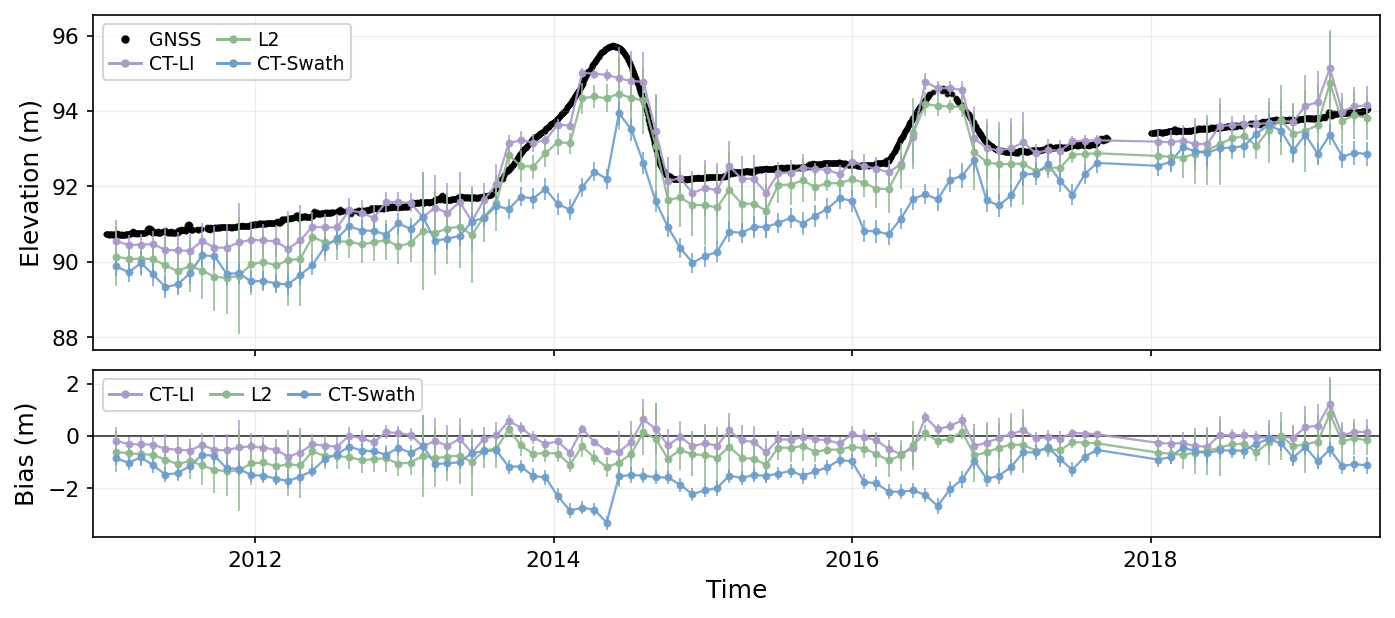


LA02
Kriging/bias station: LA02
Mapped GNSS station:  LA09
Bias CSV:             outputs/bias_results_all_stations_LA02_LA09_swapped.csv
GNSS CSV:             data/corrected_timeseries/la09_classified_rh_apc_corrected.csv
Bias rows plotted:    297
Valid GNSS days:      2,732
PNG written:          outputs/figures/LA02_interp_bias_timeseries_LA02_LA09_swapped_single_column.png


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# Make the two-panel manuscript example for LA02: corrected GNSS
# surface elevation above CryoSat-2 elevations and bias below.
# LA02 bias uses the LA09 corrected GNSS record.
# The corrected GNSS series already includes the RH and APC corrections.

# ============================================================
# SINGLE-STATION EXAMPLE
# ============================================================

STATION = "LA02"

# ============================================================
# KRIGING / BIAS STATION -> GNSS RECORD
# ============================================================

GNSS_STATION_MAP = {
    "LA02": "LA09",
    "LA09": "LA02",
}

# ============================================================
# INPUT / OUTPUT
# ============================================================

# Precomputed paper bias results bundled with this repository.
BIAS_CSV = Path("outputs/bias_results_all_stations_LA02_LA09_swapped.csv")
GNSS_DIR = Path("data/corrected_timeseries")
OUT_DIR = Path("outputs/figures")
OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ============================================================
# FILTER
# ============================================================

FILTER_PRODUCT = "STD_FILTERED"
THRESHOLD = 5
FILE_TAG = "LA02_LA09_swapped"

# ============================================================
# DATASETS
#
# Preserve the desired visual / legend order from the
# older single-station figure.
# ============================================================

DATASET_ORDER = [
    "POCA",
    "MISWIS",
    "SWATH",
]
DATASET_LABELS = {
    "MISWIS": "L2",
    "POCA": "CT-LI",
    "SWATH": "CT-Swath",
}
DATASET_COLORS = {
    "MISWIS": "#8eb88e",
    "POCA": "#aa9aca",
    "SWATH": "#6f9ec9",
}

# ============================================================
# MANUSCRIPT FIGURE SIZE
#
# ~3.5 inches wide is appropriate for one column in a
# typical two-column manuscript.
#
# Because the figure is generated near its final physical
# size, these font sizes remain readable when inserted.
# ============================================================

FIGSIZE = (
    11,
    4.3,
)
FIG_DPI = 150
SAVE_DPI = 600

# ============================================================
# FONT SIZES
# ============================================================

AXIS_LABEL_FONTSIZE = 12
TICK_FONTSIZE = 10.5
LEGEND_FONTSIZE = 9.0

# ============================================================
# GNSS STYLE
# ============================================================

GNSS_COLOR = "black"

# Small because daily GNSS is dense.
GNSS_MARKER_SIZE = 1.8
GNSS_ALPHA = 0.80

# ============================================================
# SATELLITE STYLE
# ============================================================

ALT_MARKER_SIZE = 2.8
LINEWIDTH = 1.1
ERRORBAR_LINEWIDTH = 0.8

# No caps keeps this dense manuscript figure cleaner.
ERRORBAR_CAPSIZE = 0
ALT_ALPHA = 0.90

# ============================================================
# LEGEND STYLE
# ============================================================

TOP_LEGEND_NCOLS = 2
BOTTOM_LEGEND_NCOLS = 3
LEGEND_HANDLELENGTH = 1.7
LEGEND_HANDLE_TEXT_PAD = 0.45
LEGEND_COLUMN_SPACING = 0.8
LEGEND_LABEL_SPACING = 0.25
LEGEND_BORDER_PAD = 0.35

# ============================================================
# GNSS COLUMN SETTINGS
# ============================================================

SURFACE_COLUMN = "Adjusted(m)"
VALID_FLAG_COLUMN = "daily_filtered_valid"

# ============================================================
# GLOBAL MATPLOTLIB
# ============================================================

plt.rcParams["figure.dpi"] = FIG_DPI

# ============================================================
# HELPERS
# ============================================================

def normalize_station(station):
    return (
        str(station)
        .upper()
        .strip()
    )

def normalize_dataset(dataset):
    return (
        str(dataset)
        .upper()
        .strip()
    )

def find_date_column(df):
    if "YEAR-MM-DD" not in df.columns:
        raise ValueError(
            "GNSS CSV is missing the YEAR-MM-DD date column."
        )
    return "YEAR-MM-DD"

def parse_bool_series(series):
    values = (
        series
        .astype(str)
        .str.upper()
        .str.strip()
    )
    return values.isin(
        [
            "TRUE",
            "T",
            "1",
            "YES",
            "Y",
        ]
    )

# ============================================================
# LOAD BIAS CSV
# ============================================================

def load_bias_csv():
    df = pd.read_csv(
        BIAS_CSV,
        low_memory=False,
    )
    required_columns = [
        "station",
        "dataset",
        "filter_product",
        "std_threshold_pct",
        "time",
        "krig_est",
        "krig_unc",
        "bias",
        "bias_unc",
        "bias_status",
        "gnss_station_used",
    ]
    missing = []
    for column in required_columns:
        if column not in df.columns:
            missing.append(column)
    if missing:
        raise ValueError(
            "Bias CSV missing required columns:\n"
            f"{missing}"
        )

    # --------------------------------------------------------
    # Normalize identifiers
    # --------------------------------------------------------

    df[
        "station"
    ] = df[
        "station"
    ].map(
        normalize_station
    )
    df[
        "dataset"
    ] = df[
        "dataset"
    ].map(
        normalize_dataset
    )
    df[
        "filter_product"
    ] = (
        df[
            "filter_product"
        ]
        .astype(str)
        .str.upper()
        .str.strip()
    )
    df[
        "bias_status"
    ] = (
        df[
            "bias_status"
        ]
        .astype(str)
        .str.lower()
        .str.strip()
    )
    df[
        "gnss_station_used"
    ] = (
        df[
            "gnss_station_used"
        ]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    # --------------------------------------------------------
    # Numeric
    # --------------------------------------------------------

    numeric_columns = [
        "std_threshold_pct",
        "krig_est",
        "krig_unc",
        "bias",
        "bias_unc",
    ]
    for column in numeric_columns:
        df[
            column
        ] = pd.to_numeric(
            df[
                column
            ],
            errors="coerce",
        )

    # --------------------------------------------------------
    # Date
    # --------------------------------------------------------

    df[
        "time"
    ] = (
        pd.to_datetime(
            df[
                "time"
            ],
            errors="coerce",
            utc=True,
        )
        .dt.tz_localize(
            None
        )
    )

    # --------------------------------------------------------
    # filtered CryoSat only
    # --------------------------------------------------------

    df = (
        df.loc[
            df[
                "filter_product"
            ].eq(
                FILTER_PRODUCT
            )
            &
            df[
                "std_threshold_pct"
            ].eq(
                THRESHOLD
            )
            &
            df[
                "dataset"
            ].isin(
                DATASET_ORDER
            )
        ]
        .copy()
    )
    if df.empty:
        raise RuntimeError(
            "No filtered CryoSat rows found in bias CSV."
        )
    return df

# ============================================================
# LOAD CORRECTED GNSS
#
# No additional filtering algorithm is applied here.
#
# We simply honor daily_filtered_valid from the corrected
# GNSS files and display the accepted daily observations.
# ============================================================

def load_station_gnss(station):
    station = normalize_station(
        station
    )
    gnss_station = GNSS_STATION_MAP.get(
        station,
        station,
    )
    csv_path = (
        GNSS_DIR
        /
        (
            f"{gnss_station.lower()}"
            "_classified_rh_apc_corrected.csv"
        )
    )
    if not csv_path.exists():
        raise FileNotFoundError(
            "Corrected GNSS CSV not found:\n"
            f"Station requested: {station}\n"
            f"Mapped GNSS station: {gnss_station}\n"
            f"Expected file:\n{csv_path}"
        )
    df = pd.read_csv(
        csv_path,
        low_memory=False,
    )
    date_column = find_date_column(
        df
    )
    df[
        "date_plot"
    ] = pd.to_datetime(
        df[
            date_column
        ],
        errors="coerce",
    )
    if SURFACE_COLUMN not in df.columns:
        raise ValueError(
            f"{csv_path.name} is missing "
            f"{SURFACE_COLUMN!r}"
        )
    df[
        "surface_elevation"
    ] = pd.to_numeric(
        df[
            SURFACE_COLUMN
        ],
        errors="coerce",
    )

    # --------------------------------------------------------
    # Use pre-existing daily validity flag.
    # No new filtering is performed.
    # --------------------------------------------------------

    if VALID_FLAG_COLUMN in df.columns:
        df[
            "daily_valid"
        ] = parse_bool_series(
            df[
                VALID_FLAG_COLUMN
            ]
        )
    else:
        df[
            "daily_valid"
        ] = True
    good = (
        df[
            "date_plot"
        ].notna()
        &
        np.isfinite(
            df[
                "surface_elevation"
            ]
        )
        &
        df[
            "daily_valid"
        ]
    )
    df_valid = (
        df.loc[
            good
        ]
        .sort_values(
            "date_plot"
        )
        .reset_index(
            drop=True
        )
    )
    return {
        "station": station,
        "gnss_station": gnss_station,
        "csv_path": csv_path,
        "valid": df_valid,
    }

# ============================================================
# LEGEND
#
# Use simple manuscript labels:
#
#   GNSS
#   CT-LI
#   L2
#   CT-Swath
#
# rather than long descriptions of the uncertainty fields.
# ============================================================

def make_top_legend(
    ax,
):
    handles = [
        Line2D(
            [0],
            [0],
            linestyle="None",
            marker="o",
            markersize=3.0,
            color=GNSS_COLOR,
            markerfacecolor=GNSS_COLOR,
            markeredgecolor=GNSS_COLOR,
            label="GNSS",
        )
    ]
    for dataset in DATASET_ORDER:
        handles.append(
            Line2D(
                [0],
                [0],
                linestyle="-",
                linewidth=1.4,
                marker="o",
                markersize=3.0,
                color=DATASET_COLORS[
                    dataset
                ],
                label=DATASET_LABELS[
                    dataset
                ],
            )
        )
    ax.legend(
        handles=handles,
        loc="upper left",
        ncol=TOP_LEGEND_NCOLS,
        fontsize=LEGEND_FONTSIZE,
        frameon=True,
        handlelength=LEGEND_HANDLELENGTH,
        handletextpad=LEGEND_HANDLE_TEXT_PAD,
        columnspacing=LEGEND_COLUMN_SPACING,
        labelspacing=LEGEND_LABEL_SPACING,
        borderpad=LEGEND_BORDER_PAD,
    )

def make_bottom_legend(
    ax,
):
    handles = []
    for dataset in DATASET_ORDER:
        handles.append(
            Line2D(
                [0],
                [0],
                linestyle="-",
                linewidth=1.4,
                marker="o",
                markersize=3.0,
                color=DATASET_COLORS[
                    dataset
                ],
                label=DATASET_LABELS[
                    dataset
                ],
            )
        )
    ax.legend(
        handles=handles,
        loc="upper left",
        ncol=BOTTOM_LEGEND_NCOLS,
        fontsize=LEGEND_FONTSIZE,
        frameon=True,
        handlelength=LEGEND_HANDLELENGTH,
        handletextpad=LEGEND_HANDLE_TEXT_PAD,
        columnspacing=LEGEND_COLUMN_SPACING,
        labelspacing=LEGEND_LABEL_SPACING,
        borderpad=LEGEND_BORDER_PAD,
    )

# ============================================================
# MAKE SINGLE-STATION FIGURE
# ============================================================

def make_station_figure(
    station,
    bias_df,
):
    station = normalize_station(
        station
    )

    # ========================================================
    # SELECT VALID BIAS VALUES
    # ========================================================

    station_bias = (
        bias_df.loc[
            bias_df[
                "station"
            ].eq(
                station
            )
            &
            bias_df[
                "bias_status"
            ].eq(
                "success"
            )
            &
            bias_df[
                "dataset"
            ].isin(
                DATASET_ORDER
            )
            &
            bias_df[
                "time"
            ].notna()
            &
            np.isfinite(
                bias_df[
                    "krig_est"
                ]
            )
            &
            np.isfinite(
                bias_df[
                    "krig_unc"
                ]
            )
            &
            np.isfinite(
                bias_df[
                    "bias"
                ]
            )
            &
            np.isfinite(
                bias_df[
                    "bias_unc"
                ]
            )
        ]
        .copy()
    )
    if station_bias.empty:
        print(
            f"[WARNING] "
            f"No successful bias rows for {station}."
        )
        return
    station_bias = (
        station_bias
        .sort_values(
            [
                "dataset",
                "time",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    # ========================================================
    # LOAD CORRECTED GNSS
    # ========================================================

    gnss_info = load_station_gnss(
        station
    )
    gnss_valid = gnss_info[
        "valid"
    ]
    gnss_station = gnss_info[
        "gnss_station"
    ]

    # ========================================================
    # VERIFY CORRECT GNSS MAPPING
    # ========================================================

    mapped_used = sorted(
        station_bias[
            "gnss_station_used"
        ]
        .dropna()
        .astype(str)
        .str.upper()
        .str.strip()
        .unique()
        .tolist()
    )
    has_wrong_gnss_station = False
    for value in mapped_used:
        if value != gnss_station:
            has_wrong_gnss_station = True
            break

    if mapped_used and has_wrong_gnss_station:
        raise RuntimeError(
            f"{station} bias rows are not consistently "
            f"using GNSS station {gnss_station}.\n"
            f"Found: {mapped_used}"
        )

    # ========================================================
    # FIGURE
    # ========================================================

    fig, (
        ax_top,
        ax_bottom,
    ) = plt.subplots(
        2,
        1,
        figsize=FIGSIZE,
        dpi=FIG_DPI,
        sharex=True,
        gridspec_kw={
            "height_ratios": [
                2.0,
                1.0,
            ],
            "hspace": 0.08,
        },
    )

    # ========================================================
    # TOP PANEL: DAILY GNSS
    #
    # Older figure style:
    # points only, no connecting GNSS line.
    # ========================================================

    if not gnss_valid.empty:
        ax_top.plot(
            gnss_valid[
                "date_plot"
            ],
            gnss_valid[
                "surface_elevation"
            ],
            linestyle="None",
            marker="o",
            markersize=GNSS_MARKER_SIZE,
            color=GNSS_COLOR,
            alpha=GNSS_ALPHA,
            zorder=1,
        )

    # ========================================================
    # CRYOSAT PRODUCTS
    # ========================================================

    for dataset in DATASET_ORDER:
        group = (
            station_bias.loc[
                station_bias[
                    "dataset"
                ].eq(
                    dataset
                )
            ]
            .sort_values(
                "time"
            )
            .copy()
        )
        if group.empty:
            continue
        color = DATASET_COLORS[
            dataset
        ]

        # ----------------------------------------------------
        # TOP:
        # connected interpolated elevation series
        # ----------------------------------------------------

        ax_top.plot(
            group[
                "time"
            ],
            group[
                "krig_est"
            ],
            linewidth=LINEWIDTH,
            color=color,
            alpha=ALT_ALPHA,
            zorder=2,
        )

        # ----------------------------------------------------
        # TOP:
        # points + interpolation uncertainty
        # ----------------------------------------------------

        ax_top.errorbar(
            group[
                "time"
            ],
            group[
                "krig_est"
            ],
            yerr=group[
                "krig_unc"
            ],
            fmt="o",
            markersize=ALT_MARKER_SIZE,
            linewidth=0,
            elinewidth=ERRORBAR_LINEWIDTH,
            capsize=ERRORBAR_CAPSIZE,
            color=color,
            alpha=ALT_ALPHA,
            zorder=3,
        )

        # ----------------------------------------------------
        # BOTTOM:
        # connected bias series
        # ----------------------------------------------------

        ax_bottom.plot(
            group[
                "time"
            ],
            group[
                "bias"
            ],
            linewidth=LINEWIDTH,
            color=color,
            alpha=ALT_ALPHA,
            zorder=2,
        )

        # ----------------------------------------------------
        # BOTTOM:
        # points + propagated bias uncertainty
        # ----------------------------------------------------

        ax_bottom.errorbar(
            group[
                "time"
            ],
            group[
                "bias"
            ],
            yerr=group[
                "bias_unc"
            ],
            fmt="o",
            markersize=ALT_MARKER_SIZE,
            linewidth=0,
            elinewidth=ERRORBAR_LINEWIDTH,
            capsize=ERRORBAR_CAPSIZE,
            color=color,
            alpha=ALT_ALPHA,
            zorder=3,
        )

    # ========================================================
    # ZERO BIAS LINE
    # ========================================================

    ax_bottom.axhline(
        0.0,
        linewidth=0.9,
        color="black",
        alpha=0.75,
        zorder=1,
    )

    # ========================================================
    # LABELS
    # ========================================================

    ax_top.set_ylabel(
        "Elevation (m)",
        fontsize=AXIS_LABEL_FONTSIZE,
    )
    ax_bottom.set_ylabel(
        "Bias (m)",
        fontsize=AXIS_LABEL_FONTSIZE,
    )
    ax_bottom.set_xlabel(
        "Time",
        fontsize=AXIS_LABEL_FONTSIZE,
    )

    # ========================================================
    # GRID
    # ========================================================

    ax_top.grid(
        True,
        alpha=0.22,
        linewidth=0.6,
    )
    ax_bottom.grid(
        True,
        alpha=0.22,
        linewidth=0.6,
    )

    # ========================================================
    # TICK LABEL SIZE
    # ========================================================

    ax_top.tick_params(
        axis="both",
        labelsize=TICK_FONTSIZE,
        length=3,
    )
    ax_bottom.tick_params(
        axis="both",
        labelsize=TICK_FONTSIZE,
        length=3,
    )

    # ========================================================
    # FEWER Y TICKS
    #
    # Important for a narrow one-column figure.
    # ========================================================

    ax_top.yaxis.set_major_locator(
        MaxNLocator(
            nbins=5,
        )
    )
    ax_bottom.yaxis.set_major_locator(
        MaxNLocator(
            nbins=4,
        )
    )

    # ========================================================
    # FEWER DATE TICKS
    #
    # One major label every two years.
    # ========================================================

    ax_bottom.xaxis.set_major_locator(
        mdates.YearLocator(
            base=2
        )
    )
    ax_bottom.xaxis.set_major_formatter(
        mdates.DateFormatter(
            "%Y"
        )
    )

    # ========================================================
    # LEGENDS
    #
    # Concise labels like the older station figure.
    # ========================================================

    make_top_legend(
        ax_top
    )
    make_bottom_legend(
        ax_bottom
    )

    # ========================================================
    # SMALL X MARGIN
    # ========================================================

    ax_top.margins(
        x=0.01
    )

    # ========================================================
    # LAYOUT
    # ========================================================

    fig.subplots_adjust(
        left=0.20,
        right=0.98,
        bottom=0.13,
        top=0.94,
        hspace=0.08,
    )

    # ========================================================
    # SAVE
    # ========================================================

    png_path = (
        OUT_DIR
        /
        (
            f"{station}_interp_bias_timeseries_"
            f"{FILE_TAG}_single_column.png"
        )
    )
    fig.savefig(
        png_path,
        dpi=SAVE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(
        fig
    )

    # ========================================================
    # REPORT
    # ========================================================

    print(
        "\n"
        +
        "=" * 70
    )
    print(
        station
    )
    print(
        "=" * 70
    )
    print(
        f"Kriging/bias station: {station}"
    )
    print(
        f"Mapped GNSS station:  {gnss_station}"
    )
    print(
        f"Bias CSV:             {BIAS_CSV}"
    )
    print(
        f"GNSS CSV:             "
        f"{gnss_info['csv_path']}"
    )
    print(
        f"Bias rows plotted:    "
        f"{len(station_bias):,}"
    )
    print(
        f"Valid GNSS days:      "
        f"{len(gnss_valid):,}"
    )
    print(
        f"PNG written:          "
        f"{png_path}"
    )

# ============================================================
# LOAD BIAS DATA
# ============================================================

df_bias = load_bias_csv()
print(
    "\n"
    +
    "=" * 70
)
print(
    "INPUT SUMMARY"
)
print(
    "=" * 70
)
print(
    f"Bias CSV:\n"
    f"{BIAS_CSV}"
)
print(
    f"\nRows after CryoSat filtering: "
    f"{len(df_bias):,}"
)
print(
    "\nRows by station / dataset:"
)
print(
    df_bias.groupby(
        [
            "station",
            "dataset",
        ]
    )
    .size()
    .rename(
        "n_rows"
    )
    .reset_index()
    .to_string(
        index=False
    )
)

# ============================================================
# MAKE THE LA02 SINGLE-STATION FIGURE
# ============================================================

make_station_figure(
    STATION,
    df_bias,
)


# Plot the weighted 90-day bias time series


[CHECK] LA02 -> LA09 GNSS pairing confirmed.
[CHECK] LA09 -> LA02 GNSS pairing confirmed.

filtered ROLLING BIAS INPUT
[INFO] Bias CSV:
  outputs/bias_results_all_stations_LA02_LA09_swapped.csv
[INFO] Filter: STD_FILTERED (5%)
[INFO] Rolling window: 90 days
[INFO] Rolling step: 30 days
[INFO] Use original-window overlap: True
[INFO] Excluded datasets: ['N']
[INFO] Excluded stations: []
[INFO] Valid rows retained: 1,983 / 2,094
[INFO] Stations included (29):
['GZ01', 'GZ02', 'GZ06', 'GZ09', 'GZ13', 'GZ17', 'GZ18', 'LA01', 'LA02', 'LA03', 'LA04', 'LA05', 'LA06', 'LA07', 'LA08', 'LA09', 'LA10', 'LA11', 'LA12', 'LA13', 'LA14', 'LA15', 'LA16', 'LA17', 'LA18', 'MG04', 'MG05', 'MG06', 'MG07']

[INFO] Bias estimates by dataset:
dataset
MISWIS    661
POCA      661
SWATH     661
Name: N, dtype: int64



[CHECK] Station counts are identical across datasets for every rolling window.
[INFO] Shared station-count range:
  min    = 1
  median = 7.0
  max    = 21

[INFO] Wrote summary CSV:
  outputs/figures/rolling_bias_summary_90day_step30_overlap_LA02_LA09_swapped.csv

[INFO] Dataset appearance:
  MISWIS   -> L2         -> #8eb88e
  POCA     -> CT-LI      -> #aa9aca
  SWATH    -> CT-Swath   -> #6f9ec9

[CHECK] n_stations is identical across datasets for every rolling window.


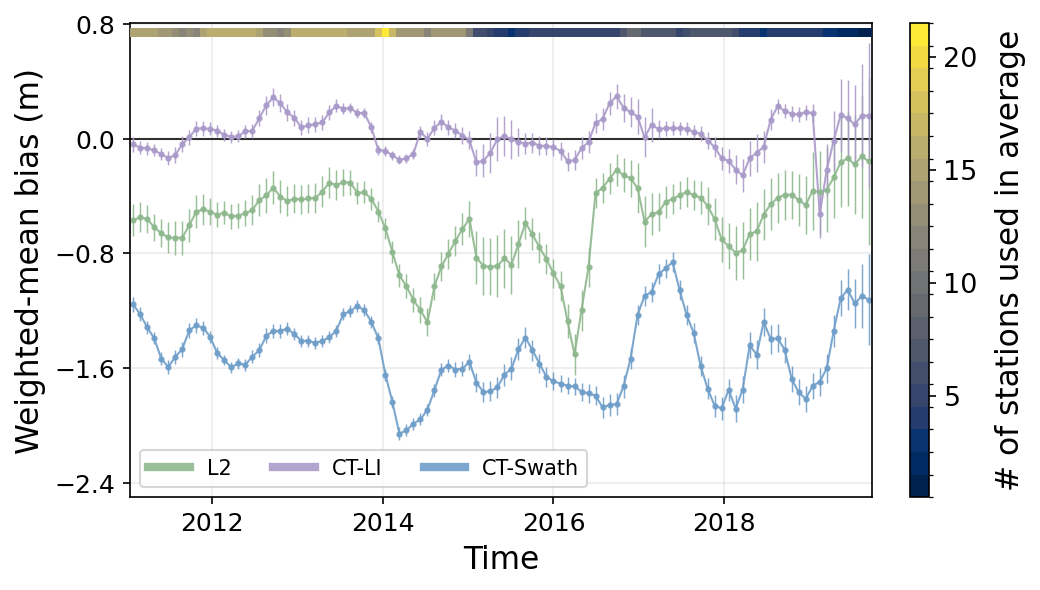

[INFO] Wrote figure:
  outputs/figures/rolling_mean_bias_90day_step30_overlap_LA02_LA09_swapped_station_count_bar_paper_stations.png
[INFO] Wrote figure:

ROLLING filtered BIAS FIGURE COMPLETE
dataset
MISWIS    106
POCA      106
SWATH     106
Name: n_time_steps, dtype: int64

First 20 rolling results:


,dataset,window_start,window_end,window_mid,mean_bias,mean_bias_unc,n_obs,n_stations,weighting_method,window_membership,filter_product,std_threshold_pct
0,MISWIS,2010-12-13,2011-03-13,2011-01-27,-0.568199,0.113021,36,15,inverse_variance,original_window_overlap,STD_FILTERED,5
1,MISWIS,2011-01-12,2011-04-12,2011-02-26,-0.548444,0.105173,46,15,inverse_variance,original_window_overlap,STD_FILTERED,5
2,MISWIS,2011-02-11,2011-05-12,2011-03-28,-0.559337,0.099874,53,15,inverse_variance,original_window_overlap,STD_FILTERED,5
3,MISWIS,2011-03-13,2011-06-11,2011-04-27,-0.618126,0.092552,62,15,inverse_variance,original_window_overlap,STD_FILTERED,5
4,MISWIS,2011-04-12,2011-07-11,2011-05-27,-0.659136,0.098320,57,14,inverse_variance,original_window_overlap,STD_FILTERED,5
5,MISWIS,2011-05-12,2011-08-10,2011-06-26,-0.689426,0.110385,49,14,inverse_variance,original_window_overlap,STD_FILTERED,5
6,MISWIS,2011-06-11,2011-09-09,2011-07-26,-0.692283,0.116675,48,13,inverse_variance,original_window_overlap,STD_FILTERED,5
7,MISWIS,2011-07-11,2011-10-09,2011-08-25,-0.691151,0.120189,43,12,inverse_variance,original_window_overlap,STD_FILTERED,5
8,MISWIS,2011-08-10,2011-11-08,2011-09-24,-0.605266,0.115636,44,13,inverse_variance,original_window_overlap,STD_FILTERED,5
9,MISWIS,2011-09-09,2011-12-08,2011-10-24,-0.509373,0.113106,45,12,inverse_variance,original_window_overlap,STD_FILTERED,5


,dataset,window_start,window_end,window_mid,mean_bias,mean_bias_unc,n_obs,n_stations,weighting_method,window_membership,filter_product,std_threshold_pct
0,MISWIS,2010-12-13,2011-03-13,2011-01-27,-0.568199,0.113021,36,15,inverse_variance,original_window_overlap,STD_FILTERED,5
1,MISWIS,2011-01-12,2011-04-12,2011-02-26,-0.548444,0.105173,46,15,inverse_variance,original_window_overlap,STD_FILTERED,5
2,MISWIS,2011-02-11,2011-05-12,2011-03-28,-0.559337,0.099874,53,15,inverse_variance,original_window_overlap,STD_FILTERED,5
3,MISWIS,2011-03-13,2011-06-11,2011-04-27,-0.618126,0.092552,62,15,inverse_variance,original_window_overlap,STD_FILTERED,5
4,MISWIS,2011-04-12,2011-07-11,2011-05-27,-0.659136,0.098320,57,14,inverse_variance,original_window_overlap,STD_FILTERED,5
...,...,...,...,...,...,...,...,...,...,...,...,...
313,SWATH,2019-03-31,2019-06-29,2019-05-15,-1.112662,0.126059,8,2,inverse_variance,original_window_overlap,STD_FILTERED,5
314,SWATH,2019-04-30,2019-07-29,2019-06-14,-1.054182,0.144356,6,2,inverse_variance,original_window_overlap,STD_FILTERED,5
315,SWATH,2019-05-30,2019-08-28,2019-07-14,-1.149551,0.173261,4,2,inverse_variance,original_window_overlap,STD_FILTERED,5
316,SWATH,2019-06-29,2019-09-27,2019-08-13,-1.098987,0.224858,2,1,inverse_variance,original_window_overlap,STD_FILTERED,5


In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
from IPython.display import display

# Plot the filtered inverse-variance weighted bias in 90-day windows stepped
# every 30 days. Keep the existing interpolation-window overlap rule.
# Figure settings are sized for a two-column manuscript layout.

# INPUT / OUTPUT

# ============================================================

# Set BIAS_CSV to the bias-results CSV produced by the calculation cell above.
# Precomputed paper bias results bundled with this repository.
BIAS_CSV = Path("outputs/bias_results_all_stations_LA02_LA09_swapped.csv")
OUT_DIR = Path("outputs/figures")
OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ============================================================

# ANALYSIS SETTINGS

# ============================================================

WINDOW_DAYS = 90
STEP_DAYS = 30
USE_WINDOW_OVERLAP = True
MIN_N = 1
FILTER_PRODUCT = "STD_FILTERED"
STD_THRESHOLD_PCT = 5
FILE_TAG = "LA02_LA09_swapped"
EXCLUDE_DATASETS = {
    "N",
}
EXCLUDE_STATIONS = set()
DESIRED_ORDER = [
    "MISWIS",
    "POCA",
    "SWATH",
]
LEGEND_NCOLS = 3
LEGEND_LINEWIDTH = 4.0

# ============================================================

# FIGURE SETTINGS

# ============================================================

# Build the figure close to its final two-column manuscript size.

FIGSIZE = (7.2, 4.0)
STATION_COUNT_CMAP = "cividis"

# Station-count strip INSIDE the upper edge of the main axes.

# Axes-fraction coordinates: [left, bottom, width, height].

STATION_BAR_LEFT = 0.0
STATION_BAR_BOTTOM = 0.97
STATION_BAR_WIDTH = 1.0
STATION_BAR_HEIGHT = 0.02
COLORBAR_WIDTH_RATIO = 0.025

# Explicit manuscript font sizes.

PLOT_AXIS_LABEL_FONTSIZE = 15
PLOT_TICK_FONTSIZE = 12
PLOT_LEGEND_FONTSIZE = 10
PLOT_COLORBAR_LABEL_FONTSIZE = 15
PLOT_COLORBAR_TICK_FONTSIZE = 13

# Slightly heavier plotting elements for reduction in the manuscript.

PLOT_LINEWIDTH = 1
PLOT_ERRORBAR_LINEWIDTH = 0.7
PLOT_MARKERSIZE = 2
PLOT_CAPSIZE = 0
plt.rcParams["figure.dpi"] = 150

# ============================================================

# SHARED SETTINGS

# ============================================================

required_shared_settings = [
    "DATASET_LABEL_MAP",
    "DATASET_COLOR_MAP",
    "PLOT_ALPHA",
]

# Check that the shared style cell has been run before making the plots.
missing_shared_settings = []
for name in required_shared_settings:
    if name not in globals():
        missing_shared_settings.append(name)
if missing_shared_settings:
    raise RuntimeError(
        "Run the shared settings cell first. "
        f"Missing: {missing_shared_settings}"
    )

# Normalize the names once so the plotting code can look them up consistently.
_DATASET_LABEL_MAP_NORMALIZED = {}
for key, value in DATASET_LABEL_MAP.items():
    normalized_key = str(key).upper().strip()
    _DATASET_LABEL_MAP_NORMALIZED[normalized_key] = value
_DATASET_COLOR_MAP_NORMALIZED = {}
for key, value in DATASET_COLOR_MAP.items():
    normalized_key = str(key).upper().strip()
    _DATASET_COLOR_MAP_NORMALIZED[normalized_key] = value

# ============================================================

# HELPERS

# ============================================================

def _clean_dataset_name(ds):
    return str(ds).upper().strip()

def _display_dataset_label(ds):
    ds = _clean_dataset_name(ds)
    return _DATASET_LABEL_MAP_NORMALIZED.get(
        ds,
        ds,
    )

def _dataset_color(ds):
    ds = _clean_dataset_name(ds)
    if ds in _DATASET_COLOR_MAP_NORMALIZED:
        return _DATASET_COLOR_MAP_NORMALIZED[
            ds
        ]
    display_name = str(
        _display_dataset_label(
            ds
        )
    ).upper().strip()
    if display_name in _DATASET_COLOR_MAP_NORMALIZED:
        return _DATASET_COLOR_MAP_NORMALIZED[
            display_name
        ]
    raise KeyError(
        f"No fixed color defined for dataset {ds!r}. "
        f"Display name is {_display_dataset_label(ds)!r}."
    )

# ============================================================

# INVERSE-VARIANCE WEIGHTED MEAN

# ============================================================

def weighted_mean_and_unc(
    bias,
    bias_unc,
):
    bias = np.asarray(
        bias,
        dtype=float,
    )
    bias_unc = np.asarray(
        bias_unc,
        dtype=float,
    )
    good = (
        np.isfinite(
            bias
        )
        &
        np.isfinite(
            bias_unc
        )
        &
        (
            bias_unc > 0
        )
    )
    bias = bias[
        good
    ]
    bias_unc = bias_unc[
        good
    ]
    n = int(
        bias.size
    )
    if n == 0:
        return (
            np.nan,
            np.nan,
            0,
        )
    weights = (
        1.0
        /
        (
            bias_unc
            ** 2
        )
    )
    weighted_mean = float(
        np.sum(
            weights
            *
            bias
        )
        /
        np.sum(
            weights
        )
    )
    weighted_mean_unc = float(
        np.sqrt(
            1.0
            /
            np.sum(
                weights
            )
        )
    )
    return (
        weighted_mean,
        weighted_mean_unc,
        n,
    )

# ============================================================

# BUILD ROLLING BIAS TIME SERIES

#

# ORIGINAL OVERLAP LOGIC:

#

#   w1 >= rolling_start

#   AND

#   w0 <= rolling_end

#

# If w0/w1 are missing, use interpolation center time.

# ============================================================

def build_rolling_bias_timeseries(
    df,
    window_days=90,
    step_days=30,
    use_window_overlap=True,
    min_n=1,
):
    df = df.copy()

    # --------------------------------------------------------

    # DATES

    # --------------------------------------------------------

    for column in [
        "time",
        "w0",
        "w1",
    ]:
        df[column] = pd.to_datetime(
            df[column],
            errors="coerce",
            utc=True,
        ).dt.tz_localize(
            None
        )

    # --------------------------------------------------------

    # IDENTIFIERS

    # --------------------------------------------------------

    df["dataset"] = (
        df["dataset"]
        .astype(str)
        .str.upper()
        .str.strip()
    )
    df["station"] = (
        df["station"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    # --------------------------------------------------------

    # NUMERIC

    # --------------------------------------------------------

    df["bias"] = pd.to_numeric(
        df["bias"],
        errors="coerce",
    )
    df["bias_unc"] = pd.to_numeric(
        df["bias_unc"],
        errors="coerce",
    )

    # --------------------------------------------------------

    # VALID BIASES ONLY

    # --------------------------------------------------------

    df = (
        df.loc[
            np.isfinite(
                df["bias"]
            )
            &
            np.isfinite(
                df["bias_unc"]
            )
            &
            df[
                "bias_unc"
            ].gt(
                0
            )
            &
            df[
                "time"
            ].notna()
        ]
        .copy()
    )
    if df.empty:
        raise ValueError(
            "No valid bias estimates remain."
        )

    # --------------------------------------------------------

    # DATE RANGE

    # --------------------------------------------------------

    if use_window_overlap:
        valid_w0 = (
            df[
                "w0"
            ]
            .dropna()
        )
        valid_w1 = (
            df[
                "w1"
            ]
            .dropna()
        )
        if (
            not valid_w0.empty
            and
            not valid_w1.empty
        ):
            t_min = (
                valid_w0
                .min()
                .normalize()
            )
            t_max = (
                valid_w1
                .max()
                .normalize()
            )
        else:
            t_min = (
                df[
                    "time"
                ]
                .min()
                .normalize()
            )
            t_max = (
                df[
                    "time"
                ]
                .max()
                .normalize()
            )
    else:
        t_min = (
            df[
                "time"
            ]
            .min()
            .normalize()
        )
        t_max = (
            df[
                "time"
            ]
            .max()
            .normalize()
        )

    # --------------------------------------------------------

    # DATASETS

    # --------------------------------------------------------

    # Keep the manuscript's preferred order, skipping products absent here.
    present_datasets = set(df["dataset"])
    datasets = []
    for dataset in DESIRED_ORDER:
        if dataset in present_datasets:
            datasets.append(dataset)
    rows = []
    delta_window = pd.Timedelta(
        days=window_days
    )
    delta_step = pd.Timedelta(
        days=step_days
    )
    ws = t_min

    # ========================================================

    # ROLLING WINDOWS

    # ========================================================

    while ws <= t_max:
        we = (
            ws
            +
            delta_window
        )
        wm = (
            ws
            +
            pd.Timedelta(
                days=window_days / 2.0
            )
        )
        for dataset in datasets:
            sub = (
                df.loc[
                    df[
                        "dataset"
                    ].eq(
                        dataset
                    )
                ]
                .copy()
            )

            # =================================================

            # ORIGINAL WINDOW OVERLAP

            # =================================================

            if use_window_overlap:
                have_bounds = (
                    sub[
                        "w0"
                    ].notna()
                    &
                    sub[
                        "w1"
                    ].notna()
                )
                mask_overlap = (
                    have_bounds
                    &
                    sub[
                        "w1"
                    ].ge(
                        ws
                    )
                    &
                    sub[
                        "w0"
                    ].le(
                        we
                    )
                )
                mask_time_fallback = (
                    ~have_bounds
                    &
                    sub[
                        "time"
                    ].notna()
                    &
                    sub[
                        "time"
                    ].ge(
                        ws
                    )
                    &
                    sub[
                        "time"
                    ].le(
                        we
                    )
                )
                subw = (
                    sub.loc[
                        mask_overlap
                        |
                        mask_time_fallback
                    ]
                    .copy()
                )
            else:
                subw = (
                    sub.loc[
                        sub[
                            "time"
                        ].notna()
                        &
                        sub[
                            "time"
                        ].ge(
                            ws
                        )
                        &
                        sub[
                            "time"
                        ].le(
                            we
                        )
                    ]
                    .copy()
                )
            if len(
                subw
            ) < min_n:
                continue
            (
                mean_bias,
                mean_bias_unc,
                n_obs,
            ) = weighted_mean_and_unc(
                subw[
                    "bias"
                ].to_numpy(),
                subw[
                    "bias_unc"
                ].to_numpy(),
            )
            if (
                n_obs < min_n
                or
                not np.isfinite(
                    mean_bias
                )
            ):
                continue
            rows.append(
                {
                    "dataset": dataset,
                    "window_start": ws,
                    "window_end": we,
                    "window_mid": wm,
                    "mean_bias": mean_bias,
                    "mean_bias_unc": mean_bias_unc,
                    "n_obs": int(
                        n_obs
                    ),
                    "n_stations": int(
                        subw[
                            "station"
                        ].nunique()
                    ),
                    "weighting_method": (
                        "inverse_variance"
                    ),
                    "window_membership": (
                        "original_window_overlap"
                    ),
                }
            )
        ws += delta_step
    out = pd.DataFrame(
        rows
    )
    if out.empty:
        raise ValueError(
            "No rolling-window results were produced."
        )
    return (
        out
        .sort_values(
            [
                "dataset",
                "window_mid",
            ]
        )
        .reset_index(
            drop=True
        )
    )

# ============================================================

# PLOT

#

# One thin shared station-count strip inside the main axes.

# The colorbar shows the number of stations used in the

# rolling weighted average.

# ============================================================

def plot_rolling_bias_timeseries(
    summary_df,
    out_png,
):
    summary_df = (
        summary_df
        .copy()
    )
    summary_df[
        "window_mid"
    ] = pd.to_datetime(
        summary_df[
            "window_mid"
        ],
        errors="coerce",
    )
    summary_df[
        "mean_bias"
    ] = pd.to_numeric(
        summary_df[
            "mean_bias"
        ],
        errors="coerce",
    )
    summary_df[
        "mean_bias_unc"
    ] = pd.to_numeric(
        summary_df[
            "mean_bias_unc"
        ],
        errors="coerce",
    )
    summary_df[
        "n_stations"
    ] = pd.to_numeric(
        summary_df[
            "n_stations"
        ],
        errors="coerce",
    )

    # Show only datasets present in the summary, in the same preferred order.
    present_datasets = set(summary_df["dataset"])
    datasets = []
    for dataset in DESIRED_ORDER:
        if dataset in present_datasets:
            datasets.append(dataset)
    colors = {}
    for dataset in datasets:
        colors[dataset] = _dataset_color(dataset)
    print(
        "\n[INFO] Dataset appearance:"
    )
    for dataset in datasets:
        print(
            f"  {dataset:<8} "
            f"-> {_display_dataset_label(dataset):<10} "
            f"-> {colors[dataset]}"
        )

    # ========================================================

    # VERIFY STATION COUNTS MATCH ACROSS DATASETS

    # ========================================================

    station_count_check = (
        summary_df[
            [
                "window_mid",
                "dataset",
                "n_stations",
            ]
        ]
        .dropna(
            subset=[
                "window_mid",
                "n_stations",
            ]
        )
        .pivot_table(
            index="window_mid",
            columns="dataset",
            values="n_stations",
            aggfunc="first",
        )
        .sort_index()
    )
    count_nunique = (
        station_count_check
        .nunique(
            axis=1,
            dropna=True,
        )
    )
    mismatched_dates = (
        count_nunique[
            count_nunique
            >
            1
        ]
    )
    if not mismatched_dates.empty:
        mismatch_table = (
            station_count_check.loc[
                mismatched_dates.index
            ]
        )
        print(
            "\n[ERROR] Station counts are not identical "
            "across datasets for these windows:"
        )
        display(
            mismatch_table
        )
        raise RuntimeError(
            "Cannot use one shared station-count strip "
            "because n_stations differs across datasets."
        )
    print(
        "\n[CHECK] n_stations is identical across "
        "datasets for every rolling window."
    )

    # ========================================================

    # ONE SHARED COUNT PER WINDOW

    # ========================================================

    station_counts = (
        station_count_check
        .bfill(
            axis=1
        )
        .iloc[
            :,
            0
        ]
        .dropna()
        .astype(
            float
        )
    )
    heat_dates = (
        station_counts
        .index
        .to_list()
    )
    count_values = (
        station_counts
        .to_numpy(
            dtype=float
        )
    )
    if len(
        heat_dates
    ) == 0:
        raise RuntimeError(
            "No valid station counts available."
        )

    # ========================================================

    # DATE EDGES

    # ========================================================

    date_numbers = mdates.date2num(
        pd.to_datetime(
            heat_dates
        ).to_pydatetime()
    )
    if len(
        date_numbers
    ) == 1:
        half_width = (
            STEP_DAYS
            /
            2.0
        )
        date_edges = np.array(
            [
                date_numbers[
                    0
                ]
                -
                half_width,
                date_numbers[
                    0
                ]
                +
                half_width,
            ]
        )
    else:
        internal_edges = (
            date_numbers[
                :-1
            ]
            +
            date_numbers[
                1:
            ]
        ) / 2.0
        first_edge = (
            date_numbers[
                0
            ]
            -
            (
                internal_edges[
                    0
                ]
                -
                date_numbers[
                    0
                ]
            )
        )
        last_edge = (
            date_numbers[
                -1
            ]
            +
            (
                date_numbers[
                    -1
                ]
                -
                internal_edges[
                    -1
                ]
            )
        )
        date_edges = np.concatenate(
            [
                [
                    first_edge
                ],
                internal_edges,
                [
                    last_edge
                ],
            ]
        )

    # ========================================================

    # COLOR SCALE

    # ========================================================

    station_min = int(
        np.nanmin(
            count_values
        )
    )
    station_max = int(
        np.nanmax(
            count_values
        )
    )
    if station_min == station_max:
        boundaries = np.array(
            [
                station_min
                -
                0.5,
                station_max
                +
                0.5,
            ]
        )
    else:
        boundaries = np.arange(
            station_min
            -
            0.5,
            station_max
            +
            1.5,
            1.0,
        )
    cmap = plt.get_cmap(
        STATION_COUNT_CMAP
    )
    norm = BoundaryNorm(
        boundaries,
        cmap.N,
        clip=True,
    )

    # ========================================================

    # FIGURE LAYOUT

    # ========================================================

    fig = plt.figure(
        figsize=FIGSIZE
    )
    grid = fig.add_gridspec(
        nrows=1,
        ncols=2,
        width_ratios=[
            1.0,
            COLORBAR_WIDTH_RATIO,
        ],
        wspace=0.10,
    )
    ax = fig.add_subplot(
        grid[
            0,
            0
        ]
    )
    cax = fig.add_subplot(
        grid[
            0,
            1
        ]
    )

    # Leave enough room for manuscript-sized labels.

    fig.subplots_adjust(
        left=0.14,
        right=0.88,
        bottom=0.18,
        top=0.97,
    )

    # ========================================================

    # THIN STATION-COUNT STRIP INSIDE MAIN AXES

    # ========================================================

    ax_count = ax.inset_axes(
        [
            STATION_BAR_LEFT,
            STATION_BAR_BOTTOM,
            STATION_BAR_WIDTH,
            STATION_BAR_HEIGHT,
        ]
    )
    station_row = (
        count_values
        .reshape(
            1,
            -1,
        )
    )
    mesh = ax_count.pcolormesh(
        date_edges,
        [
            0,
            1,
        ],
        station_row,
        cmap=cmap,
        norm=norm,
        shading="flat",
    )
    ax_count.set_xlim(
        date_edges[
            0
        ],
        date_edges[
            -1
        ],
    )
    ax_count.set_ylim(
        0,
        1,
    )
    ax_count.set_xticks(
        []
    )
    ax_count.set_yticks(
        []
    )
    ax_count.set_xlabel(
        ""
    )
    ax_count.set_ylabel(
        ""
    )
    ax_count.grid(
        False
    )
    for spine in ax_count.spines.values():
        spine.set_visible(
            False
        )

    # ========================================================

    # COLORBAR

    # ========================================================

    cbar = fig.colorbar(
        mesh,
        cax=cax,
    )
    cbar.set_label(
        "# of stations used in average",
        fontsize=PLOT_COLORBAR_LABEL_FONTSIZE,
        labelpad=8,
    )
    cbar.ax.tick_params(
        labelsize=PLOT_COLORBAR_TICK_FONTSIZE,
    )
    cbar.ax.yaxis.set_major_locator(
        MaxNLocator(
            integer=True,
            nbins=5,
        )
    )

    # ========================================================

    # MAIN BIAS PLOT

    # ========================================================

    ax.axhline(
        0.0,
        linewidth=1.0,
        color="k",
        alpha=0.8,
    )
    for dataset in datasets:
        sub = (
            summary_df.loc[
                summary_df[
                    "dataset"
                ].eq(
                    dataset
                )
            ]
            .sort_values(
                "window_mid"
            )
        )
        if sub.empty:
            continue
        color = colors[
            dataset
        ]
        ax.plot(
            sub[
                "window_mid"
            ],
            sub[
                "mean_bias"
            ],
            linewidth=PLOT_LINEWIDTH,
            alpha=PLOT_ALPHA,
            color=color,
            label=(
                _display_dataset_label(
                    dataset
                )
            ),
        )
        ax.errorbar(
            sub[
                "window_mid"
            ],
            sub[
                "mean_bias"
            ],
            yerr=sub[
                "mean_bias_unc"
            ],
            fmt="o",
            markersize=PLOT_MARKERSIZE,
            elinewidth=PLOT_ERRORBAR_LINEWIDTH,
            capsize=PLOT_CAPSIZE,
            alpha=PLOT_ALPHA,
            color=color,
        )

    # ========================================================

    # AXIS FORMATTING

    # ========================================================

    ax.set_xlabel(
        "Time",
        fontsize=PLOT_AXIS_LABEL_FONTSIZE,
    )
    ax.set_ylabel(
        "Weighted-mean bias (m)",
        fontsize=PLOT_AXIS_LABEL_FONTSIZE,
    )
    ax.grid(
        True,
        alpha=0.25,
    )
    ax.tick_params(
        axis="both",
        labelsize=PLOT_TICK_FONTSIZE,
    )

    # Fewer manuscript-friendly date ticks.

    ax.xaxis.set_major_locator(
        mdates.YearLocator(
            base=2
        )
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter(
            "%Y"
        )
    )

    # Fewer y-axis ticks.

    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=5
        )
    )
    ax.set_xlim(
        date_edges[
            0
        ],
        date_edges[
            -1
        ],
    )
    ax.set_ylim(
        bottom=-2.5
    )

    # ========================================================

    # LEGEND

    # ========================================================

    leg = ax.legend(
        loc="lower left",
        ncols=LEGEND_NCOLS,
        fontsize=PLOT_LEGEND_FONTSIZE,
        frameon=True,
    )
    if leg is not None:
        for line in leg.get_lines():
            line.set_linewidth(
                LEGEND_LINEWIDTH
            )

    # ========================================================

    # SAVE

    # ========================================================

    out_png.parent.mkdir(
        parents=True,
        exist_ok=True,
    )
    fig.savefig(
        out_png,
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(
        fig
    )

# ============================================================

# LOAD BIAS CSV

# ============================================================

bias_df = pd.read_csv(
    BIAS_CSV,
    low_memory=False,
)

# ============================================================

# VALIDATE REQUIRED COLUMNS

# ============================================================

required = {
    "station",
    "dataset",
    "filter_product",
    "std_threshold_pct",
    "time",
    "w0",
    "w1",
    "bias",
    "bias_unc",
    "bias_status",
}
missing = (
    required
    -
    set(
        bias_df.columns
    )
)
if missing:
    raise ValueError(
        "Bias CSV missing required columns:\n"
        f"  {sorted(missing)}"
    )

# ============================================================

# NORMALIZE

# ============================================================

bias_df[
    "dataset"
] = (
    bias_df[
        "dataset"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "station"
] = (
    bias_df[
        "station"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "filter_product"
] = (
    bias_df[
        "filter_product"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "bias_status"
] = (
    bias_df[
        "bias_status"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
)
bias_df[
    "std_threshold_pct"
] = pd.to_numeric(
    bias_df[
        "std_threshold_pct"
    ],
    errors="coerce",
)
bias_df[
    "bias"
] = pd.to_numeric(
    bias_df[
        "bias"
    ],
    errors="coerce",
)
bias_df[
    "bias_unc"
] = pd.to_numeric(
    bias_df[
        "bias_unc"
    ],
    errors="coerce",
)
for column in [
    "time",
    "w0",
    "w1",
]:
    bias_df[
        column
    ] = pd.to_datetime(
        bias_df[
            column
        ],
        errors="coerce",
        utc=True,
    ).dt.tz_localize(
        None
    )

# ============================================================

# filtered data ONLY

# ============================================================

bias_df = (
    bias_df.loc[
        bias_df[
            "filter_product"
        ].eq(
            FILTER_PRODUCT
        )
        &
        bias_df[
            "std_threshold_pct"
        ].eq(
            STD_THRESHOLD_PCT
        )
    ]
    .copy()
)
if bias_df.empty:
    raise RuntimeError(
        "No bias rows remain after filtering."
    )

# ============================================================

# VERIFY LA02 / LA09 GNSS PAIRING

#

# Audit only.

# Bias is NOT recalculated here.

# ============================================================

if "gnss_station_used" in bias_df.columns:
    bias_df[
        "gnss_station_used"
    ] = (
        bias_df[
            "gnss_station_used"
        ]
        .astype(str)
        .str.upper()
        .str.strip()
    )
    expected_pairing = {
        "LA02": "LA09",
        "LA09": "LA02",
    }
    for station, expected_gnss in (
        expected_pairing.items()
    ):
        station_rows = (
            bias_df.loc[
                bias_df[
                    "station"
                ].eq(
                    station
                )
            ]
        )
        if station_rows.empty:
            continue
        found = sorted(
            station_rows[
                "gnss_station_used"
            ]
            .dropna()
            .unique()
            .tolist()
        )
        unexpected = []
        for value in found:
            if value != expected_gnss:
                unexpected.append(value)
        if unexpected:
            raise RuntimeError(
                f"{station} bias rows use the wrong GNSS record.\n"
                f"Expected: {expected_gnss}\n"
                f"Found:    {found}"
            )
        print(
            f"[CHECK] {station} -> "
            f"{expected_gnss} GNSS pairing confirmed."
        )

# ============================================================

# EXCLUDE DATASETS + STATIONS + FAILED BIASES

# ============================================================

n_before = len(
    bias_df
)
bias_df = (
    bias_df.loc[
        ~bias_df[
            "dataset"
        ].isin(
            EXCLUDE_DATASETS
        )
        &
        bias_df[
            "dataset"
        ].isin(
            DESIRED_ORDER
        )
        &
        ~bias_df[
            "station"
        ].isin(
            EXCLUDE_STATIONS
        )
        &
        bias_df[
            "bias_status"
        ].eq(
            "success"
        )
        &
        np.isfinite(
            bias_df[
                "bias"
            ]
        )
        &
        np.isfinite(
            bias_df[
                "bias_unc"
            ]
        )
        &
        bias_df[
            "bias_unc"
        ].gt(
            0
        )
    ]
    .copy()
)
n_after = len(
    bias_df
)
if bias_df.empty:
    raise RuntimeError(
        "No valid filtered CryoSat bias rows remain."
    )

# ============================================================

# INPUT SUMMARY

# ============================================================

print(
    "\n========================================"
)
print(
    "filtered ROLLING BIAS INPUT"
)
print(
    "========================================"
)
print(
    f"[INFO] Bias CSV:\n"
    f"  {BIAS_CSV}"
)
print(
    f"[INFO] Filter: "
    f"{FILTER_PRODUCT} ({STD_THRESHOLD_PCT}%)"
)
print(
    f"[INFO] Rolling window: "
    f"{WINDOW_DAYS} days"
)
print(
    f"[INFO] Rolling step: "
    f"{STEP_DAYS} days"
)
print(
    f"[INFO] Use original-window overlap: "
    f"{USE_WINDOW_OVERLAP}"
)
print(
    "[INFO] Excluded datasets:",
    sorted(
        EXCLUDE_DATASETS
    ),
)
print(
    "[INFO] Excluded stations:",
    sorted(
        EXCLUDE_STATIONS
    ),
)
print(
    f"[INFO] Valid rows retained: "
    f"{n_after:,} / {n_before:,}"
)
print(
    f"[INFO] Stations included "
    f"({bias_df['station'].nunique()}):"
)
print(
    sorted(
        bias_df[
            "station"
        ]
        .unique()
        .tolist()
    )
)
print(
    "\n[INFO] Bias estimates by dataset:"
)
print(
    bias_df.groupby(
        "dataset"
    )
    .size()
    .rename(
        "N"
    )
)

# ============================================================

# BUILD ROLLING SUMMARY

# ============================================================

rolling_df = build_rolling_bias_timeseries(
    bias_df,
    window_days=WINDOW_DAYS,
    step_days=STEP_DAYS,
    use_window_overlap=USE_WINDOW_OVERLAP,
    min_n=MIN_N,
)

# ============================================================

# ADD FILTER METADATA

# ============================================================

rolling_df[
    "filter_product"
] = FILTER_PRODUCT
rolling_df[
    "std_threshold_pct"
] = STD_THRESHOLD_PCT

# ============================================================

# CHECK SHARED STATION COVERAGE

# ============================================================

shared_station_counts = (
    rolling_df[
        [
            "window_mid",
            "dataset",
            "n_stations",
        ]
    ]
    .pivot_table(
        index="window_mid",
        columns="dataset",
        values="n_stations",
        aggfunc="first",
    )
    .sort_index()
)
shared_count_nunique = (
    shared_station_counts
    .nunique(
        axis=1,
        dropna=True,
    )
)
if (
    shared_count_nunique
    >
    1
).any():
    bad = (
        shared_station_counts.loc[
            shared_count_nunique
            >
            1
        ]
    )
    print(
        "\n[ERROR] Station counts differ across datasets:"
    )
    display(
        bad
    )
    raise RuntimeError(
        "Expected identical n_stations across datasets, "
        "but at least one rolling window differs."
    )
shared_count_series = (
    shared_station_counts
    .bfill(
        axis=1
    )
    .iloc[
        :,
        0
    ]
    .dropna()
)
print(
    "\n[CHECK] Station counts are identical "
    "across datasets for every rolling window."
)
print(
    "[INFO] Shared station-count range:"
)
print(
    f"  min    = "
    f"{int(shared_count_series.min())}"
)
print(
    f"  median = "
    f"{shared_count_series.median():.1f}"
)
print(
    f"  max    = "
    f"{int(shared_count_series.max())}"
)

# ============================================================

# WRITE SUMMARY

# ============================================================

summary_out = (
    OUT_DIR
    /
    (
        "rolling_bias_summary_"
        "90day_step30_overlap_"
        f"{FILE_TAG}.csv"
    )
)
rolling_df.to_csv(
    summary_out,
    index=False,
)
print(
    f"\n[INFO] Wrote summary CSV:\n"
    f"  {summary_out}"
)

# ============================================================

# FIGURE PATHS

# ============================================================

plot_png = (
    OUT_DIR
    /
    (
        "rolling_mean_bias_"
        "90day_step30_overlap_"
        f"{FILE_TAG}_"
        "station_count_bar_"
        "paper_stations.png"
    )
)

# ============================================================

# PLOT

# ============================================================

plot_rolling_bias_timeseries(
    rolling_df,
    plot_png,
)
print(
    f"[INFO] Wrote figure:\n"
    f"  {plot_png}"
)

# ============================================================

# FINAL SUMMARY

# ============================================================

print(
    "\n========================================"
)
print(
    "ROLLING filtered BIAS FIGURE COMPLETE"
)
print(
    "========================================"
)
print(
    rolling_df.groupby(
        "dataset"
    )
    .size()
    .rename(
        "n_time_steps"
    )
)
print(
    "\nFirst 20 rolling results:"
)
display(
    rolling_df.head(
        20
    )
)

# ============================================================

# LEAVE TABLE AVAILABLE

# ============================================================

rolling_df


# Estimate the CT-LI bias change from 2013 to 2014


In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

# Estimate the CT-LI bias change from the 2013 maximum to the 2014
# minimum using overlapping 90-day weighted means (30-day step).
# Convert the change and its uncertainty to WAIS-equivalent volume and
# mass changes, then compare with the reported annual mass loss.

# ============================================================
# INPUT / OUTPUT
# ============================================================

# Precomputed paper bias results bundled with this repository.
BIAS_CSV = Path("outputs/bias_results_all_stations_LA02_LA09_swapped.csv")
OUT_DIR = Path("outputs")
SUMMARY_OUT_CSV = (
    OUT_DIR
    /
    "CTLI_2013_2014_bias_change_mass_error.csv"
)
ROLLING_OUT_CSV = (
    OUT_DIR
    /
    "CTLI_rolling_bias_90day_step30.csv"
)
OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ============================================================
# SETTINGS
# ============================================================

WINDOW_DAYS = 90
STEP_DAYS = 30
MIN_N = 1
TARGET_DATASET = "POCA"
TARGET_LABEL = "CT-LI"
FILTER_PRODUCT = "STD_FILTERED"
STD_THRESHOLD_PCT = 5

# ============================================================
# STATIONS TO EXCLUDE
#
# Same Whillans station population used in the global
# weighted-mean bias time series.
# ============================================================

EXCLUDE_STATIONS = set()

# ============================================================
# PHYSICAL CONSTANTS
# ============================================================

# West Antarctic Ice Sheet area
WAIS_AREA_KM2 = 1_970_000.0

# Density bounds used in the paper
RHO_SNOW = 100.0     # kg/m^3
RHO_ICE = 917.0      # kg/m^3

# Published annual WAIS mass loss used in the paper
WAIS_MASS_LOSS_GT_YR = 169.0
WAIS_MASS_LOSS_UNC_GT_YR = 10.0

# ============================================================
# INVERSE-VARIANCE WEIGHTED MEAN
# ============================================================

def weighted_mean_and_unc(
    bias,
    bias_unc,
):
    bias = np.asarray(
        bias,
        dtype=float,
    )
    bias_unc = np.asarray(
        bias_unc,
        dtype=float,
    )

    # --------------------------------------------------------
    # Require:
    #
    #   finite bias
    #   finite uncertainty
    #   positive uncertainty
    # --------------------------------------------------------

    good = (
        np.isfinite(
            bias
        )
        &
        np.isfinite(
            bias_unc
        )
        &
        (
            bias_unc > 0
        )
    )
    bias = bias[
        good
    ]
    bias_unc = bias_unc[
        good
    ]
    n = int(
        bias.size
    )
    if n == 0:
        return (
            np.nan,
            np.nan,
            0,
        )

    # --------------------------------------------------------
    # Inverse-variance weights
    # --------------------------------------------------------

    weights = (
        1.0
        /
        (
            bias_unc
            ** 2
        )
    )

    # --------------------------------------------------------
    # Weighted mean
    # --------------------------------------------------------

    weighted_mean = float(
        np.sum(
            weights
            *
            bias
        )
        /
        np.sum(
            weights
        )
    )

    # --------------------------------------------------------
    # Weighted-mean uncertainty
    # --------------------------------------------------------

    weighted_mean_unc = float(
        np.sqrt(
            1.0
            /
            np.sum(
                weights
            )
        )
    )
    return (
        weighted_mean,
        weighted_mean_unc,
        n,
    )

# ============================================================
# BUILD CT-LI ROLLING WEIGHTED-MEAN BIAS TIME SERIES
#
# Uses original interpolation-window overlap:
#
#       w1 >= rolling_start
#       AND
#       w0 <= rolling_end
#
# If w0/w1 are unavailable for a record, its interpolation
# center time is used as the fallback.
# ============================================================

def build_rolling_bias_timeseries(
    df,
    window_days=90,
    step_days=30,
    min_n=1,
):
    df = df.copy()

    # ========================================================
    # DATE COLUMNS
    # ========================================================

    for column in [
        "time",
        "w0",
        "w1",
    ]:
        df[
            column
        ] = pd.to_datetime(
            df[
                column
            ],
            errors="coerce",
            utc=True,
        ).dt.tz_localize(
            None
        )

    # ========================================================
    # NUMERIC COLUMNS
    # ========================================================

    df[
        "bias"
    ] = pd.to_numeric(
        df[
            "bias"
        ],
        errors="coerce",
    )
    df[
        "bias_unc"
    ] = pd.to_numeric(
        df[
            "bias_unc"
        ],
        errors="coerce",
    )

    # ========================================================
    # VALID RECORDS
    # ========================================================

    df = (
        df.loc[
            np.isfinite(
                df[
                    "bias"
                ]
            )
            &
            np.isfinite(
                df[
                    "bias_unc"
                ]
            )
            &
            df[
                "bias_unc"
            ].gt(
                0
            )
            &
            df[
                "time"
            ].notna()
        ]
        .copy()
    )
    if df.empty:
        raise ValueError(
            "No valid CT-LI bias values remain."
        )

    # ========================================================
    # TIME RANGE
    # ========================================================

    valid_w0 = (
        df[
            "w0"
        ]
        .dropna()
    )
    valid_w1 = (
        df[
            "w1"
        ]
        .dropna()
    )
    if (
        not valid_w0.empty
        and
        not valid_w1.empty
    ):
        t_min = (
            valid_w0
            .min()
            .normalize()
        )
        t_max = (
            valid_w1
            .max()
            .normalize()
        )
    else:
        t_min = (
            df[
                "time"
            ]
            .min()
            .normalize()
        )
        t_max = (
            df[
                "time"
            ]
            .max()
            .normalize()
        )

    # ========================================================
    # ROLLING WINDOWS
    # ========================================================

    rows = []
    window_delta = pd.Timedelta(
        days=window_days
    )
    step_delta = pd.Timedelta(
        days=step_days
    )
    ws = t_min
    while ws <= t_max:
        we = (
            ws
            +
            window_delta
        )
        wm = (
            ws
            +
            pd.Timedelta(
                days=window_days / 2.0
            )
        )

        # ====================================================
        # SELECT ORIGINAL INTERPOLATION WINDOWS THAT OVERLAP
        # THIS ROLLING 90-DAY WINDOW
        # ====================================================

        have_bounds = (
            df[
                "w0"
            ].notna()
            &
            df[
                "w1"
            ].notna()
        )
        mask_overlap = (
            have_bounds
            &
            df[
                "w1"
            ].ge(
                ws
            )
            &
            df[
                "w0"
            ].le(
                we
            )
        )

        # ----------------------------------------------------
        # Fallback to interpolation midpoint if bounds are
        # unavailable for a particular record.
        # ----------------------------------------------------

        mask_time_fallback = (
            ~have_bounds
            &
            df[
                "time"
            ].notna()
            &
            df[
                "time"
            ].ge(
                ws
            )
            &
            df[
                "time"
            ].le(
                we
            )
        )
        subw = (
            df.loc[
                mask_overlap
                |
                mask_time_fallback
            ]
            .copy()
        )
        if len(
            subw
        ) < min_n:
            ws = (
                ws
                +
                step_delta
            )
            continue

        # ====================================================
        # WEIGHTED-MEAN CT-LI BIAS
        # ====================================================

        (
            mean_bias,
            mean_bias_unc,
            n_obs,
        ) = weighted_mean_and_unc(
            subw[
                "bias"
            ].to_numpy(),
            subw[
                "bias_unc"
            ].to_numpy(),
        )
        if (
            n_obs >= min_n
            and
            np.isfinite(
                mean_bias
            )
        ):
            rows.append(
                {
                    "window_start": ws,
                    "window_end": we,
                    "window_mid": wm,
                    "mean_bias": (
                        mean_bias
                    ),
                    "mean_bias_unc": (
                        mean_bias_unc
                    ),
                    "n_obs": int(
                        n_obs
                    ),
                    "n_stations": int(
                        subw[
                            "station"
                        ].nunique()
                    ),
                }
            )
        ws = (
            ws
            +
            step_delta
        )
    rolling = pd.DataFrame(
        rows
    )
    if rolling.empty:
        raise ValueError(
            "No rolling CT-LI filtered results were produced."
        )
    return (
        rolling
        .sort_values(
            "window_mid"
        )
        .reset_index(
            drop=True
        )
    )

# ============================================================
# LOAD filtered BIAS DATASET
# ============================================================

bias_df = pd.read_csv(
    BIAS_CSV,
    low_memory=False,
)
print(
    "[INFO] Loaded:"
)
print(
    f"  {BIAS_CSV}"
)
print(
    f"[INFO] Rows: "
    f"{len(bias_df):,}"
)

# ============================================================
# VALIDATE
# ============================================================

required_columns = {
    "station",
    "dataset",
    "filter_product",
    "std_threshold_pct",
    "time",
    "w0",
    "w1",
    "bias",
    "bias_unc",
    "bias_status",
}
missing_columns = (
    required_columns
    -
    set(
        bias_df.columns
    )
)
if missing_columns:
    raise ValueError(
        "Bias CSV is missing required columns:\n"
        f"  {sorted(missing_columns)}"
    )

# ============================================================
# CLEAN
# ============================================================

bias_df[
    "station"
] = (
    bias_df[
        "station"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "dataset"
] = (
    bias_df[
        "dataset"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "filter_product"
] = (
    bias_df[
        "filter_product"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
bias_df[
    "bias_status"
] = (
    bias_df[
        "bias_status"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
)
bias_df[
    "std_threshold_pct"
] = pd.to_numeric(
    bias_df[
        "std_threshold_pct"
    ],
    errors="coerce",
)
bias_df[
    "bias"
] = pd.to_numeric(
    bias_df[
        "bias"
    ],
    errors="coerce",
)
bias_df[
    "bias_unc"
] = pd.to_numeric(
    bias_df[
        "bias_unc"
    ],
    errors="coerce",
)
for column in [
    "time",
    "w0",
    "w1",
]:
    bias_df[
        column
    ] = pd.to_datetime(
        bias_df[
            column
        ],
        errors="coerce",
        utc=True,
    ).dt.tz_localize(
        None
    )

# ============================================================
# SELECT:
#
#   CT-LI
#   FILTERED DATA
#   WHILLANS STATIONS ONLY
# ============================================================

analysis_df = (
    bias_df.loc[
        bias_df[
            "dataset"
        ].eq(
            TARGET_DATASET
        )
        &
        bias_df[
            "filter_product"
        ].eq(
            FILTER_PRODUCT
        )
        &
        bias_df[
            "std_threshold_pct"
        ].eq(
            STD_THRESHOLD_PCT
        )
        &
        ~bias_df[
            "station"
        ].isin(
            EXCLUDE_STATIONS
        )
        &
        bias_df[
            "bias_status"
        ].eq(
            "success"
        )
        &
        np.isfinite(
            bias_df[
                "bias"
            ]
        )
        &
        np.isfinite(
            bias_df[
                "bias_unc"
            ]
        )
        &
        bias_df[
            "bias_unc"
        ].gt(
            0
        )
    ]
    .copy()
)
if analysis_df.empty:
    raise ValueError(
        "No valid filtered CT-LI bias records found."
    )

# ============================================================
# HARD CHECK
# ============================================================

if not analysis_df[
    "filter_product"
].eq(
    FILTER_PRODUCT
).all():
    raise RuntimeError(
        "Non-filter rows remain unexpectedly."
    )
if not analysis_df[
    "std_threshold_pct"
].eq(
    STD_THRESHOLD_PCT
).all():
    raise RuntimeError(
        "Non-filter threshold rows remain unexpectedly."
    )
if not analysis_df[
    "dataset"
].eq(
    TARGET_DATASET
).all():
    raise RuntimeError(
        "Non-CT-LI rows remain unexpectedly."
    )

# ============================================================
# INPUT REPORT
# ============================================================

print(
    "\n========================================"
)
print(
    "CT-LI filtered MASS-CHANGE ERROR CALCULATION"
)
print(
    "========================================"
)
print(
    "\n[INFO] Target dataset:"
)
print(
    f"  {TARGET_DATASET} = {TARGET_LABEL}"
)
print(
    "\n[INFO] Filter:"
)
print(
    f"  {FILTER_PRODUCT} "
    f"({STD_THRESHOLD_PCT}%)"
)
print(
    "\n[INFO] Excluded stations:"
)
print(
    sorted(
        EXCLUDE_STATIONS
    )
)
print(
    f"\n[INFO] Remaining stations "
    f"({analysis_df['station'].nunique()}):"
)
print(
    sorted(
        analysis_df[
            "station"
        ]
        .unique()
        .tolist()
    )
)
print(
    f"\n[INFO] Input CT-LI bias estimates: "
    f"{len(analysis_df):,}"
)

# ============================================================
# BUILD ROLLING WEIGHTED-MEAN TIME SERIES
# ============================================================

rolling_df = build_rolling_bias_timeseries(
    analysis_df,
    window_days=WINDOW_DAYS,
    step_days=STEP_DAYS,
    min_n=MIN_N,
)
rolling_df[
    "filter_product"
] = FILTER_PRODUCT
rolling_df[
    "std_threshold_pct"
] = STD_THRESHOLD_PCT
rolling_df[
    "dataset"
] = TARGET_DATASET
rolling_df[
    "dataset_label"
] = TARGET_LABEL

# ============================================================
# SAVE ROLLING TIME SERIES
# ============================================================

rolling_df.to_csv(
    ROLLING_OUT_CSV,
    index=False,
)
print(
    "\n[INFO] Rolling CT-LI time series written:"
)
print(
    f"  {ROLLING_OUT_CSV}"
)

# ============================================================
# FIND 2013 MAXIMUM
# ============================================================

bias_2013 = (
    rolling_df.loc[
        rolling_df[
            "window_mid"
        ].dt.year.eq(
            2013
        )
    ]
    .copy()
)
if bias_2013.empty:
    raise ValueError(
        "No CT-LI filtered rolling values found in 2013."
    )
high_2013 = bias_2013.loc[
    bias_2013[
        "mean_bias"
    ].idxmax()
]

# ============================================================
# FIND 2014 MINIMUM
# ============================================================

bias_2014 = (
    rolling_df.loc[
        rolling_df[
            "window_mid"
        ].dt.year.eq(
            2014
        )
    ]
    .copy()
)
if bias_2014.empty:
    raise ValueError(
        "No CT-LI filtered rolling values found in 2014."
    )
low_2014 = bias_2014.loc[
    bias_2014[
        "mean_bias"
    ].idxmin()
]

# ============================================================
# BIAS DIFFERENCE
#
# Same direction used in paper:
#
#   2013 local maximum - 2014 local minimum
# ============================================================

bias_difference_m = float(
    high_2013[
        "mean_bias"
    ]
    -
    low_2014[
        "mean_bias"
    ]
)

# ------------------------------------------------------------
# Difference uncertainty in quadrature.
#
# Assumes uncertainty in the two selected weighted-mean
# bias estimates is independent.
# ------------------------------------------------------------

bias_difference_unc_m = float(
    np.sqrt(
        high_2013[
            "mean_bias_unc"
        ]
        ** 2
        +
        low_2014[
            "mean_bias_unc"
        ]
        ** 2
    )
)

# ============================================================
# ELAPSED TIME BETWEEN SELECTED BIAS EXTREMA
# ============================================================

time_days = int(
    (
        low_2014[
            "window_mid"
        ]
        -
        high_2013[
            "window_mid"
        ]
    ).days
)
time_years = (
    time_days
    /
    365.25
)
if time_years <= 0:
    raise ValueError(
        "Selected 2014 minimum does not occur "
        "after the selected 2013 maximum."
    )

# ============================================================
# WAIS-EQUIVALENT VOLUME-CHANGE ERROR
#
# bias difference [m]
# × WAIS area [km²]
# ÷ 1000
#
# = km³
# ============================================================

volume_error_km3 = (
    bias_difference_m
    *
    WAIS_AREA_KM2
    /
    1000.0
)
volume_error_unc_km3 = (
    bias_difference_unc_m
    *
    WAIS_AREA_KM2
    /
    1000.0
)

# ============================================================
# MASS-CHANGE ERROR OVER THE OBSERVED INTERVAL
#
# km³ × kg/m³ / 1000 = Gt
# ============================================================

mass_error_snow_gt = (
    volume_error_km3
    *
    RHO_SNOW
    /
    1000.0
)
mass_error_ice_gt = (
    volume_error_km3
    *
    RHO_ICE
    /
    1000.0
)
mass_error_snow_unc_gt = (
    volume_error_unc_km3
    *
    RHO_SNOW
    /
    1000.0
)
mass_error_ice_unc_gt = (
    volume_error_unc_km3
    *
    RHO_ICE
    /
    1000.0
)

# ============================================================
# ANNUALIZED MASS-CHANGE ERROR
#
# Same approach as paper:
#
#   interval-equivalent mass error / elapsed years
# ============================================================

mass_rate_error_snow_gt_yr = (
    mass_error_snow_gt
    /
    time_years
)
mass_rate_error_ice_gt_yr = (
    mass_error_ice_gt
    /
    time_years
)
mass_rate_error_snow_unc_gt_yr = (
    mass_error_snow_unc_gt
    /
    time_years
)
mass_rate_error_ice_unc_gt_yr = (
    mass_error_ice_unc_gt
    /
    time_years
)

# ============================================================
# HOW MANY TIMES THE ANNUAL WAIS MASS LOSS?
#
# This matches the comparison made in the paper:
#
#     annualized bias-derived mass error
#     ----------------------------------
#          169 Gt/yr WAIS mass loss
#
# We use the central 169 Gt/yr value for the ratio,
# as in the manuscript comparison.
# ============================================================

ratio_snow = (
    abs(
        mass_rate_error_snow_gt_yr
    )
    /
    WAIS_MASS_LOSS_GT_YR
)
ratio_ice = (
    abs(
        mass_rate_error_ice_gt_yr
    )
    /
    WAIS_MASS_LOSS_GT_YR
)

# ============================================================
# RESULT TABLE
# ============================================================

result_df = pd.DataFrame(
    [
        {
            "filter_product": (
                FILTER_PRODUCT
            ),
            "std_threshold_pct": (
                STD_THRESHOLD_PCT
            ),
            "dataset": (
                TARGET_DATASET
            ),
            "dataset_label": (
                TARGET_LABEL
            ),
            "high_2013_date": (
                high_2013[
                    "window_mid"
                ]
            ),
            "high_2013_bias_m": float(
                high_2013[
                    "mean_bias"
                ]
            ),
            "high_2013_bias_unc_m": float(
                high_2013[
                    "mean_bias_unc"
                ]
            ),
            "high_2013_n_obs": int(
                high_2013[
                    "n_obs"
                ]
            ),
            "high_2013_n_stations": int(
                high_2013[
                    "n_stations"
                ]
            ),
            "low_2014_date": (
                low_2014[
                    "window_mid"
                ]
            ),
            "low_2014_bias_m": float(
                low_2014[
                    "mean_bias"
                ]
            ),
            "low_2014_bias_unc_m": float(
                low_2014[
                    "mean_bias_unc"
                ]
            ),
            "low_2014_n_obs": int(
                low_2014[
                    "n_obs"
                ]
            ),
            "low_2014_n_stations": int(
                low_2014[
                    "n_stations"
                ]
            ),
            "bias_difference_m": (
                bias_difference_m
            ),
            "bias_difference_unc_m": (
                bias_difference_unc_m
            ),
            "elapsed_days": (
                time_days
            ),
            "elapsed_years": (
                time_years
            ),
            "wais_area_km2": (
                WAIS_AREA_KM2
            ),
            "volume_error_km3": (
                volume_error_km3
            ),
            "volume_error_unc_km3": (
                volume_error_unc_km3
            ),
            "rho_snow_kg_m3": (
                RHO_SNOW
            ),
            "rho_ice_kg_m3": (
                RHO_ICE
            ),
            "mass_error_snow_gt": (
                mass_error_snow_gt
            ),
            "mass_error_snow_unc_gt": (
                mass_error_snow_unc_gt
            ),
            "mass_error_ice_gt": (
                mass_error_ice_gt
            ),
            "mass_error_ice_unc_gt": (
                mass_error_ice_unc_gt
            ),
            "mass_rate_error_snow_gt_yr": (
                mass_rate_error_snow_gt_yr
            ),
            "mass_rate_error_snow_unc_gt_yr": (
                mass_rate_error_snow_unc_gt_yr
            ),
            "mass_rate_error_ice_gt_yr": (
                mass_rate_error_ice_gt_yr
            ),
            "mass_rate_error_ice_unc_gt_yr": (
                mass_rate_error_ice_unc_gt_yr
            ),
            "wais_mass_loss_gt_yr": (
                WAIS_MASS_LOSS_GT_YR
            ),
            "wais_mass_loss_unc_gt_yr": (
                WAIS_MASS_LOSS_UNC_GT_YR
            ),
            "times_annual_wais_mass_loss_snow": (
                ratio_snow
            ),
            "times_annual_wais_mass_loss_ice": (
                ratio_ice
            ),
        }
    ]
)

# ============================================================
# SAVE SUMMARY
# ============================================================

result_df.to_csv(
    SUMMARY_OUT_CSV,
    index=False,
)

# ============================================================
# DETAILED OUTPUT
# ============================================================

print(
    "\n========================================"
)
print(
    "CT-LI filtered TEMPORAL BIAS RESULT"
)
print(
    "========================================"
)
print(
    "\n2013 maximum weighted-mean bias:"
)
print(
    f"  Date: "
    f"{high_2013['window_mid'].date()}"
)
print(
    f"  Bias: "
    f"{high_2013['mean_bias']:.3f}"
    f" ± "
    f"{high_2013['mean_bias_unc']:.3f} m"
)
print(
    f"  N bias estimates: "
    f"{int(high_2013['n_obs'])}"
)
print(
    f"  N stations: "
    f"{int(high_2013['n_stations'])}"
)
print(
    "\n2014 minimum weighted-mean bias:"
)
print(
    f"  Date: "
    f"{low_2014['window_mid'].date()}"
)
print(
    f"  Bias: "
    f"{low_2014['mean_bias']:.3f}"
    f" ± "
    f"{low_2014['mean_bias_unc']:.3f} m"
)
print(
    f"  N bias estimates: "
    f"{int(low_2014['n_obs'])}"
)
print(
    f"  N stations: "
    f"{int(low_2014['n_stations'])}"
)
print(
    "\nBias difference:"
)
print(
    f"  "
    f"{bias_difference_m:.3f}"
    f" ± "
    f"{bias_difference_unc_m:.3f} m"
)
print(
    "\nElapsed time:"
)
print(
    f"  {time_days} days"
)
print(
    f"  {time_years:.3f} yr"
)
print(
    "\nEquivalent WAIS volume-change error:"
)
print(
    f"  "
    f"{volume_error_km3:.2f}"
    f" ± "
    f"{volume_error_unc_km3:.2f} km^3"
)
print(
    "\nMass-change error over selected interval:"
)
print(
    f"  Snow density "
    f"({RHO_SNOW:.0f} kg/m^3): "
    f"{mass_error_snow_gt:.1f}"
    f" ± "
    f"{mass_error_snow_unc_gt:.1f} Gt"
)
print(
    f"  Ice density "
    f"({RHO_ICE:.0f} kg/m^3): "
    f"{mass_error_ice_gt:.1f}"
    f" ± "
    f"{mass_error_ice_unc_gt:.1f} Gt"
)
print(
    "\nEquivalent annualized mass-change error:"
)
print(
    f"  Snow density: "
    f"{mass_rate_error_snow_gt_yr:.1f}"
    f" ± "
    f"{mass_rate_error_snow_unc_gt_yr:.1f} Gt/yr"
)
print(
    f"  Ice density:  "
    f"{mass_rate_error_ice_gt_yr:.1f}"
    f" ± "
    f"{mass_rate_error_ice_unc_gt_yr:.1f} Gt/yr"
)
print(
    "\nPublished annual WAIS mass loss used for comparison:"
)
print(
    f"  "
    f"{WAIS_MASS_LOSS_GT_YR:.1f}"
    f" ± "
    f"{WAIS_MASS_LOSS_UNC_GT_YR:.1f} Gt/yr"
)

# ============================================================
# FINAL PAPER-STYLE COMPARISON
# ============================================================

print(
    "\n========================================"
)
print(
    "FINAL WAIS COMPARISON"
)
print(
    "========================================"
)
print(
    f"\nThe CT-LI filtered time-varying bias produces an "
    f"equivalent annualized mass-change error of "
    f"{mass_rate_error_snow_gt_yr:.1f} to "
    f"{mass_rate_error_ice_gt_yr:.1f} Gt/yr, "
    f"using density bounds of "
    f"{RHO_SNOW:.0f} to {RHO_ICE:.0f} kg/m^3."
)
print(
    f"\nRelative to the estimated annual WAIS mass loss of "
    f"{WAIS_MASS_LOSS_GT_YR:.1f} Gt/yr, "
    f"this is:"
)
print(
    f"\n  {ratio_snow:.2f}x to {ratio_ice:.2f}x "
    f"the annual WAIS mass loss."
)
print(
    "\nIn other words, the apparent mass-change signal caused "
    "by the CT-LI temporal bias alone is equivalent to "
    f"approximately {ratio_snow:.1f} to {ratio_ice:.1f} "
    "times one year of WAIS mass loss."
)

# ============================================================
# OUTPUT PATHS
# ============================================================

print(
    "\n========================================"
)
print(
    "OUTPUT FILES"
)
print(
    "========================================"
)
print(
    "\nRolling weighted-mean CT-LI bias:"
)
print(
    f"  {ROLLING_OUT_CSV}"
)
print(
    "\nMass-error summary:"
)
print(
    f"  {SUMMARY_OUT_CSV}"
)

# ============================================================
# DISPLAY SUMMARY TABLE
# ============================================================

result_df


[INFO] Loaded:
  outputs/bias_results_all_stations_LA02_LA09_swapped.csv
[INFO] Rows: 2,094

CT-LI filtered MASS-CHANGE ERROR CALCULATION

[INFO] Target dataset:
  POCA = CT-LI

[INFO] Filter:
  STD_FILTERED (5%)

[INFO] Excluded stations:
[]

[INFO] Remaining stations (29):
['GZ01', 'GZ02', 'GZ06', 'GZ09', 'GZ13', 'GZ17', 'GZ18', 'LA01', 'LA02', 'LA03', 'LA04', 'LA05', 'LA06', 'LA07', 'LA08', 'LA09', 'LA10', 'LA11', 'LA12', 'LA13', 'LA14', 'LA15', 'LA16', 'LA17', 'LA18', 'MG04', 'MG05', 'MG06', 'MG07']

[INFO] Input CT-LI bias estimates: 661

[INFO] Rolling CT-LI time series written:
  outputs/CTLI_rolling_bias_90day_step30.csv

CT-LI filtered TEMPORAL BIAS RESULT

2013 maximum weighted-mean bias:
  Date: 2013-06-15
  Bias: 0.229 ± 0.046 m
  N bias estimates: 62
  N stations: 16

2014 minimum weighted-mean bias:
  Date: 2014-03-12
  Bias: -0.147 ± 0.032 m
  N bias estimates: 57
  N stations: 14

Bias difference:
  0.376 ± 0.056 m

Elapsed time:
  270 days
  0.739 yr

Equivalent WAIS v

,filter_product,std_threshold_pct,dataset,dataset_label,high_2013_date,high_2013_bias_m,high_2013_bias_unc_m,high_2013_n_obs,high_2013_n_stations,low_2014_date,...,mass_error_ice_gt,mass_error_ice_unc_gt,mass_rate_error_snow_gt_yr,mass_rate_error_snow_unc_gt_yr,mass_rate_error_ice_gt_yr,mass_rate_error_ice_unc_gt_yr,wais_mass_loss_gt_yr,wais_mass_loss_unc_gt_yr,times_annual_wais_mass_loss_snow,times_annual_wais_mass_loss_ice
0,STD_FILTERED,5,POCA,CT-LI,2013-06-15,0.229209,0.04585,62,16,2014-03-12,...,679.503563,101.509292,100.241801,14.974865,919.217319,137.319515,169.0,10.0,0.593147,5.439156


# Find annual bias maxima and minima


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

# For each CryoSat-2 product, find the 2013 maximum and 2014 minimum
# in the rolling weighted-mean results and report their dates, values,
# uncertainties, contributing counts, and difference uncertainty.

# ============================================================
# INPUT
# ============================================================

ROLLING_CSV = Path(
    "outputs/figures/rolling_bias_summary_90day_step30_overlap_"
    "LA02_LA09_swapped.csv"
)

# ============================================================
# PRODUCT INFORMATION
# ============================================================

DATASET_LABELS = {
    "MISWIS": "L2",
    "POCA": "CT-LI",
    "SWATH": "CT-Swath",
}
DATASET_ORDER = [
    "MISWIS",
    "POCA",
    "SWATH",
]

# ============================================================
# SEARCH WINDOWS
#
# SAME FOR ALL THREE DATA PRODUCTS
# ============================================================

MAX_START = pd.Timestamp(
    "2013-01-01"
)
MAX_END = pd.Timestamp(
    "2013-12-31 23:59:59"
)
MIN_START = pd.Timestamp(
    "2014-01-01"
)
MIN_END = pd.Timestamp(
    "2014-12-31 23:59:59"
)

# ============================================================
# LOAD
# ============================================================

if not ROLLING_CSV.exists():
    raise FileNotFoundError(
        "Rolling filtered summary CSV not found:\n"
        f"  {ROLLING_CSV}\n\n"
        "Run the updated rolling-bias figure cell first."
    )
df = pd.read_csv(
    ROLLING_CSV,
    low_memory=False,
)
print(
    "[INFO] Loaded rolling summary:"
)
print(
    f"  {ROLLING_CSV}"
)
print(
    f"[INFO] Rows: {len(df):,}"
)

# ============================================================
# VALIDATE REQUIRED COLUMNS
# ============================================================

required_columns = {
    "dataset",
    "window_mid",
    "mean_bias",
    "mean_bias_unc",
    "n_obs",
    "n_stations",
}
missing = (
    required_columns
    -
    set(
        df.columns
    )
)
if missing:
    raise ValueError(
        "Rolling CSV is missing required columns:\n"
        f"  {sorted(missing)}"
    )

# ============================================================
# CLEAN
# ============================================================

df[
    "dataset"
] = (
    df[
        "dataset"
    ]
    .astype(str)
    .str.upper()
    .str.strip()
)
df[
    "window_mid"
] = pd.to_datetime(
    df[
        "window_mid"
    ],
    errors="coerce",
)
for column in [
    "mean_bias",
    "mean_bias_unc",
    "n_obs",
    "n_stations",
]:
    df[
        column
    ] = pd.to_numeric(
        df[
            column
        ],
        errors="coerce",
    )

# ============================================================
# FILTER AUDIT
#
# The input file should already contain only the new filtered
# rolling results, but explicitly check/filter it if these
# metadata columns are present.
# ============================================================

if "filter_product" in df.columns:
    df[
        "filter_product"
    ] = (
        df[
            "filter_product"
        ]
        .astype(str)
        .str.upper()
        .str.strip()
    )
    df = (
        df.loc[
            df[
                "filter_product"
            ].eq(
                "STD_FILTERED"
            )
        ]
        .copy()
    )
if "std_threshold_pct" in df.columns:
    df[
        "std_threshold_pct"
    ] = pd.to_numeric(
        df[
            "std_threshold_pct"
        ],
        errors="coerce",
    )
    df = (
        df.loc[
            df[
                "std_threshold_pct"
            ].eq(
                5
            )
        ]
        .copy()
    )

# ============================================================
# KEEP ONLY VALID PRODUCTS / VALUES
# ============================================================

df = (
    df.loc[
        df[
            "dataset"
        ].isin(
            DATASET_ORDER
        )
        &
        df[
            "window_mid"
        ].notna()
        &
        np.isfinite(
            df[
                "mean_bias"
            ]
        )
        &
        np.isfinite(
            df[
                "mean_bias_unc"
            ]
        )
    ]
    .copy()
)
if df.empty:
    raise RuntimeError(
        "No valid filtered rolling bias values remain."
    )

# ============================================================
# INPUT CHECK
# ============================================================

print(
    "\n========================================"
)
print(
    "SEARCH SETTINGS"
)
print(
    "========================================"
)
print(
    "\nMaximum search:"
)
print(
    f"  {MAX_START.date()} to {MAX_END.date()}"
)
print(
    "\nMinimum search:"
)
print(
    f"  {MIN_START.date()} to {MIN_END.date()}"
)
print(
    "\nProducts:"
)
for dataset in DATASET_ORDER:
    print(
        f"  {dataset} = "
        f"{DATASET_LABELS[dataset]}"
    )

# ============================================================
# FIND PRODUCT EXTREMA
# ============================================================

results = []
for dataset in DATASET_ORDER:
    product = DATASET_LABELS[
        dataset
    ]
    ds = (
        df.loc[
            df[
                "dataset"
            ].eq(
                dataset
            )
        ]
        .sort_values(
            "window_mid"
        )
        .copy()
    )
    if ds.empty:
        print(
            f"[WARNING] No data found for {product}."
        )
        continue

    # ========================================================
    # MAXIMUM BIAS IN 2013
    # ========================================================

    max_candidates = (
        ds.loc[
            ds[
                "window_mid"
            ].between(
                MAX_START,
                MAX_END,
            )
        ]
        .copy()
    )
    if max_candidates.empty:
        print(
            f"[WARNING] No 2013 values found "
            f"for {product}."
        )
        continue
    max_index = (
        max_candidates[
            "mean_bias"
        ].idxmax()
    )
    max_row = (
        max_candidates.loc[
            max_index
        ]
    )

    # ========================================================
    # MINIMUM BIAS IN 2014
    #
    # Since 2014 occurs after the 2013 maximum, this is also
    # explicitly the subsequent annual/local minimum.
    # ========================================================

    min_candidates = (
        ds.loc[
            ds[
                "window_mid"
            ].between(
                MIN_START,
                MIN_END,
            )
        ]
        .copy()
    )
    if min_candidates.empty:
        print(
            f"[WARNING] No 2014 values found "
            f"for {product}."
        )
        continue
    min_index = (
        min_candidates[
            "mean_bias"
        ].idxmin()
    )
    min_row = (
        min_candidates.loc[
            min_index
        ]
    )

    # ========================================================
    # MAXIMUM -> MINIMUM BIAS CHANGE
    # ========================================================

    bias_change = float(
        max_row[
            "mean_bias"
        ]
        -
        min_row[
            "mean_bias"
        ]
    )

    # --------------------------------------------------------
    # Propagate maximum and minimum uncertainty in quadrature.
    # --------------------------------------------------------

    bias_change_unc = float(
        np.sqrt(
            max_row[
                "mean_bias_unc"
            ]
            ** 2
            +
            min_row[
                "mean_bias_unc"
            ]
            ** 2
        )
    )

    # ========================================================
    # ELAPSED TIME
    # ========================================================

    elapsed_days = int(
        (
            min_row[
                "window_mid"
            ]
            -
            max_row[
                "window_mid"
            ]
        ).days
    )
    elapsed_years = (
        elapsed_days
        /
        365.25
    )

    # ========================================================
    # SAVE RESULT
    # ========================================================

    results.append(
        {
            "dataset": dataset,
            "product": product,
            "max_search_year": 2013,
            "max_date": (
                max_row[
                    "window_mid"
                ]
            ),
            "max_bias_m": float(
                max_row[
                    "mean_bias"
                ]
            ),
            "max_unc_m": float(
                max_row[
                    "mean_bias_unc"
                ]
            ),
            "max_n_obs": int(
                max_row[
                    "n_obs"
                ]
            ),
            "max_n_stations": int(
                max_row[
                    "n_stations"
                ]
            ),
            "min_search_year": 2014,
            "min_date": (
                min_row[
                    "window_mid"
                ]
            ),
            "min_bias_m": float(
                min_row[
                    "mean_bias"
                ]
            ),
            "min_unc_m": float(
                min_row[
                    "mean_bias_unc"
                ]
            ),
            "min_n_obs": int(
                min_row[
                    "n_obs"
                ]
            ),
            "min_n_stations": int(
                min_row[
                    "n_stations"
                ]
            ),
            "max_to_min_change_m": (
                bias_change
            ),
            "max_to_min_change_unc_m": (
                bias_change_unc
            ),
            "elapsed_days": (
                elapsed_days
            ),
            "elapsed_years": (
                elapsed_years
            ),
        }
    )

# ============================================================
# COMBINE RESULTS
# ============================================================

results_df = pd.DataFrame(
    results
)
if results_df.empty:
    raise RuntimeError(
        "No extrema could be identified."
    )

# ============================================================
# DISPLAY SUMMARY TABLE
# ============================================================

print(
    "\n========================================"
)
print(
    "UPDATED filtered BIAS EXTREMA"
)
print(
    "2013 MAXIMUM -> 2014 MINIMUM"
)
print(
    "========================================\n"
)
display_columns = [
    "product",
    "max_date",
    "max_bias_m",
    "max_unc_m",
    "min_date",
    "min_bias_m",
    "min_unc_m",
    "max_to_min_change_m",
    "max_to_min_change_unc_m",
]
display(
    results_df[
        display_columns
    ]
)

# ============================================================
# PRINT EACH PRODUCT
# ============================================================

for _, row in results_df.iterrows():
    print(
        "\n========================================"
    )
    print(
        row[
            "product"
        ]
    )
    print(
        "========================================"
    )
    print(
        "\n2013 local/annual maximum:"
    )
    print(
        f"  Date: "
        f"{row['max_date'].date()}"
    )
    print(
        f"  Bias: "
        f"{row['max_bias_m']:.3f} "
        f"± "
        f"{row['max_unc_m']:.3f} m"
    )
    print(
        f"  N bias estimates: "
        f"{row['max_n_obs']}"
    )
    print(
        f"  N stations: "
        f"{row['max_n_stations']}"
    )
    print(
        "\n2014 local/annual minimum:"
    )
    print(
        f"  Date: "
        f"{row['min_date'].date()}"
    )
    print(
        f"  Bias: "
        f"{row['min_bias_m']:.3f} "
        f"± "
        f"{row['min_unc_m']:.3f} m"
    )
    print(
        f"  N bias estimates: "
        f"{row['min_n_obs']}"
    )
    print(
        f"  N stations: "
        f"{row['min_n_stations']}"
    )
    print(
        "\n2013 maximum to 2014 minimum change:"
    )
    print(
        f"  "
        f"{row['max_to_min_change_m']:.3f} "
        f"± "
        f"{row['max_to_min_change_unc_m']:.3f} m"
    )
    print(
        "\nElapsed time:"
    )
    print(
        f"  {row['elapsed_days']} days"
    )
    print(
        f"  {row['elapsed_years']:.3f} yr"
    )

# ============================================================
# CHRONOLOGICAL ORDER OF 2013 MAXIMA
# ============================================================

max_order = (
    results_df
    .sort_values(
        "max_date"
    )
)
print(
    "\n========================================"
)
print(
    "CHRONOLOGICAL ORDER OF 2013 MAXIMA"
)
print(
    "========================================"
)
for _, row in max_order.iterrows():
    print(
        f"{row['max_date'].date()} | "
        f"{row['product']}: "
        f"{row['max_bias_m']:.3f} "
        f"± "
        f"{row['max_unc_m']:.3f} m"
    )

# ============================================================
# CHRONOLOGICAL ORDER OF 2014 MINIMA
# ============================================================

min_order = (
    results_df
    .sort_values(
        "min_date"
    )
)
print(
    "\n========================================"
)
print(
    "CHRONOLOGICAL ORDER OF 2014 MINIMA"
)
print(
    "========================================"
)
for _, row in min_order.iterrows():
    print(
        f"{row['min_date'].date()} | "
        f"{row['product']}: "
        f"{row['min_bias_m']:.3f} "
        f"± "
        f"{row['min_unc_m']:.3f} m"
    )

# ============================================================
# MANUSCRIPT VALUES
# ============================================================

print(
    "\n========================================"
)
print(
    "MANUSCRIPT VALUES"
)
print(
    "========================================"
)
for _, row in results_df.iterrows():
    print(
        f"{row['product']}: "
        f"2013 max = "
        f"{row['max_bias_m']:.3f} "
        f"± "
        f"{row['max_unc_m']:.3f} m "
        f"({row['max_date'].date()}), "
        f"2014 min = "
        f"{row['min_bias_m']:.3f} "
        f"± "
        f"{row['min_unc_m']:.3f} m "
        f"({row['min_date'].date()})"
    )

# ============================================================
# PAPER-STYLE ORDER
# ============================================================

print(
    "\n========================================"
)
print(
    "PAPER-STYLE EXTREMA ORDER"
)
print(
    "========================================"
)
print(
    "\n2013 maxima:"
)
for _, row in max_order.iterrows():
    print(
        f"  {row['product']}: "
        f"{row['max_bias_m']:.3f} "
        f"± "
        f"{row['max_unc_m']:.3f} m "
        f"on {row['max_date'].date()}"
    )
print(
    "\n2014 minima:"
)
for _, row in min_order.iterrows():
    print(
        f"  {row['product']}: "
        f"{row['min_bias_m']:.3f} "
        f"± "
        f"{row['min_unc_m']:.3f} m "
        f"on {row['min_date'].date()}"
    )

# ============================================================
# LEAVE RESULTS AVAILABLE
# ============================================================

results_df


[INFO] Loaded rolling summary:
  outputs/figures/rolling_bias_summary_90day_step30_overlap_LA02_LA09_swapped.csv
[INFO] Rows: 318

SEARCH SETTINGS

Maximum search:
  2013-01-01 to 2013-12-31

Minimum search:
  2014-01-01 to 2014-12-31

Products:
  MISWIS = L2
  POCA = CT-LI
  SWATH = CT-Swath

UPDATED filtered BIAS EXTREMA
2013 MAXIMUM -> 2014 MINIMUM



,product,max_date,max_bias_m,max_unc_m,min_date,min_bias_m,min_unc_m,max_to_min_change_m,max_to_min_change_unc_m
0,L2,2013-07-15,-0.304115,0.094911,2014-07-10,-1.280626,0.097115,0.976512,0.135792
1,CT-LI,2013-06-15,0.229209,0.045850,2014-03-12,-0.146937,0.032485,0.376146,0.056191
2,CT-Swath,2013-09-13,-1.166762,0.040323,2014-03-12,-2.057990,0.043402,0.891228,0.059243



L2

2013 local/annual maximum:
  Date: 2013-07-15
  Bias: -0.304 ± 0.095 m
  N bias estimates: 61
  N stations: 16

2014 local/annual minimum:
  Date: 2014-07-10
  Bias: -1.281 ± 0.097 m
  N bias estimates: 55
  N stations: 12

2013 maximum to 2014 minimum change:
  0.977 ± 0.136 m

Elapsed time:
  360 days
  0.986 yr

CT-LI

2013 local/annual maximum:
  Date: 2013-06-15
  Bias: 0.229 ± 0.046 m
  N bias estimates: 62
  N stations: 16

2014 local/annual minimum:
  Date: 2014-03-12
  Bias: -0.147 ± 0.032 m
  N bias estimates: 57
  N stations: 14

2013 maximum to 2014 minimum change:
  0.376 ± 0.056 m

Elapsed time:
  270 days
  0.739 yr

CT-Swath

2013 local/annual maximum:
  Date: 2013-09-13
  Bias: -1.167 ± 0.040 m
  N bias estimates: 68
  N stations: 15

2014 local/annual minimum:
  Date: 2014-03-12
  Bias: -2.058 ± 0.043 m
  N bias estimates: 57
  N stations: 14

2013 maximum to 2014 minimum change:
  0.891 ± 0.059 m

Elapsed time:
  180 days
  0.493 yr

CHRONOLOGICAL ORDER OF 2013 

,dataset,product,max_search_year,max_date,max_bias_m,max_unc_m,max_n_obs,max_n_stations,min_search_year,min_date,min_bias_m,min_unc_m,min_n_obs,min_n_stations,max_to_min_change_m,max_to_min_change_unc_m,elapsed_days,elapsed_years
0,MISWIS,L2,2013,2013-07-15,-0.304115,0.094911,61,16,2014,2014-07-10,-1.280626,0.097115,55,12,0.976512,0.135792,360,0.985626
1,POCA,CT-LI,2013,2013-06-15,0.229209,0.045850,62,16,2014,2014-03-12,-0.146937,0.032485,57,14,0.376146,0.056191,270,0.739220
2,SWATH,CT-Swath,2013,2013-09-13,-1.166762,0.040323,68,15,2014,2014-03-12,-2.057990,0.043402,57,14,0.891228,0.059243,180,0.492813


# Count successful comparisons


In [10]:
print("Total successful comparisons:", len(success_all_df))
print(
    "\nSuccessful comparisons by product:"
)
print(
    success_all_df.groupby("dataset")
    .size()
)


Total successful comparisons: 1983

Successful comparisons by product:
dataset
MISWIS    661
POCA      661
SWATH     661
dtype: int64


## LA02 POCA interpolation example

Creates the paper figure for the 2011-01-25 LA02 POCA window, comparing original satellite points, block-median points, the kriging prediction and standard-error surfaces, and the local REMA surface. Its CSVs and clipped REMA raster are in `data/interpflow/`. Figure files are written to `outputs/figures/`.


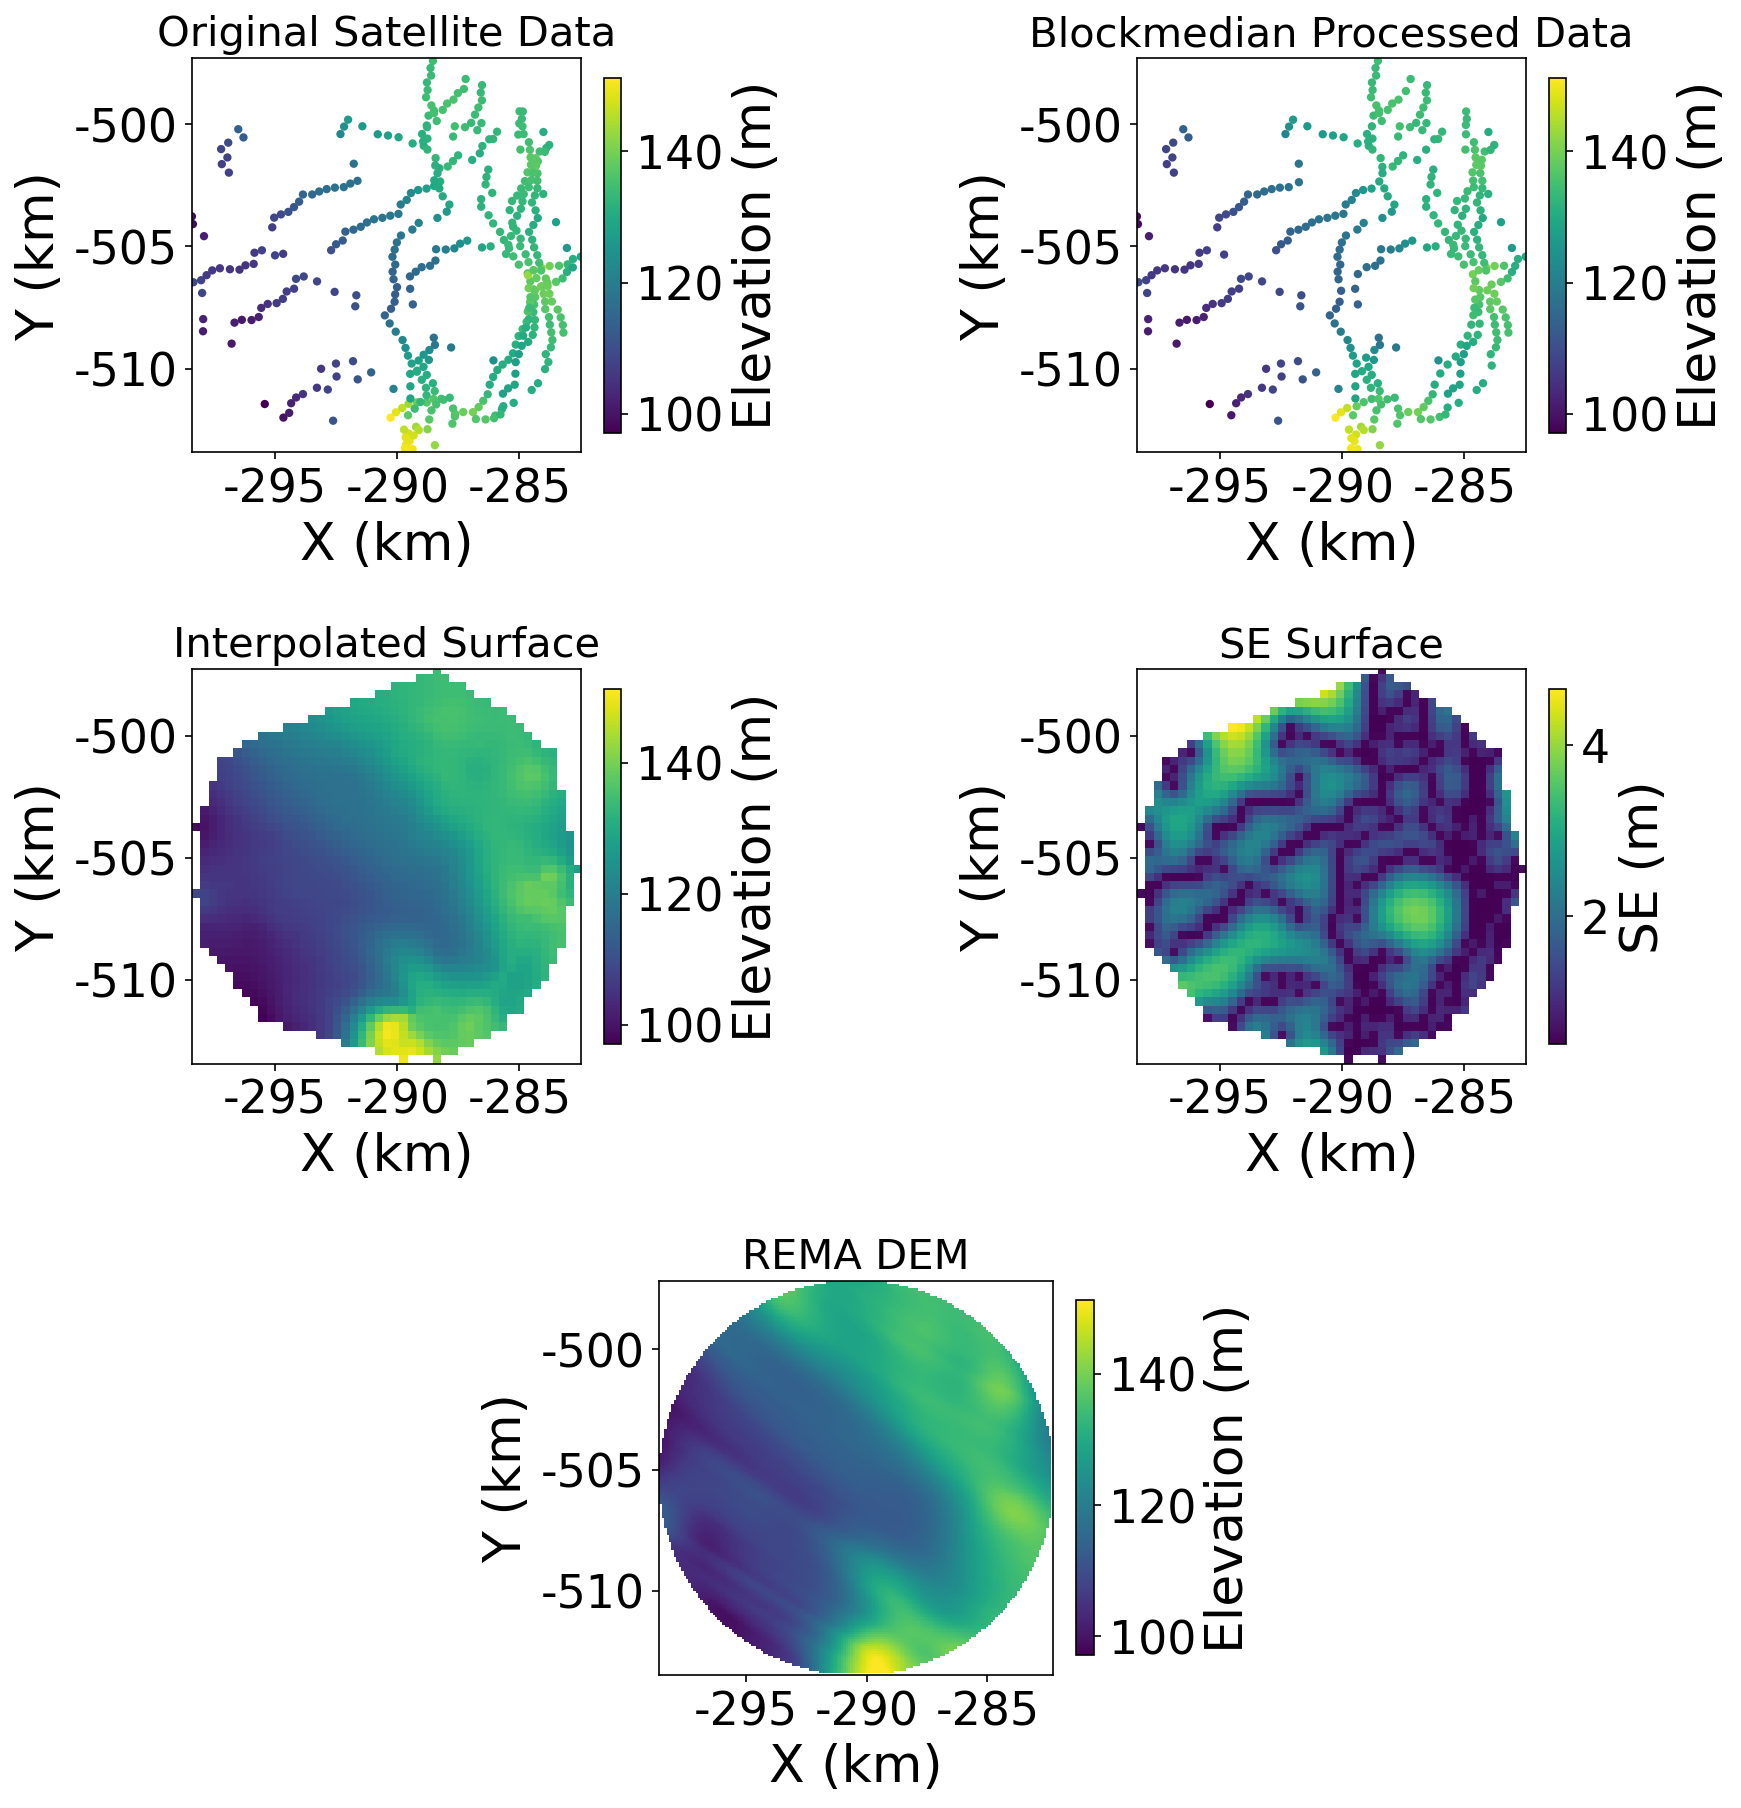

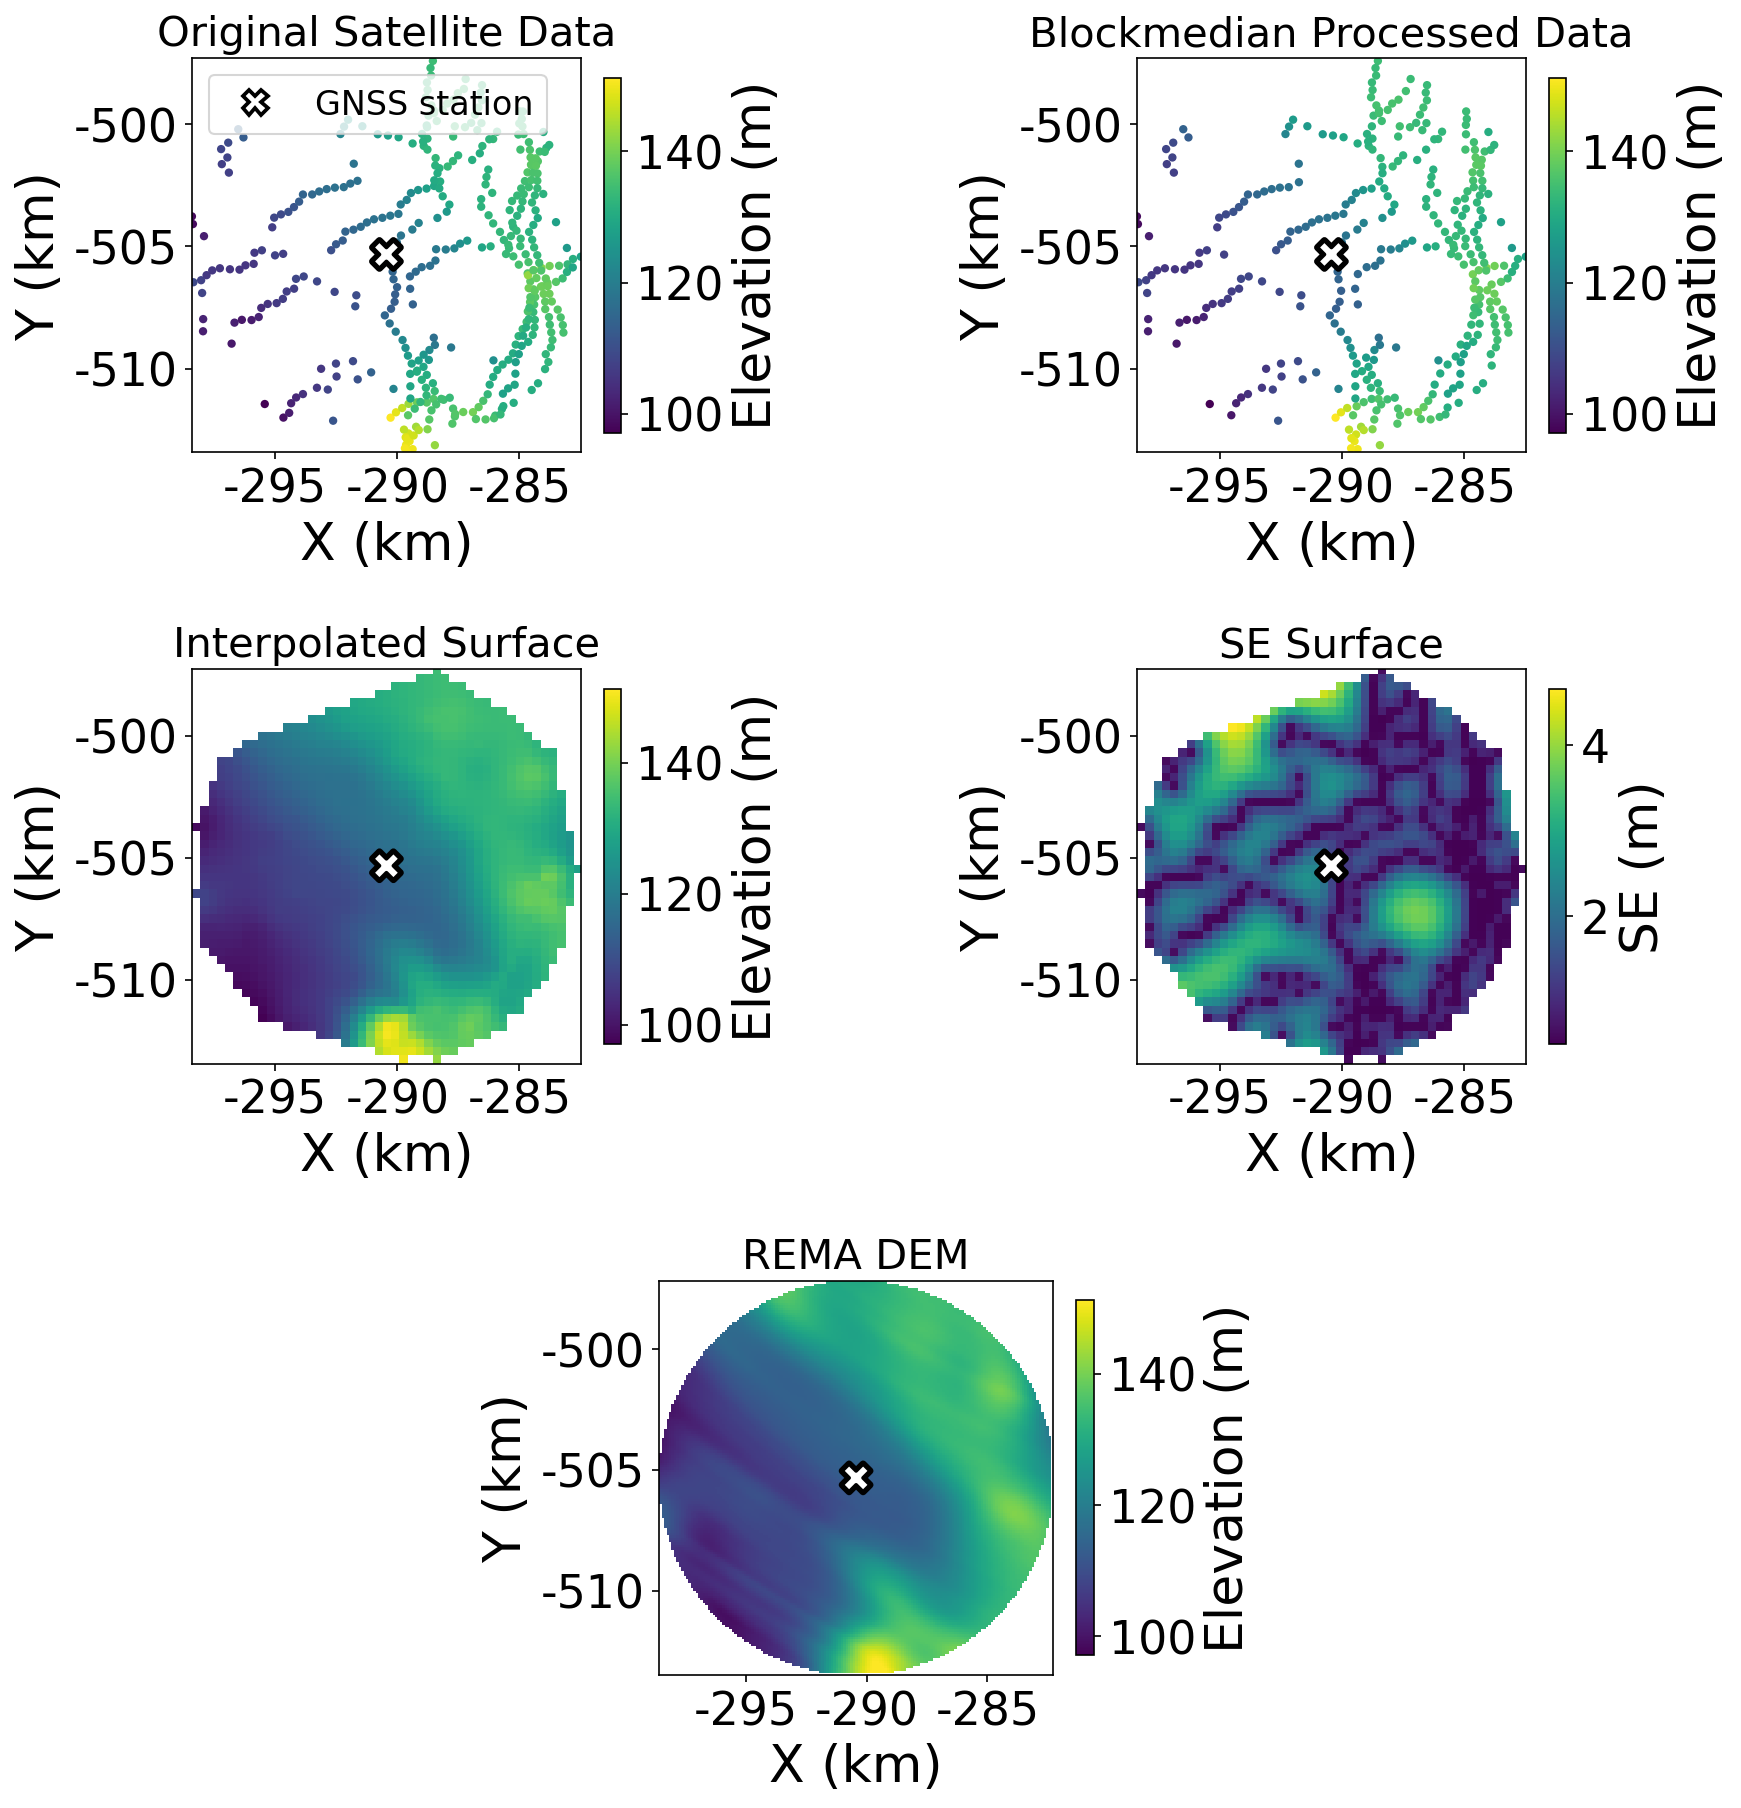

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import matplotlib.patheffects as pe
import rasterio
from rasterio.windows import from_bounds

# ============================================================
# USER INPUTS
# ============================================================
orig_csv = Path("data/interpflow/la02_poca_2011-01-25_original_satellite_subset.csv")
bmed_csv = Path("data/interpflow/la02_poca_2011-01-25_block_median_0p10x_arange.csv")
interp_grid_csv = Path("data/interpflow/la02_poca_2011-01-25_kriging_prediction_surface.csv")
se_grid_csv = Path("data/interpflow/la02_poca_2011-01-25_kriging_standard_error_surface.csv")
rema_tif = Path("data/interpflow/rema_antarctica_la02_poca_2011-01-25_window_clip.tif")

# Fixed GNSS / interpolation location
X_MID = -290443.866292339
Y_MID = -505325.8126345371
RADIUS_M = 8172.76103962287
FIGSIZE = (18, 14)
CMAP = "viridis"
TITLE_SIZE = 20
PLOT_ALPHA = 1.0

# Optional export controls
EXPORT_FIGURES = True
OUT_DIR = Path("outputs/figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_NO_X = OUT_DIR / "LA02_POCA_2x2_plus_rema_no_station_x.png"
FIG_WITH_X = OUT_DIR / "LA02_POCA_2x2_plus_rema_with_station_x.png"

# ------------------------------------------------------------
# Axis scale display
# Ticks will be divided by this number, but data remain in meters
# ------------------------------------------------------------
AXIS_SCALE = 1e3
X_LABEL = r"X (km)"
Y_LABEL = r"Y (km)"

# Point styling
SAT_POINT_SIZE = 16

# GNSS marker styling
GNSS_MARKER = "X"
GNSS_SIZE = 180
GNSS_FACE = "white"
GNSS_EDGE = "black"
GNSS_LINEWIDTH = 1.8
GNSS_ZORDER = 10

# Layout tuning
WSPACE = -0.30
HSPACE = 0.55

# ============================================================
# READERS
# ============================================================
def read_original_satellite_csv(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path, skiprows=24)
    # The exported files sometimes have spaces around column names.
    clean_columns = []
    for column in df.columns:
        clean_columns.append(column.strip())
    df.columns = clean_columns
    return df

def read_blockmedian_csv(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path, skiprows=32)
    # The exported files sometimes have spaces around column names.
    clean_columns = []
    for column in df.columns:
        clean_columns.append(column.strip())
    df.columns = clean_columns
    return df

def read_grid_csv(grid_csv: Path) -> pd.DataFrame:
    df = pd.read_csv(grid_csv)
    # The exported files sometimes have spaces around column names.
    clean_columns = []
    for column in df.columns:
        clean_columns.append(column.strip())
    df.columns = clean_columns
    return df

# ============================================================
# LOAD
# ============================================================
orig_df = read_original_satellite_csv(orig_csv)
bmed_df = read_blockmedian_csv(bmed_csv)
interp_df = read_grid_csv(interp_grid_csv)
se_df = read_grid_csv(se_grid_csv)

# ============================================================
# CHECKS / CLEANING
# ============================================================
required_orig = {"x", "y", "elevation"}
required_bmed = {"x", "y", "elevation"}
required_interp = {"x", "y", "elevation"}
if not required_orig.issubset(orig_df.columns):
    raise ValueError(f"Original CSV missing required columns. Found: {list(orig_df.columns)}")
if not required_bmed.issubset(bmed_df.columns):
    raise ValueError(f"Blockmedian CSV missing required columns. Found: {list(bmed_df.columns)}")
if not required_interp.issubset(interp_df.columns):
    raise ValueError(f"Interpolation grid missing required columns. Found: {list(interp_df.columns)}")
se_col = None
for candidate in ["se", "SE", "std_error", "standard_error"]:
    if candidate in se_df.columns:
        se_col = candidate
        break
if se_col is None:
    raise ValueError(f"SE grid provided, but no SE column found. Columns: {list(se_df.columns)}")
for df in [orig_df, bmed_df]:
    for col in ["x", "y", "elevation"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
for col in ["x", "y", "elevation"]:
    interp_df[col] = pd.to_numeric(interp_df[col], errors="coerce")
for col in ["x", "y", se_col]:
    se_df[col] = pd.to_numeric(se_df[col], errors="coerce")
orig_df = orig_df.dropna(subset=["x", "y", "elevation"]).copy()
bmed_df = bmed_df.dropna(subset=["x", "y", "elevation"]).copy()
interp_df = interp_df.dropna(subset=["x", "y", "elevation"]).copy()
se_df = se_df.dropna(subset=["x", "y", se_col]).copy()

# ============================================================
# GLOBAL AXIS LIMITS FOR ORIGINAL 4 PANELS ONLY
# ============================================================
x_all = np.concatenate([
    orig_df["x"].to_numpy(),
    bmed_df["x"].to_numpy(),
    interp_df["x"].to_numpy(),
    se_df["x"].to_numpy(),
    np.array([X_MID])
])
y_all = np.concatenate([
    orig_df["y"].to_numpy(),
    bmed_df["y"].to_numpy(),
    interp_df["y"].to_numpy(),
    se_df["y"].to_numpy(),
    np.array([Y_MID])
])
xmin, xmax = np.nanmin(x_all), np.nanmax(x_all)
ymin, ymax = np.nanmin(y_all), np.nanmax(y_all)

# ============================================================
# REMA BOUNDING BOX
# ============================================================
rema_xmin = X_MID - RADIUS_M
rema_xmax = X_MID + RADIUS_M
rema_ymin = Y_MID - RADIUS_M
rema_ymax = Y_MID + RADIUS_M

# ============================================================
# GLOBAL COLOR LIMITS
# REMA WILL USE SAME ELEVATION NORMALIZATION
# ============================================================
elev_all = np.concatenate([
    orig_df["elevation"].to_numpy(),
    bmed_df["elevation"].to_numpy(),
    interp_df["elevation"].to_numpy()
])
elev_vmin = np.nanmin(elev_all)
elev_vmax = np.nanmax(elev_all)
elev_norm = Normalize(vmin=elev_vmin, vmax=elev_vmax)
se_vmin = np.nanmin(se_df[se_col].to_numpy())
se_vmax = np.nanmax(se_df[se_col].to_numpy())
se_norm = Normalize(vmin=se_vmin, vmax=se_vmax)

# ============================================================
# HELPERS
# ============================================================
def scaled_tick_formatter(scale):
    # Show the coordinates in km while leaving the plotted data in meters.
    def format_tick(value, position):
        return f"{value / scale:g}"
    return FuncFormatter(format_tick)

def add_gnss_marker(ax, x_mid, y_mid):
    pt = ax.scatter(
        x_mid, y_mid,
        marker=GNSS_MARKER,
        s=GNSS_SIZE,
        c=GNSS_FACE,
        edgecolors=GNSS_EDGE,
        linewidths=GNSS_LINEWIDTH,
        zorder=GNSS_ZORDER
    )
    pt.set_path_effects([
        pe.Stroke(linewidth=GNSS_LINEWIDTH + 1.5, foreground="black"),
        pe.Normal()
    ])
    return pt

def add_gnss_legend(ax):
    handle = Line2D(
        [0], [0],
        marker=GNSS_MARKER,
        linestyle="None",
        markerfacecolor=GNSS_FACE,
        markeredgecolor=GNSS_EDGE,
        markeredgewidth=GNSS_LINEWIDTH,
        markersize=12,
        label="GNSS station"
    )
    ax.legend(handles=[handle], loc="upper left", frameon=True)

def format_map_axis(ax, title):
    ax.set_title(title, fontsize=TITLE_SIZE)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_formatter(scaled_tick_formatter(AXIS_SCALE))
    ax.yaxis.set_major_formatter(scaled_tick_formatter(AXIS_SCALE))

def format_rema_axis(ax, title):
    ax.set_title(title, fontsize=TITLE_SIZE)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    ax.set_xlim(rema_xmin, rema_xmax)
    ax.set_ylim(rema_ymin, rema_ymax)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_formatter(scaled_tick_formatter(AXIS_SCALE))
    ax.yaxis.set_major_formatter(scaled_tick_formatter(AXIS_SCALE))

def plot_gridded_surface(ax, df, xcol, ycol, value_col, title, cmap="viridis", norm=None):
    grid = df.pivot(index=ycol, columns=xcol, values=value_col)
    grid = grid.sort_index(axis=0).sort_index(axis=1)
    X = grid.columns.to_numpy(dtype=float)
    Y = grid.index.to_numpy(dtype=float)
    Z = grid.to_numpy(dtype=float)
    XX, YY = np.meshgrid(X, Y)
    m = ax.pcolormesh(
        XX, YY, Z,
        shading="auto",
        cmap=cmap,
        norm=norm
    )
    format_map_axis(ax, title)
    return m

def read_rema_subset_circle(tif_path, x_mid, y_mid, radius_m):
    """
    Read REMA over the square bounding box of the circle,
    then mask all pixels outside the circle.
    """
    xmin_box = x_mid - radius_m
    xmax_box = x_mid + radius_m
    ymin_box = y_mid - radius_m
    ymax_box = y_mid + radius_m
    with rasterio.open(tif_path) as src:
        win = from_bounds(xmin_box, ymin_box, xmax_box, ymax_box, src.transform)
        win = win.round_offsets().round_lengths()
        data = src.read(1, window=win, masked=True)
        transform = src.window_transform(win)
        if src.nodata is not None:
            data = np.ma.masked_equal(data, src.nodata)
        nrows, ncols = data.shape
        cols = np.arange(ncols)
        rows = np.arange(nrows)
        xs = transform.c + (cols + 0.5) * transform.a
        ys = transform.f + (rows + 0.5) * transform.e
        XX, YY = np.meshgrid(xs, ys)
        dist = np.sqrt((XX - x_mid) ** 2 + (YY - y_mid) ** 2)
        circle_mask = dist > radius_m
        data = np.ma.masked_where(circle_mask, data)
        left = transform.c
        top = transform.f
        right = left + ncols * transform.a
        bottom = top + nrows * transform.e
        extent = [left, right, bottom, top]
    return data, extent

def plot_rema_circle(ax, tif_path, title="REMA DEM", cmap="viridis", norm=None):
    rema_data, rema_extent = read_rema_subset_circle(
        tif_path=tif_path,
        x_mid=X_MID,
        y_mid=Y_MID,
        radius_m=RADIUS_M
    )
    m = ax.imshow(
        rema_data,
        extent=rema_extent,
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )
    format_rema_axis(ax, title)
    return m

# ============================================================
# FIGURE MAKER
# ============================================================
def make_centered_rema_figure(with_station_x=False):
    fig = plt.figure(figsize=FIGSIZE, constrained_layout=False)
    gs = fig.add_gridspec(
        3, 4,
        wspace=WSPACE,
        hspace=HSPACE
    )

    # Top 2x2
    ax00 = fig.add_subplot(gs[0, 0:2])
    ax01 = fig.add_subplot(gs[0, 2:4])
    ax10 = fig.add_subplot(gs[1, 0:2])
    ax11 = fig.add_subplot(gs[1, 2:4])

    # Bottom centered REMA
    ax20 = fig.add_subplot(gs[2, 1:3])

    # Panel 1: original
    m0 = ax00.scatter(
        orig_df["x"], orig_df["y"],
        c=orig_df["elevation"],
        s=SAT_POINT_SIZE,
        cmap=CMAP,
        norm=elev_norm,
        linewidths=0,
        alpha=PLOT_ALPHA
    )
    format_map_axis(ax00, "Original Satellite Data")
    if with_station_x:
        add_gnss_marker(ax00, X_MID, Y_MID)
        add_gnss_legend(ax00)
    cbar0 = fig.colorbar(m0, ax=ax00, shrink=0.9, pad=0.02)
    cbar0.set_label("Elevation (m)")

    # Panel 2: blockmedian
    m1 = ax01.scatter(
        bmed_df["x"], bmed_df["y"],
        c=bmed_df["elevation"],
        s=SAT_POINT_SIZE,
        cmap=CMAP,
        norm=elev_norm,
        linewidths=0,
        alpha=PLOT_ALPHA
    )
    format_map_axis(ax01, "Blockmedian Processed Data")
    if with_station_x:
        add_gnss_marker(ax01, X_MID, Y_MID)
    cbar1 = fig.colorbar(m1, ax=ax01, shrink=0.9, pad=0.02)
    cbar1.set_label("Elevation (m)")

    # Panel 3: prediction surface
    m2 = plot_gridded_surface(
        ax10,
        interp_df,
        xcol="x",
        ycol="y",
        value_col="elevation",
        title="Interpolated Surface",
        cmap=CMAP,
        norm=elev_norm
    )
    if with_station_x:
        add_gnss_marker(ax10, X_MID, Y_MID)
    cbar2 = fig.colorbar(m2, ax=ax10, shrink=0.9, pad=0.02)
    cbar2.set_label("Elevation (m)")

    # Panel 4: SE surface
    m3 = plot_gridded_surface(
        ax11,
        se_df,
        xcol="x",
        ycol="y",
        value_col=se_col,
        title="SE Surface",
        cmap=CMAP,
        norm=se_norm
    )
    if with_station_x:
        add_gnss_marker(ax11, X_MID, Y_MID)
    cbar3 = fig.colorbar(m3, ax=ax11, shrink=0.9, pad=0.02)
    cbar3.set_label("SE (m)")

    # Bottom centered REMA
    m4 = plot_rema_circle(
        ax20,
        rema_tif,
        title="REMA DEM",
        cmap=CMAP,
        norm=elev_norm
    )
    if with_station_x:
        add_gnss_marker(ax20, X_MID, Y_MID)
    cbar4 = fig.colorbar(m4, ax=ax20, shrink=0.9, pad=0.02)
    cbar4.set_label("Elevation (m)")
    return fig

# ============================================================
# FIGURE 1: NO STATION X
# ============================================================
fig1 = make_centered_rema_figure(with_station_x=False)
if EXPORT_FIGURES:
    fig1.savefig(FIG_NO_X, dpi=600, bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE 2: WITH STATION X
# ============================================================
fig2 = make_centered_rema_figure(with_station_x=True)
if EXPORT_FIGURES:
    fig2.savefig(FIG_WITH_X, dpi=600, bbox_inches="tight")
plt.show()
